In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylabdd as dd
from scipy.signal import savgol_filter

#define system parameters
maxout = 1000
temp = 600.0
tau0 = 200.0
lgb = 0.1
grain_size = 1.0
tfin = 3.0e8
niter = 500_000_000
dtmax = 1.e0
drag = 500
#ngbn = 41 #int(lgb/delta)
#if ngbn % 2 == 0: ngbn += 1

#define parameter to be varied
nlist = [11, 21, 31, 41]
Np = len(nlist)
flist = ["pu_tau200_T600_N11", 
         "pu_tau200_T600_N21", 
         "pu_tau200_T600_N31", 
         "pu_tau200_T600_N41"]
Np = len(flist)

# initialize arrays to store individual simulation results
psr_av = np.zeros((Np, maxout))
gplast = np.zeros((Np, maxout))
sim_time = np.zeros((Np, maxout))
nit = np.zeros(Np, dtype=int)
Ngb_list = np.zeros(Np, dtype=int)



Running system command with arguments
   gfortran PK_force.f90 PK_force_c_wrapper.f90 -fPIC -shared -O3 -o PK_force.arm64.so


ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored
ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored




Running system command with arguments
   gfortran mod_gbdd.f90 mod_gbdd_c_wrapper.f90 -fPIC -shared -O3 -o mod_gbdd.arm64.so


ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored
ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored


Data file with N_gbn=11, delta=0.1, dtmax=1.0


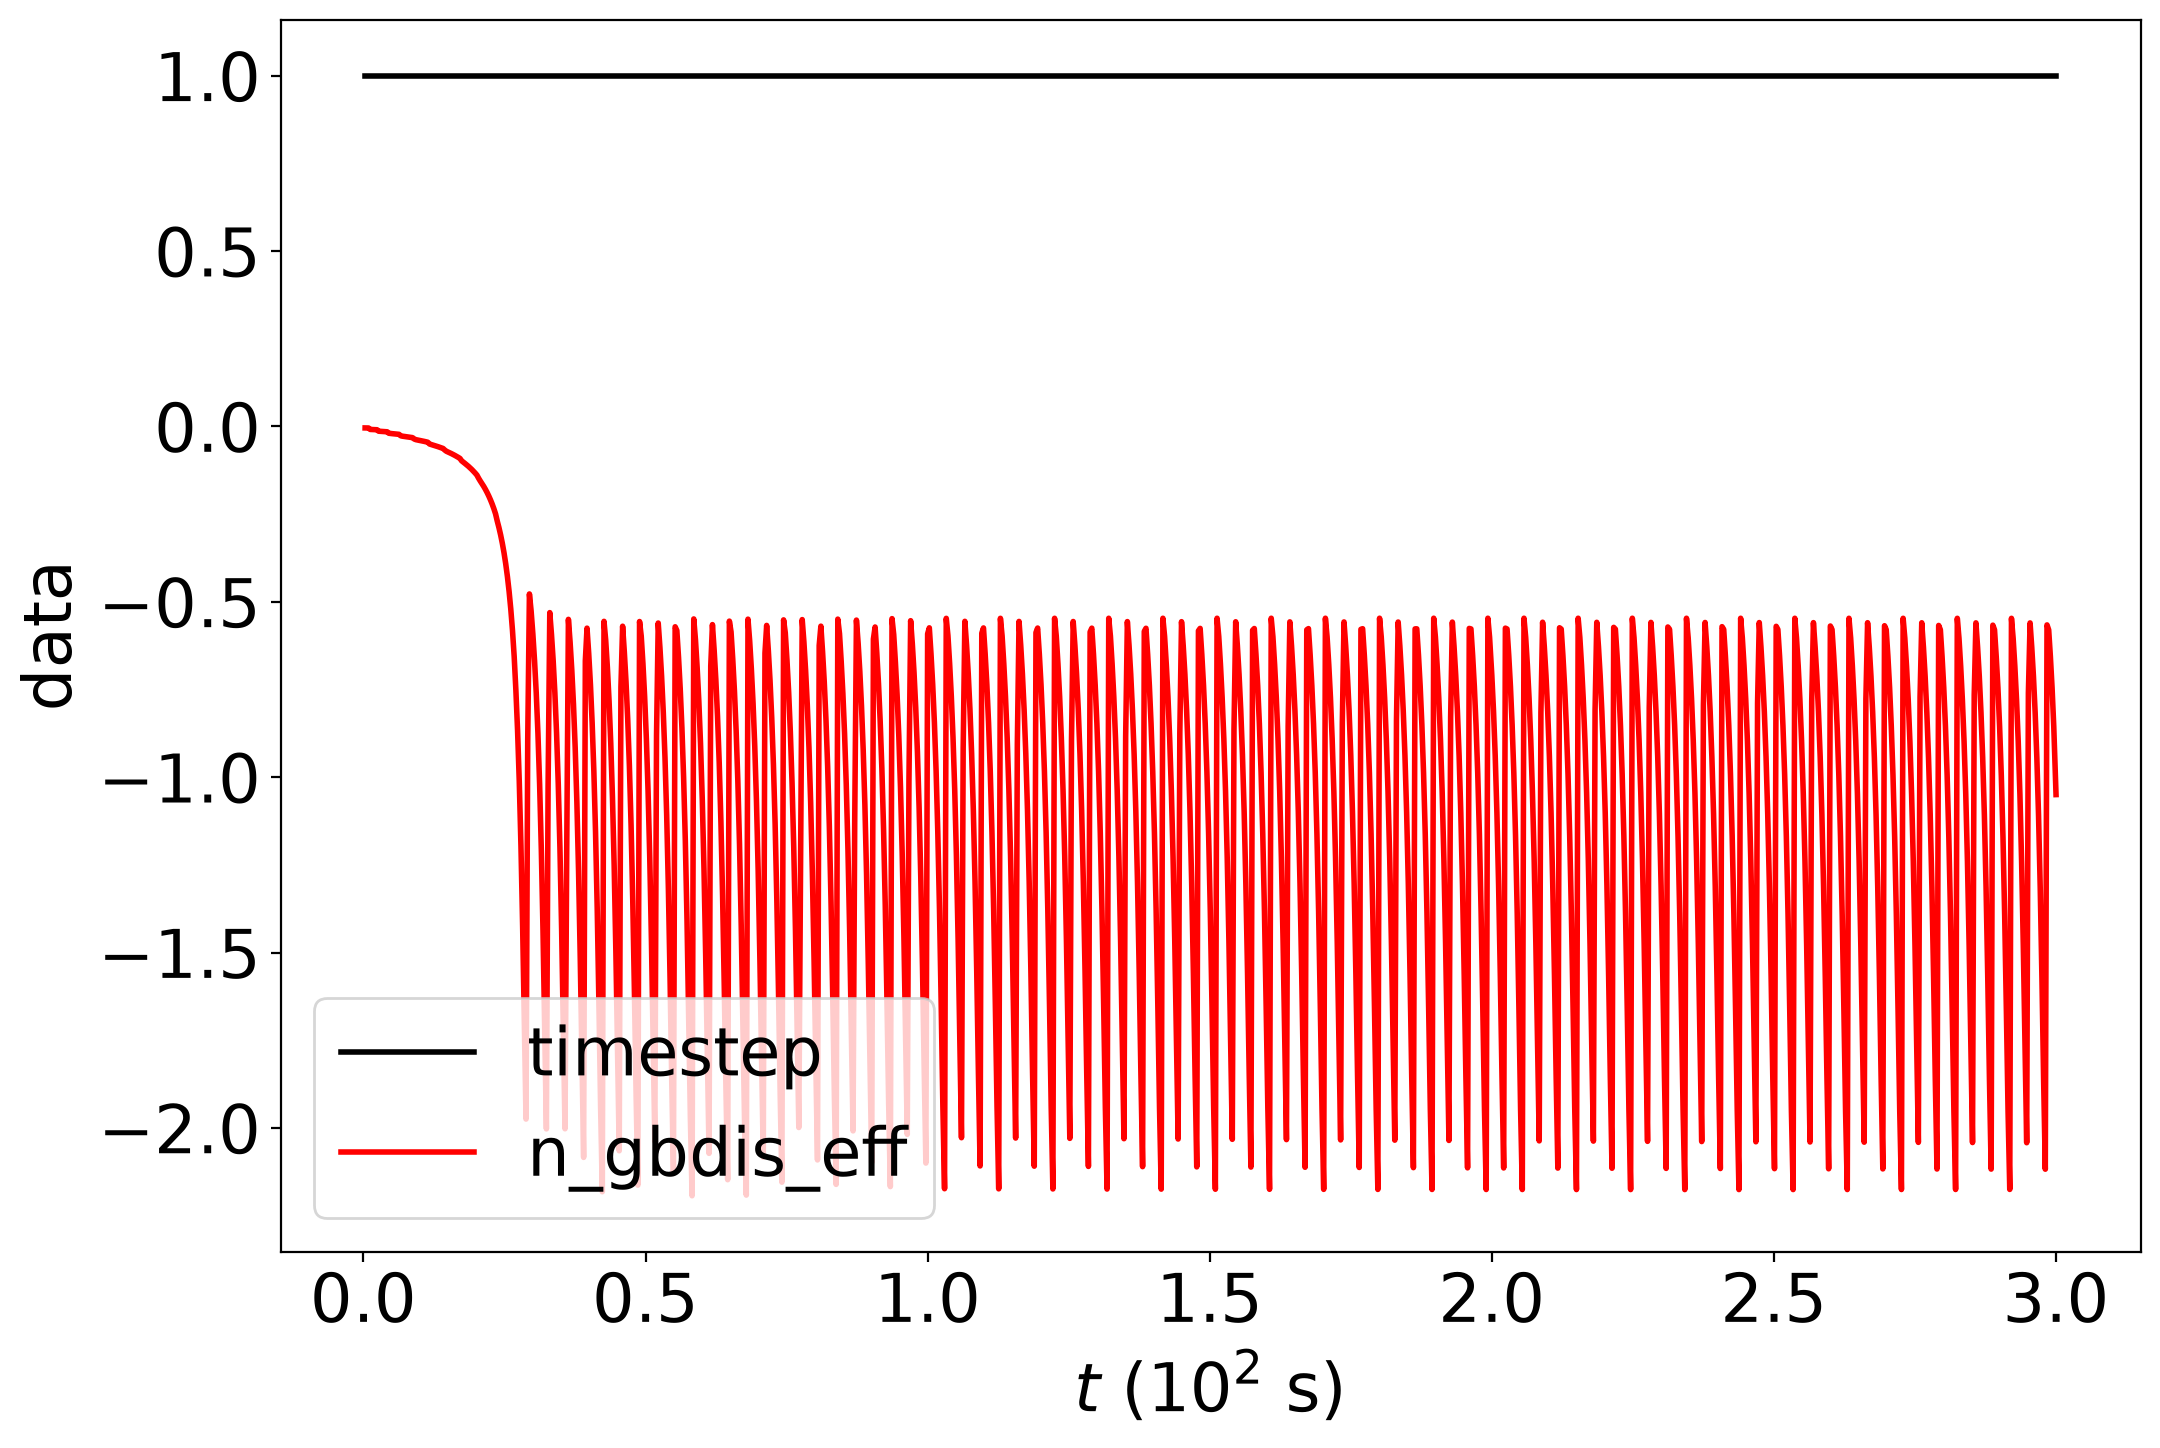

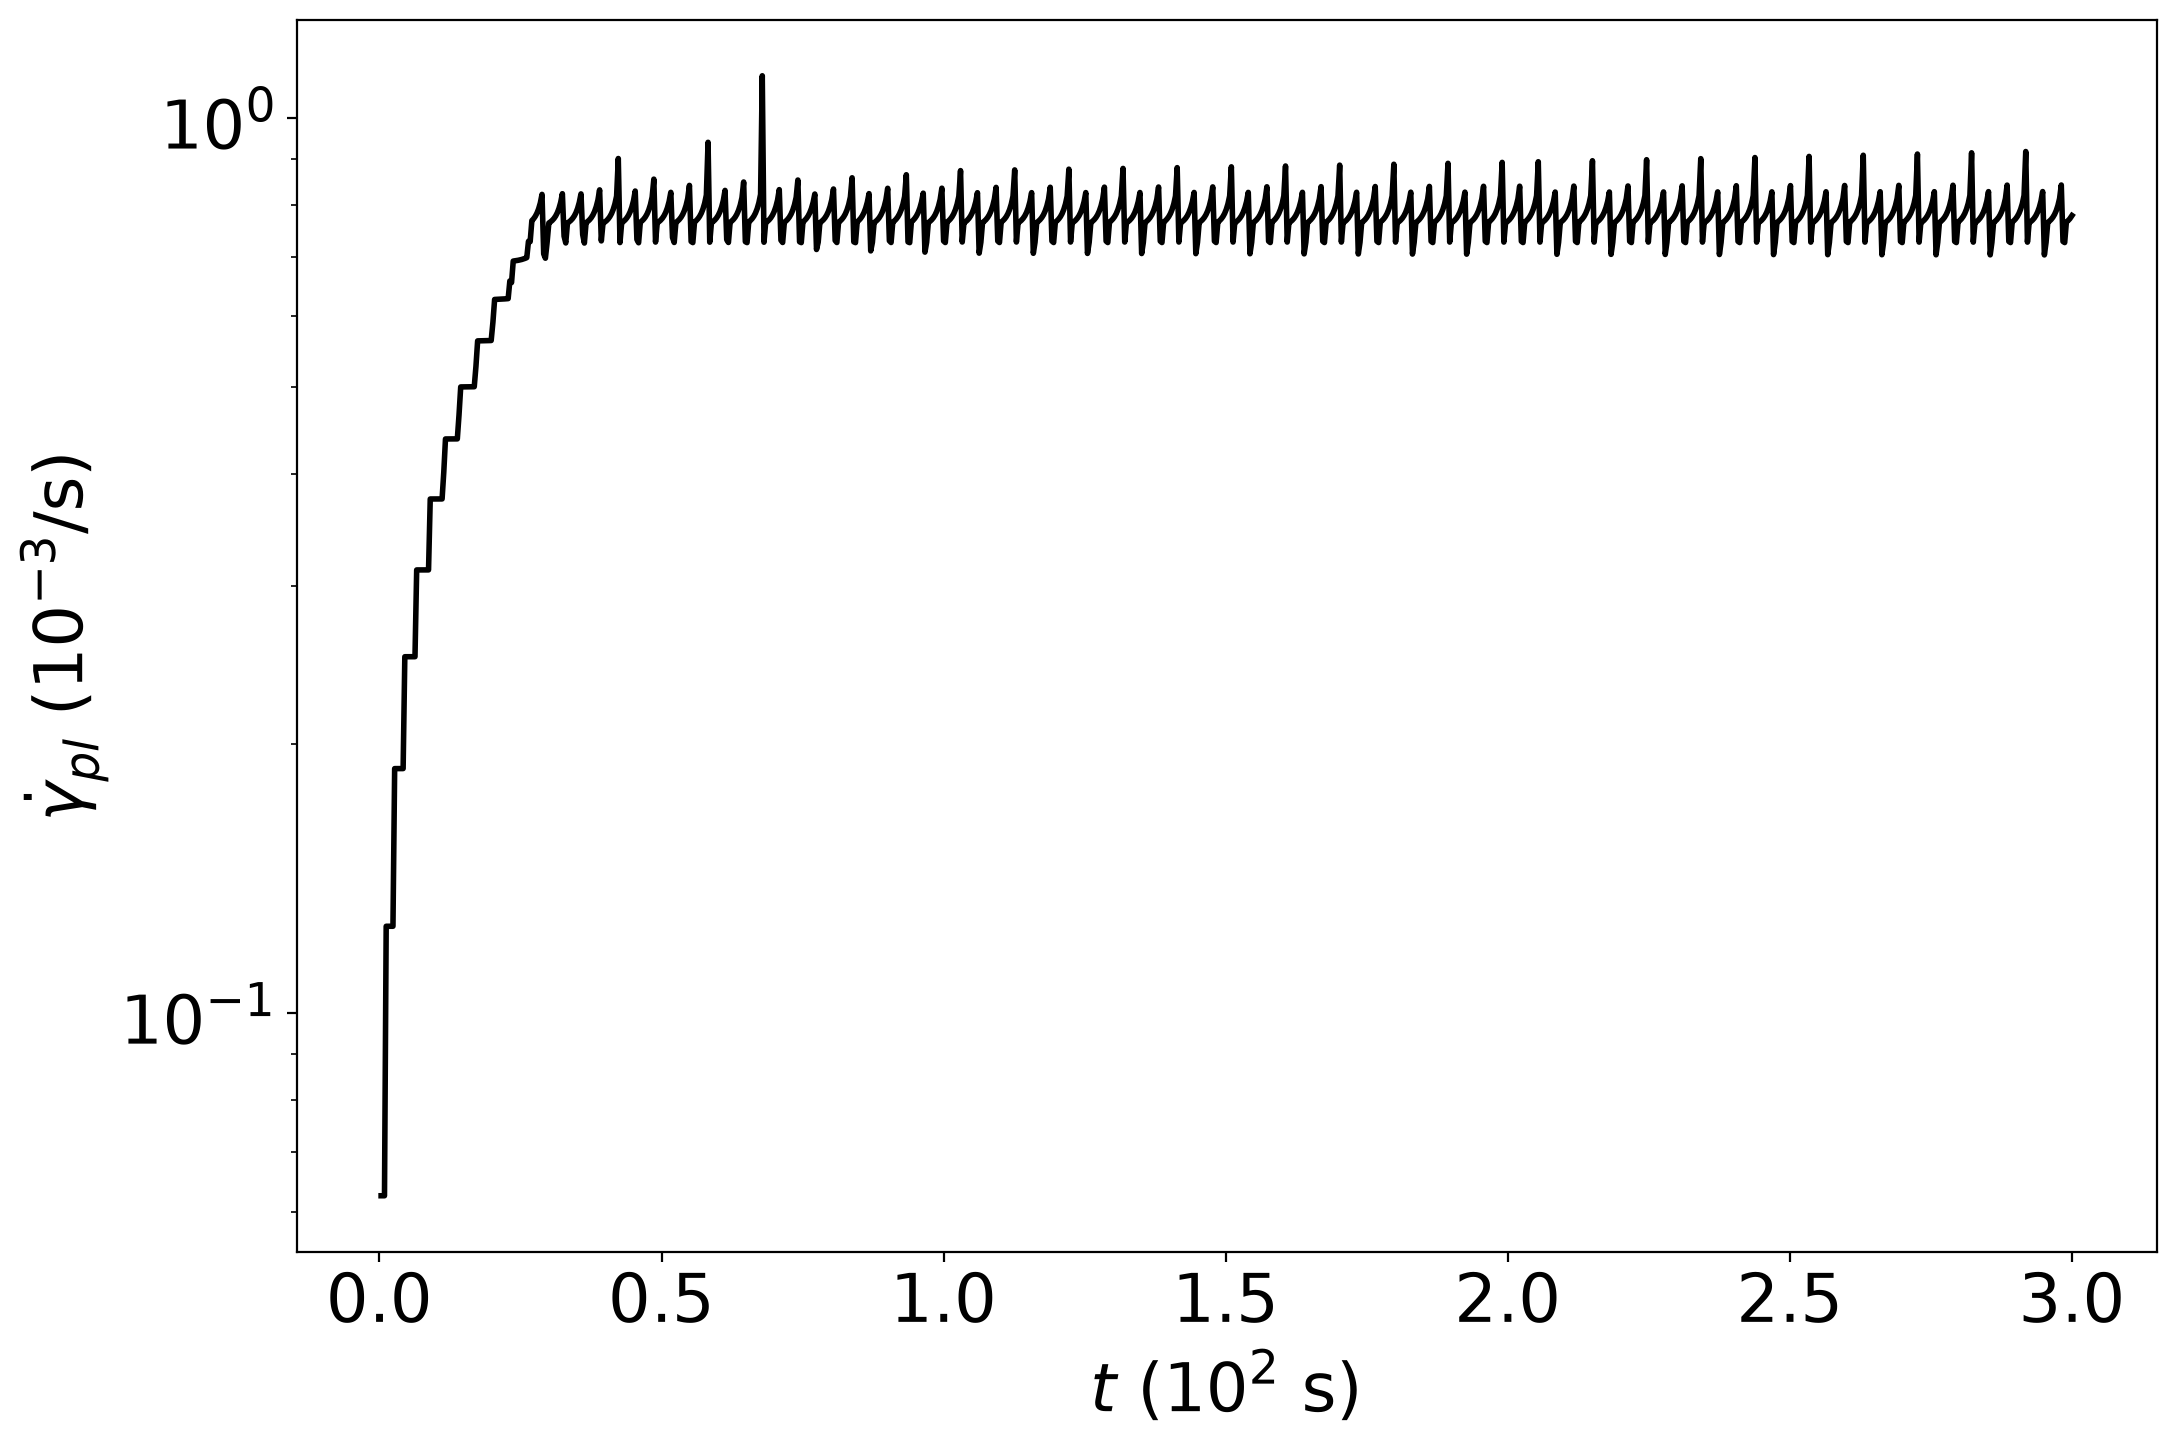

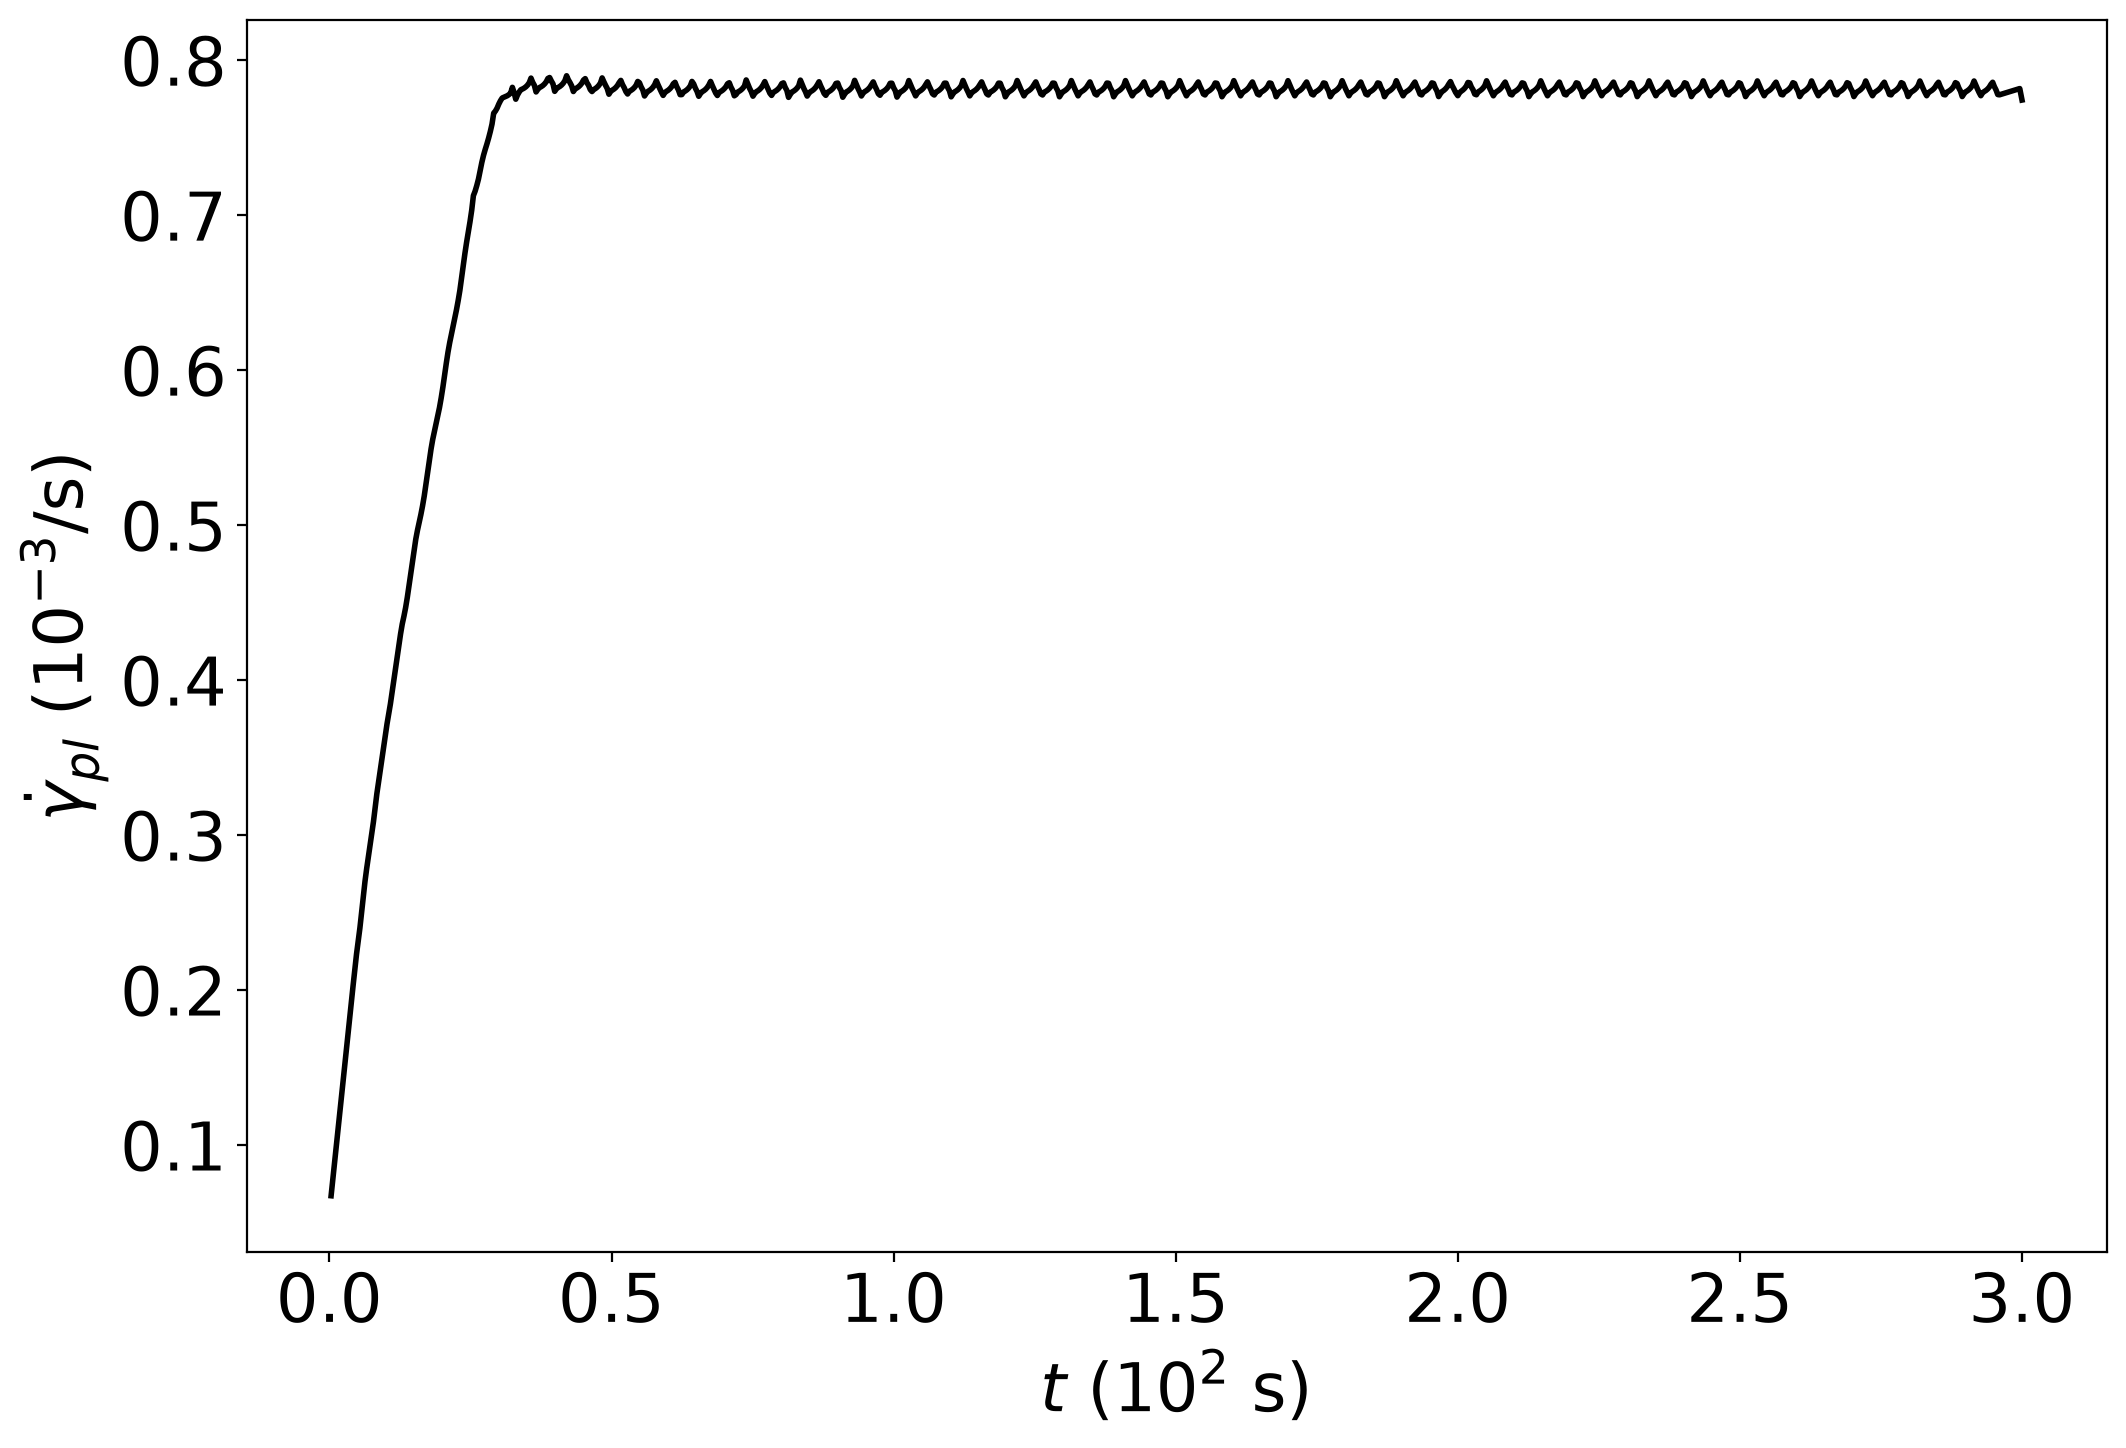

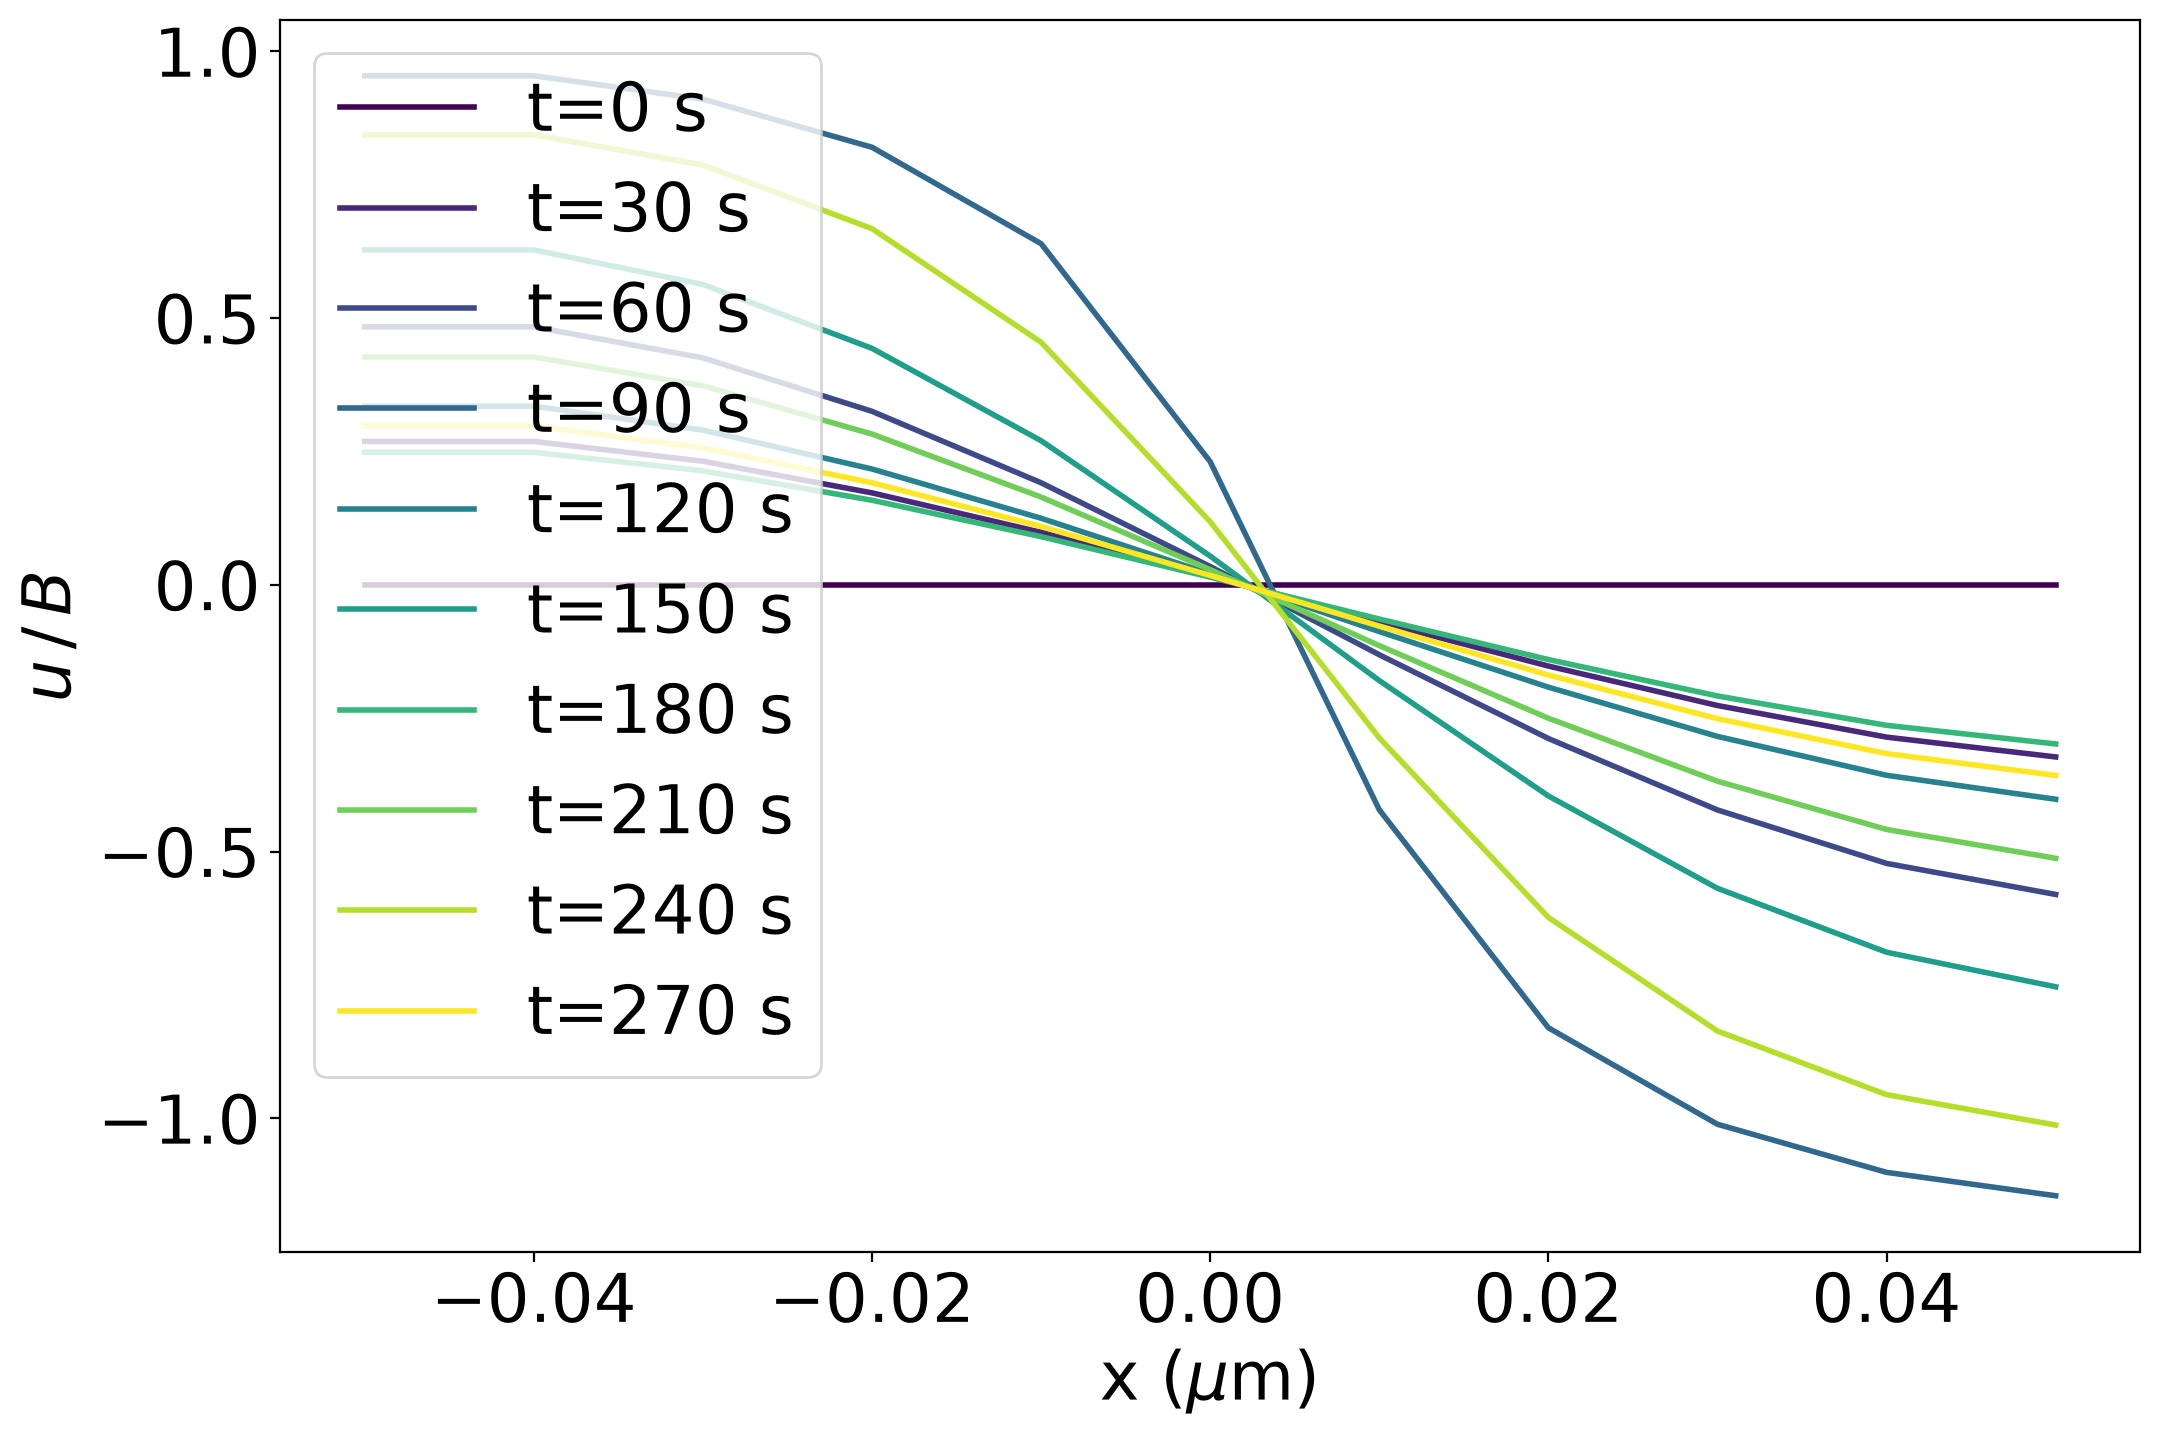

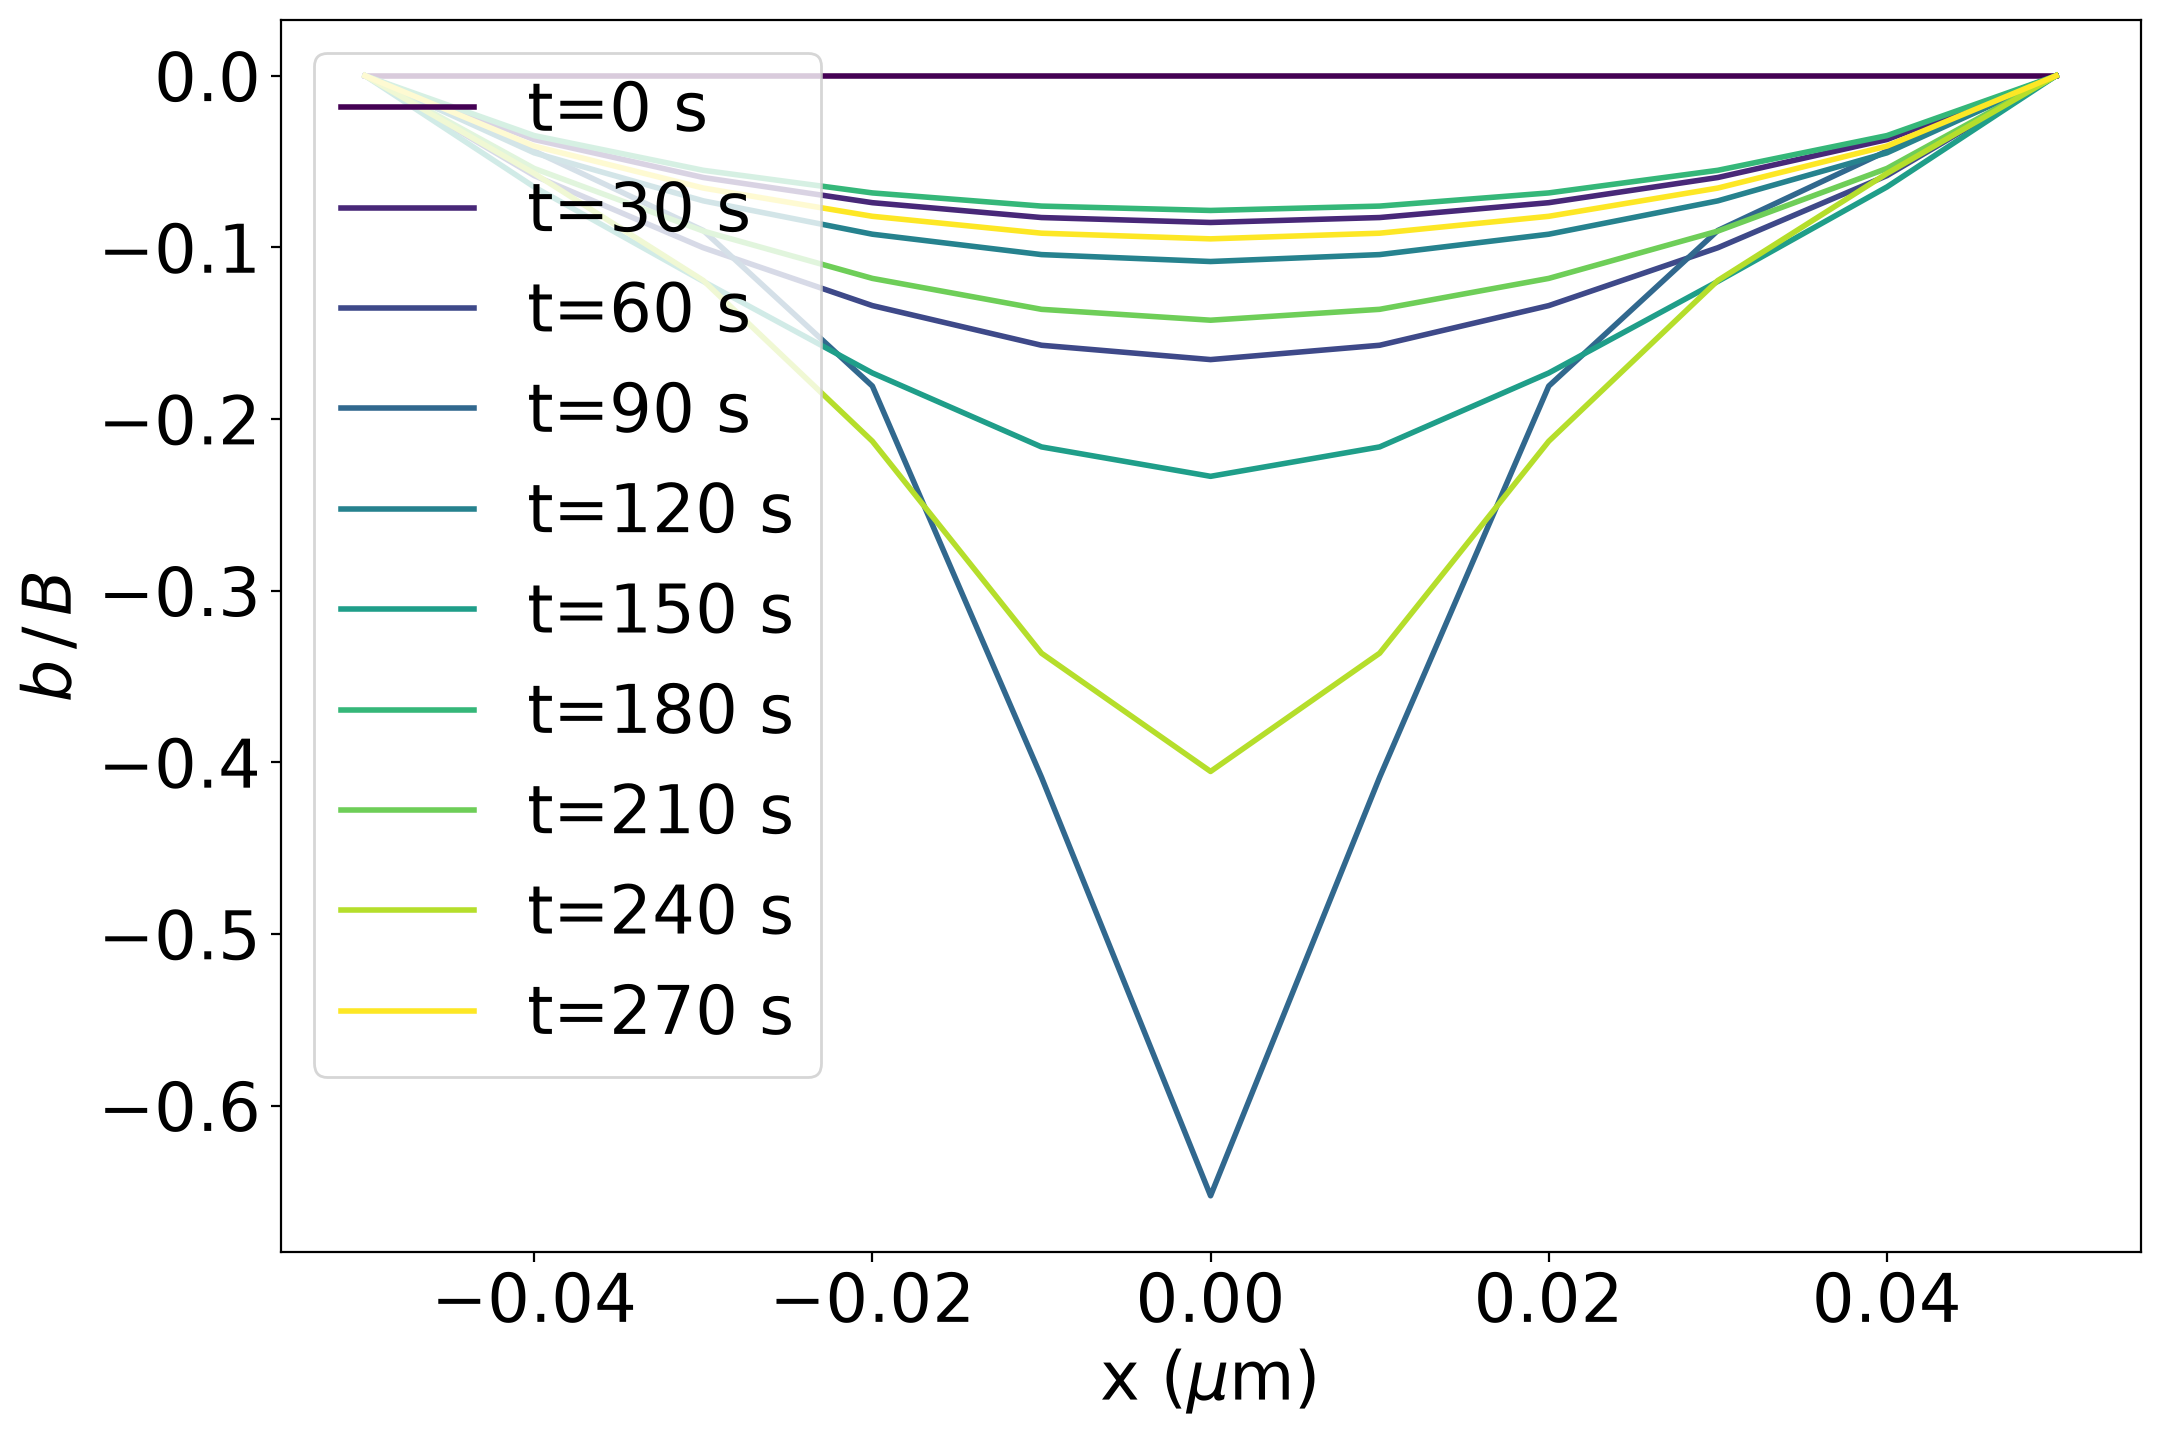

Data file with N_gbn=21, delta=0.1, dtmax=1.0


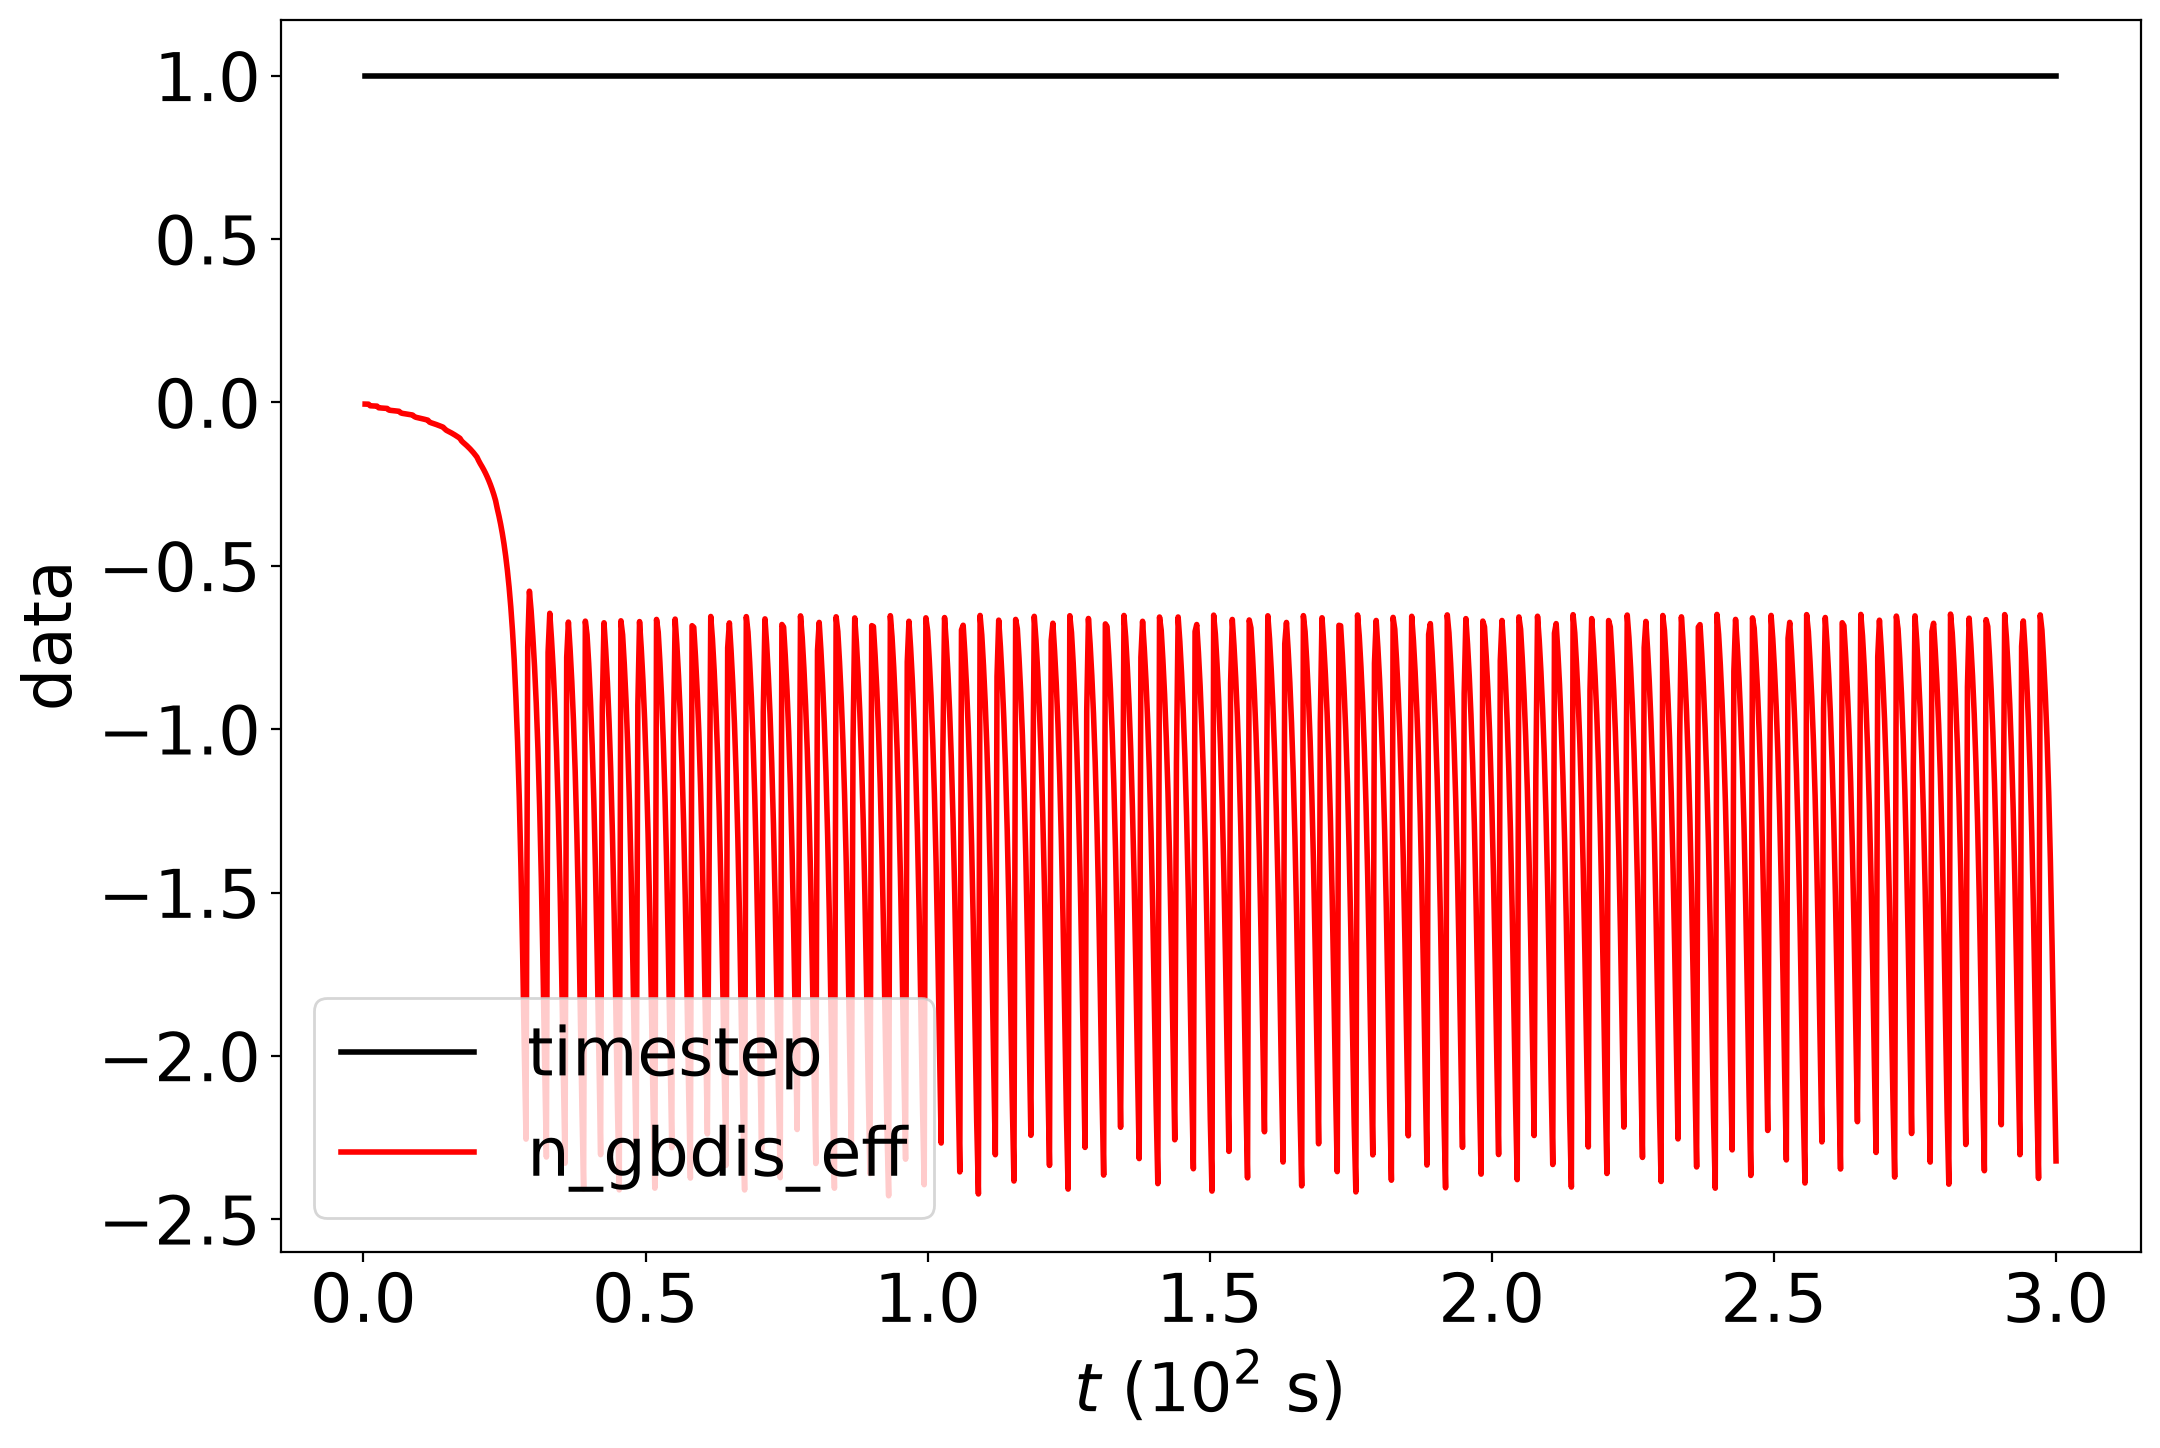

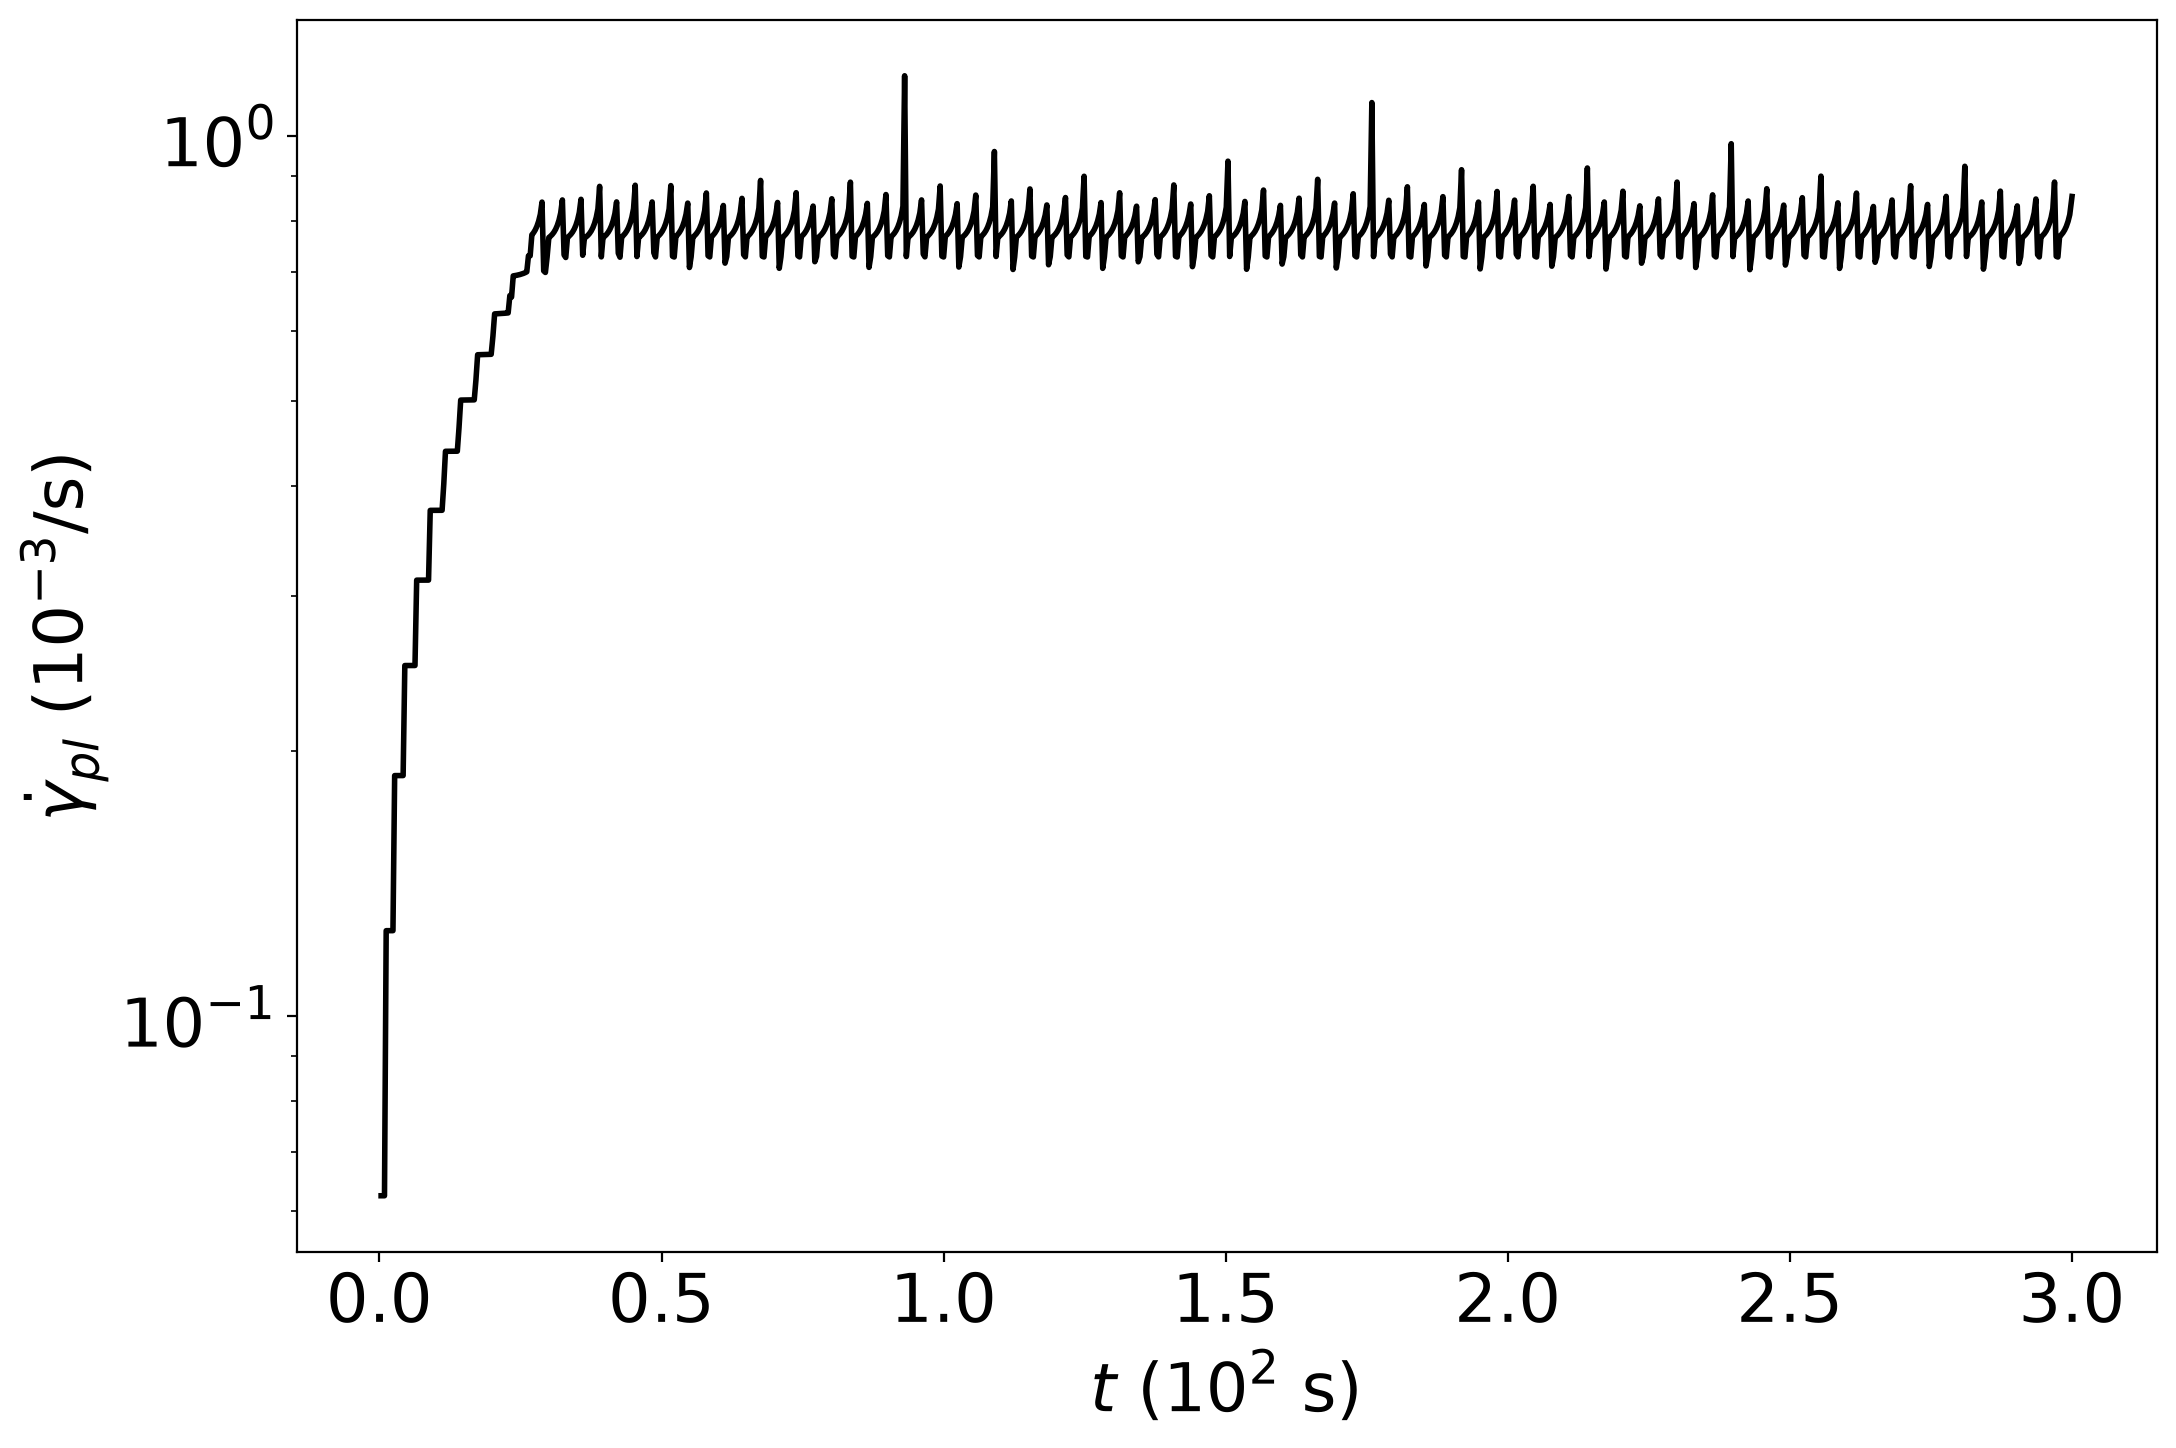

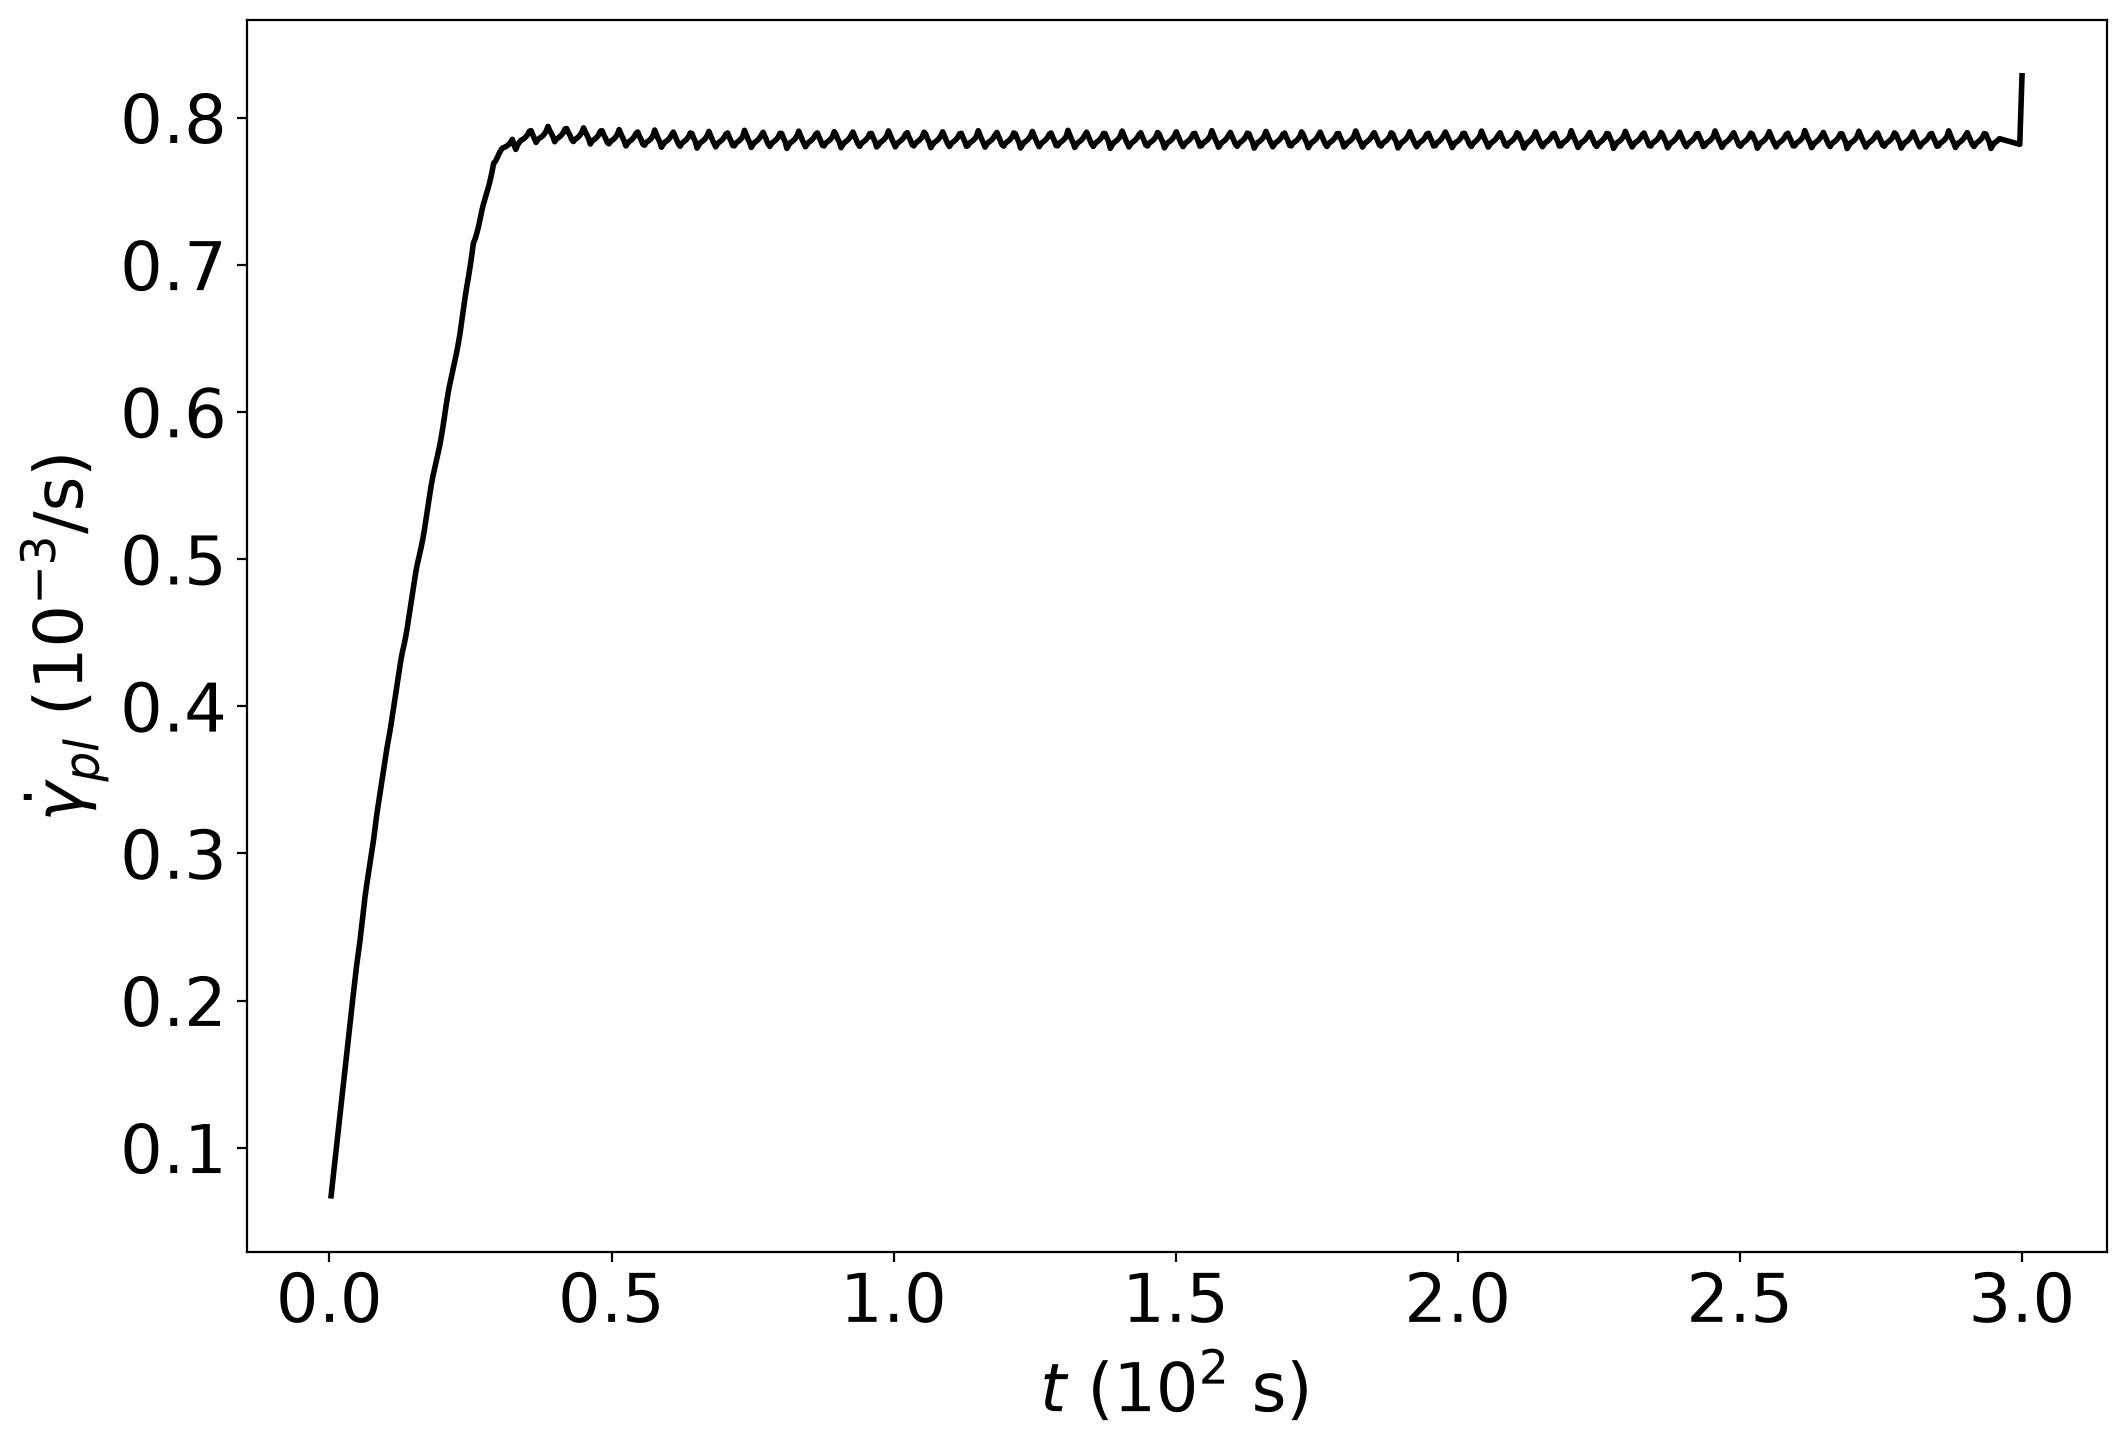

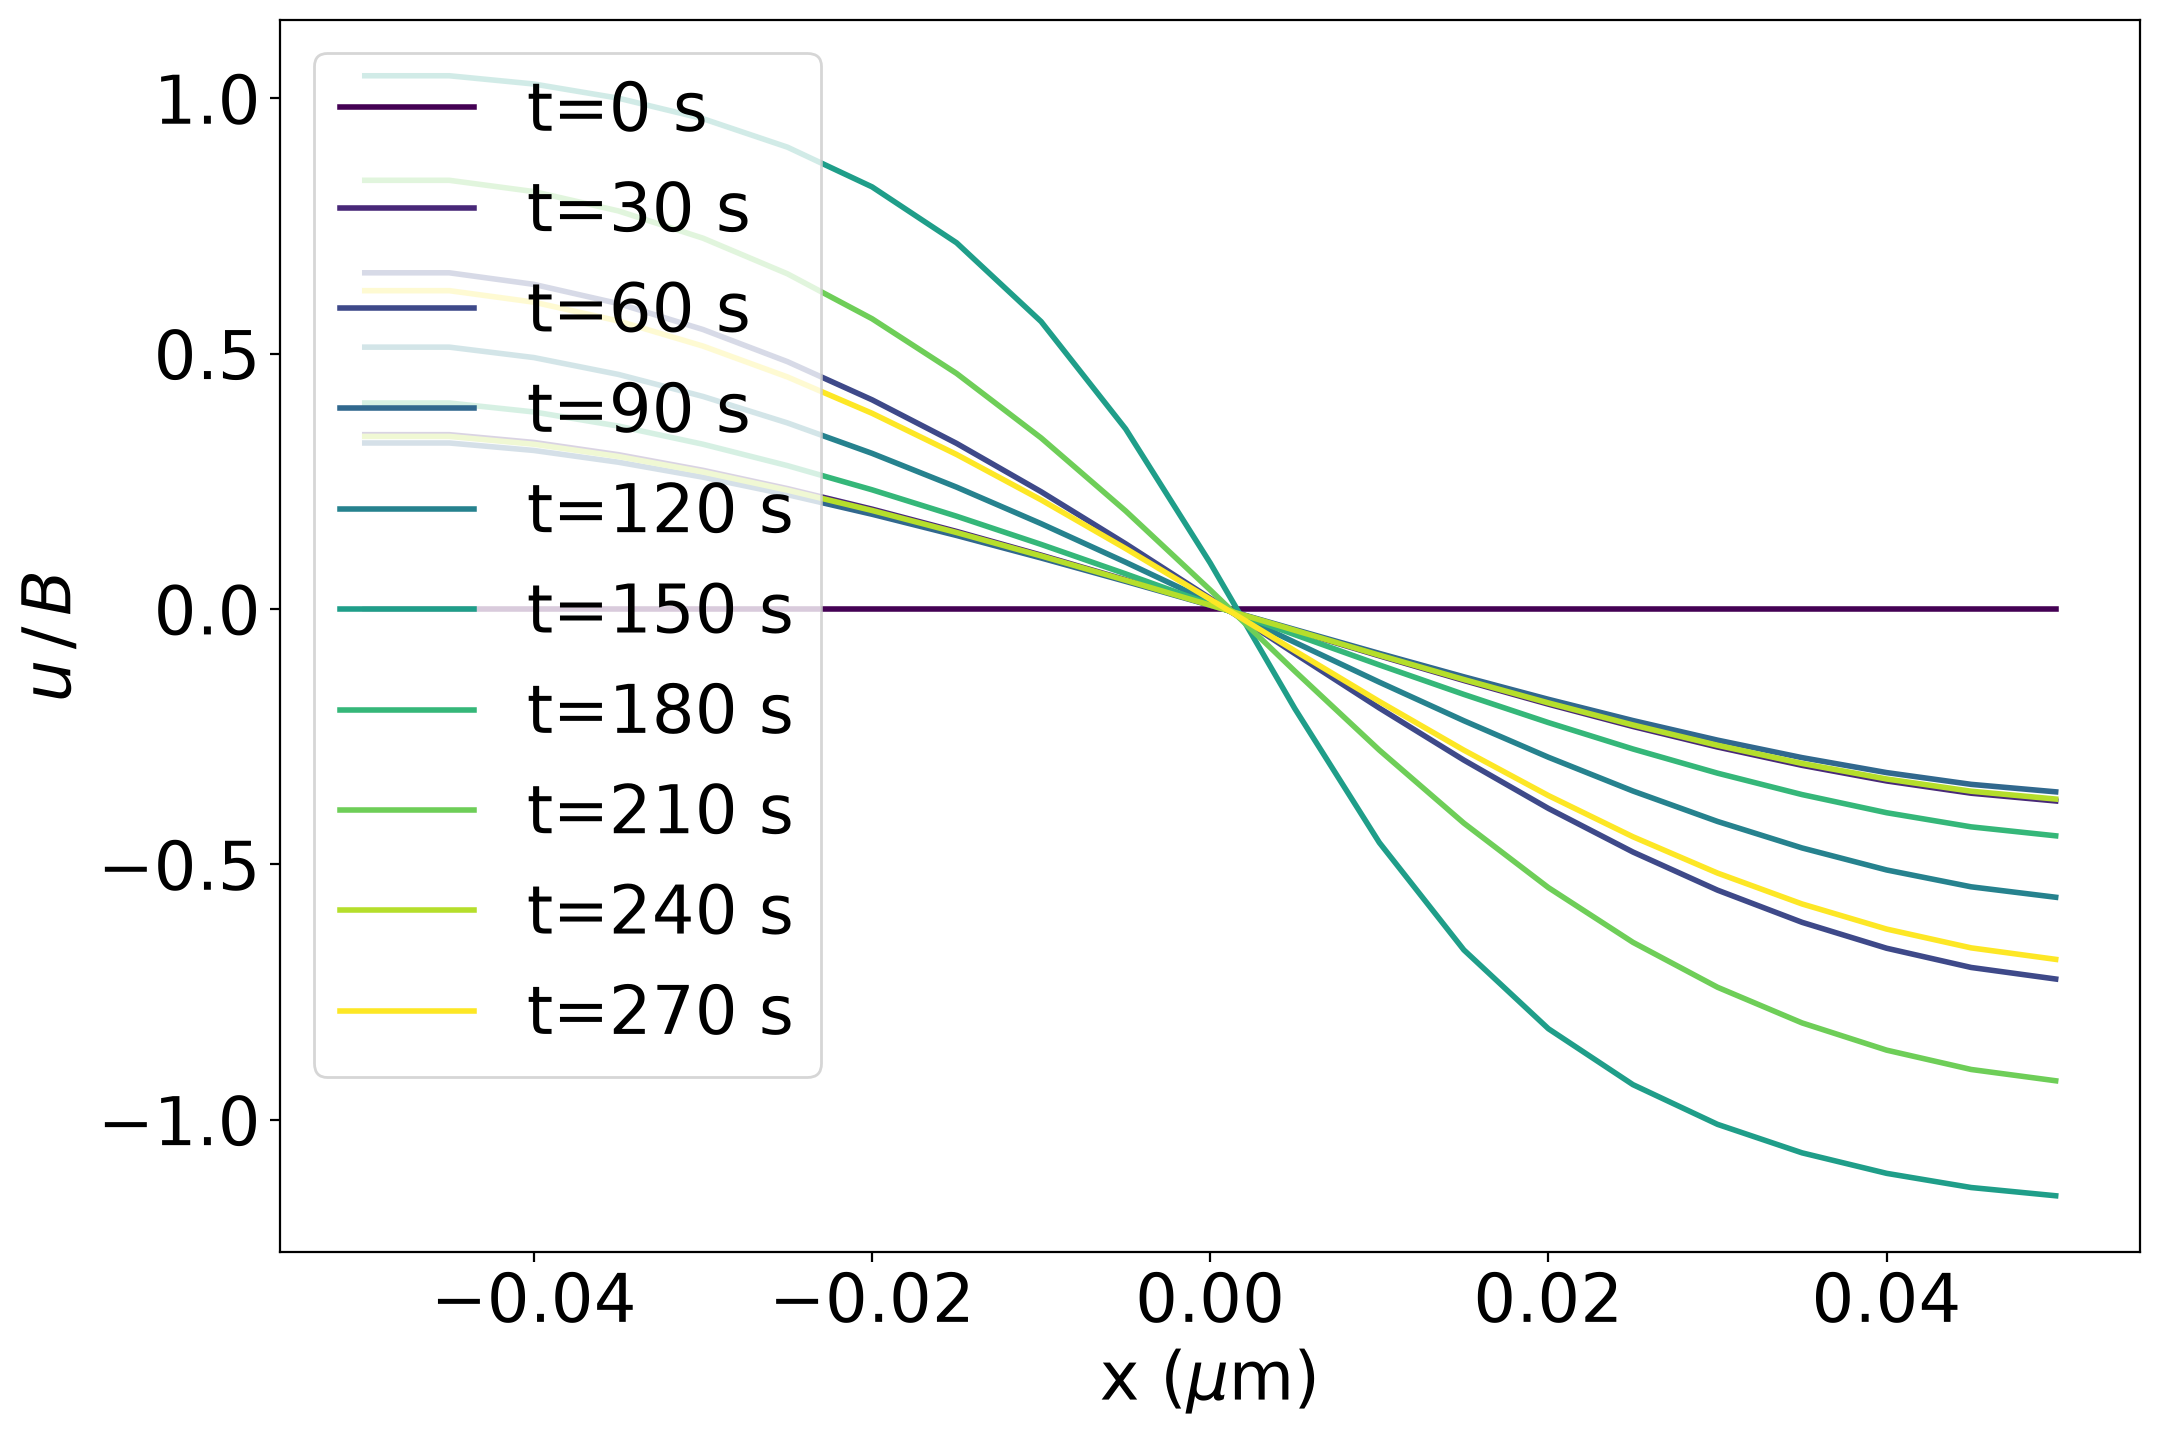

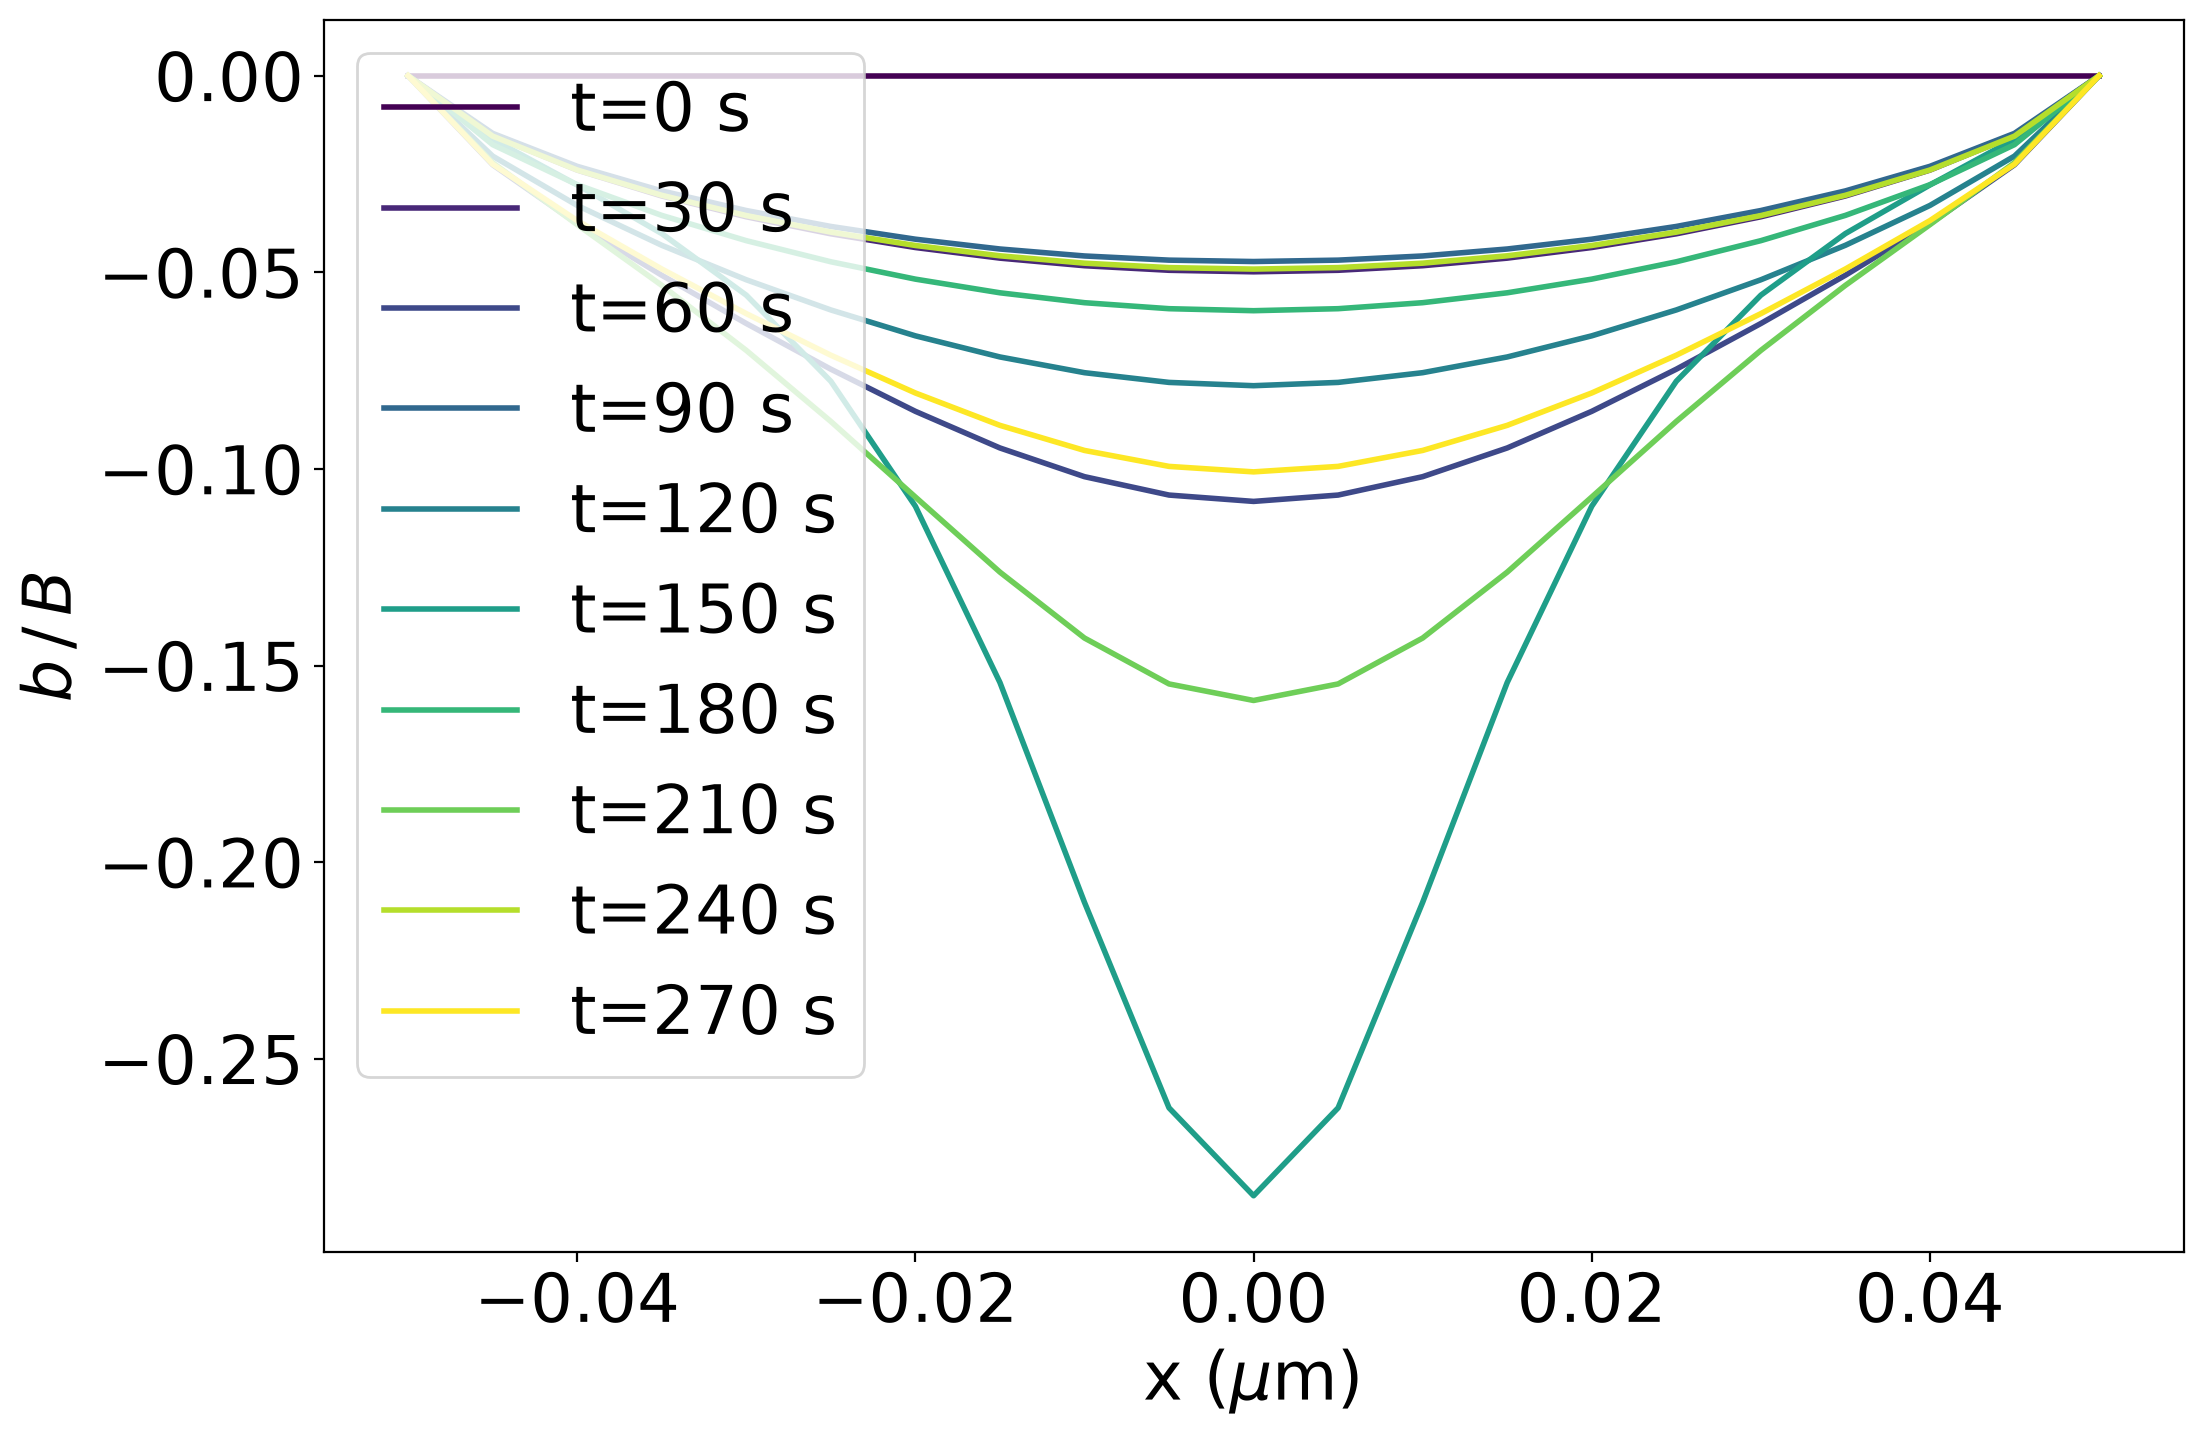

Data file with N_gbn=31, delta=0.1, dtmax=1.0


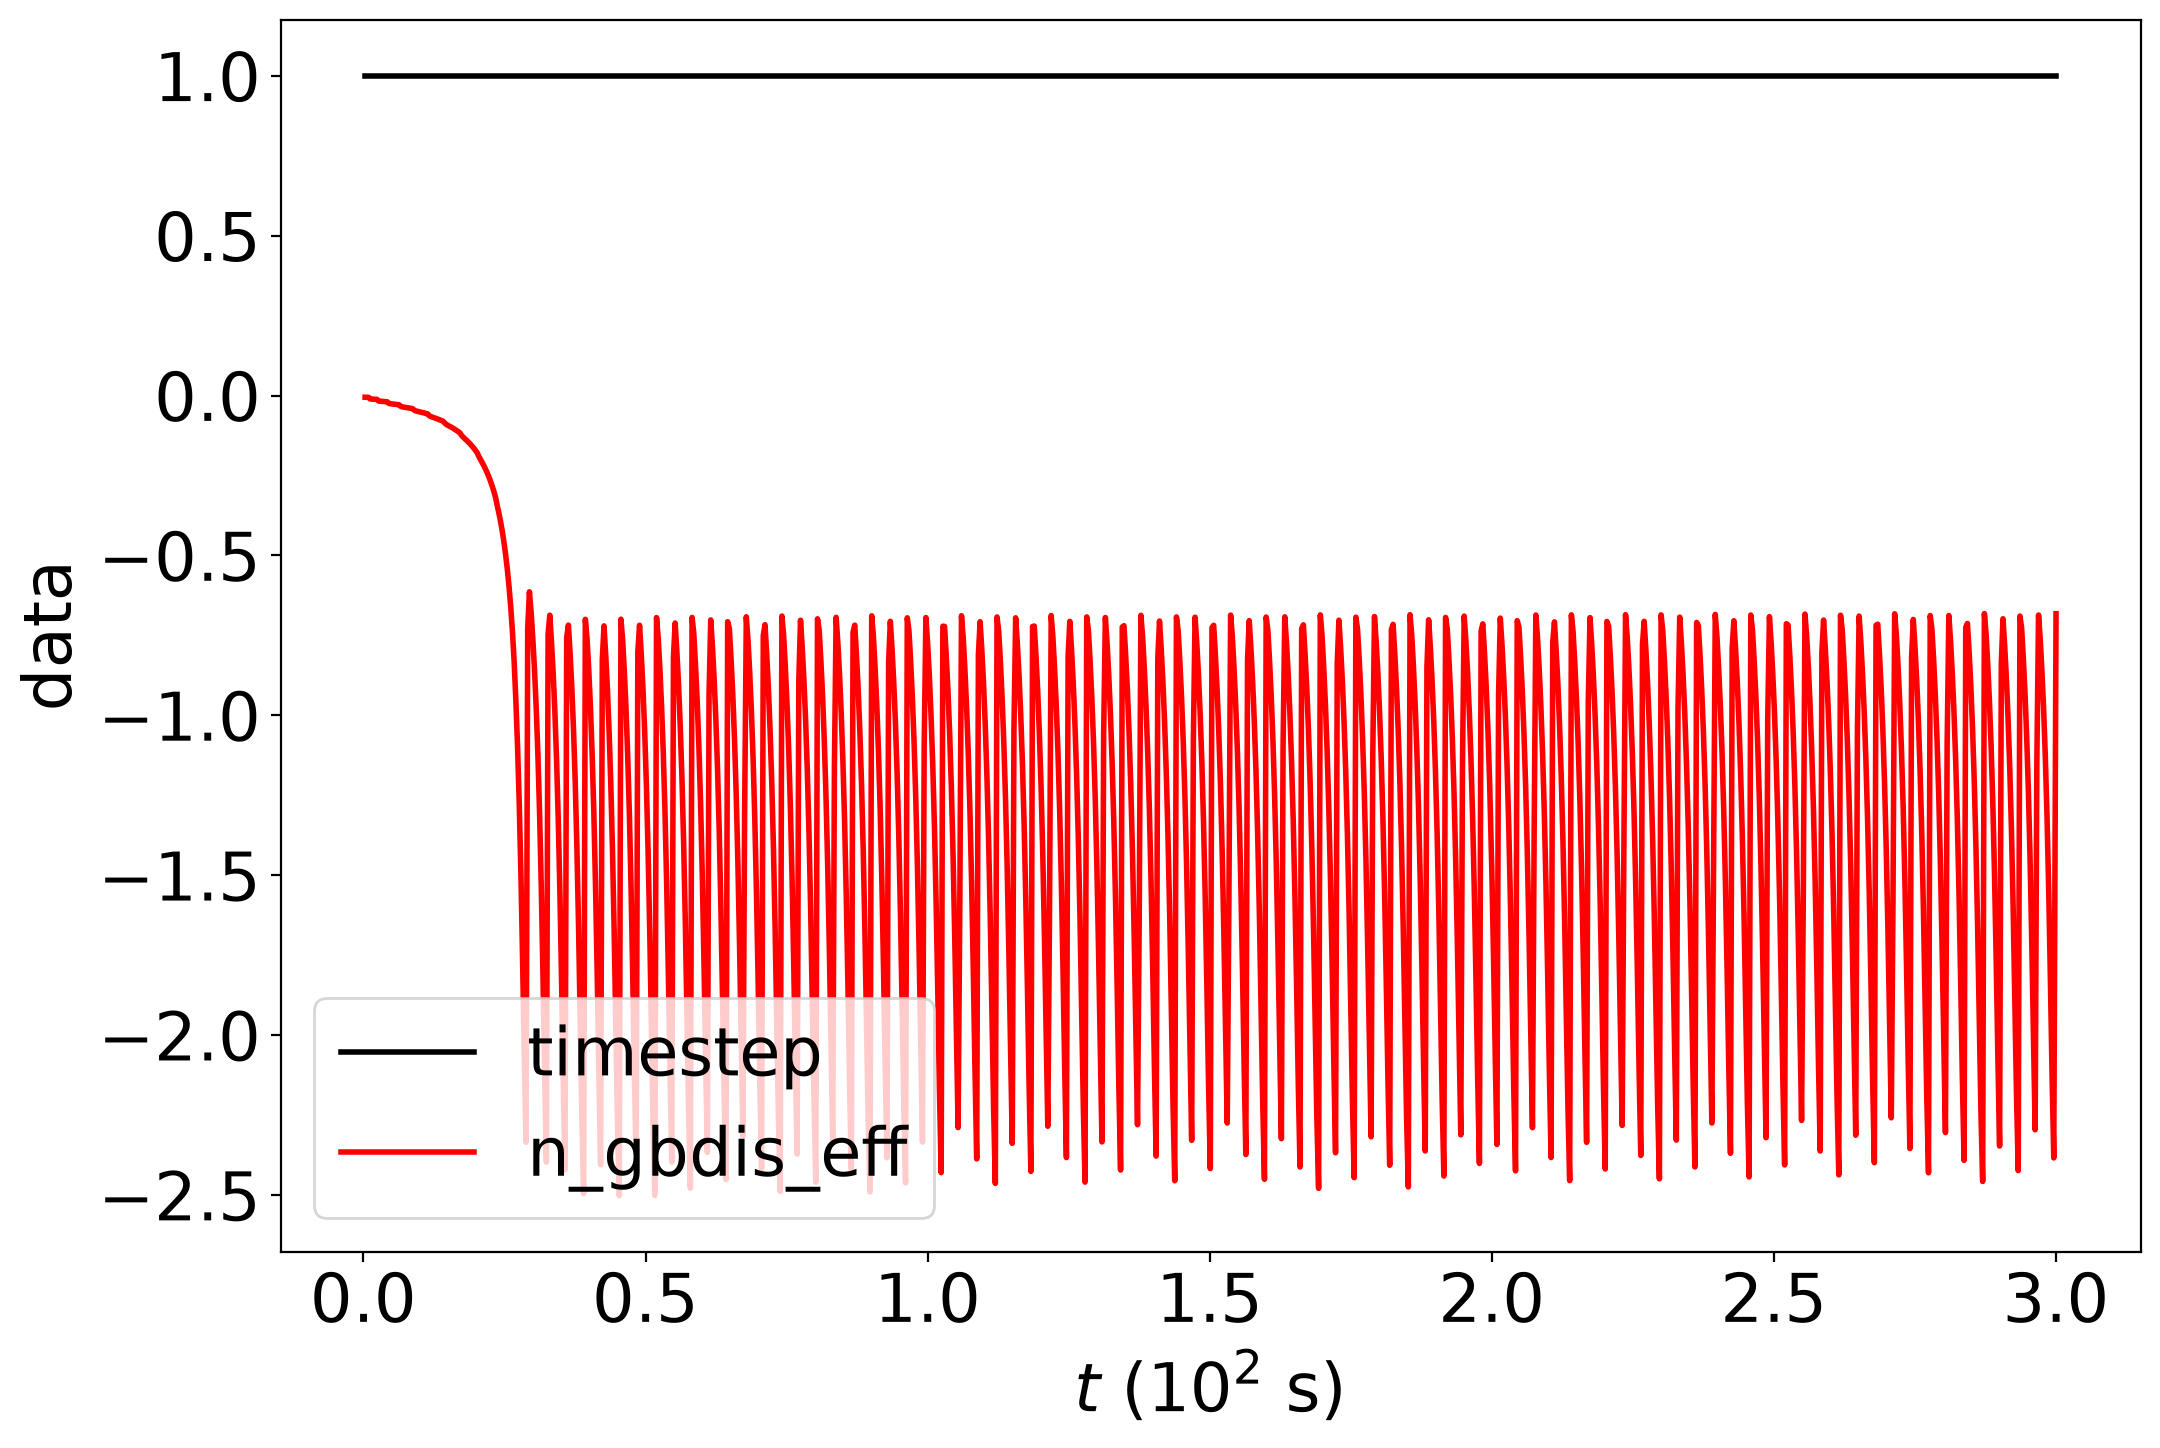

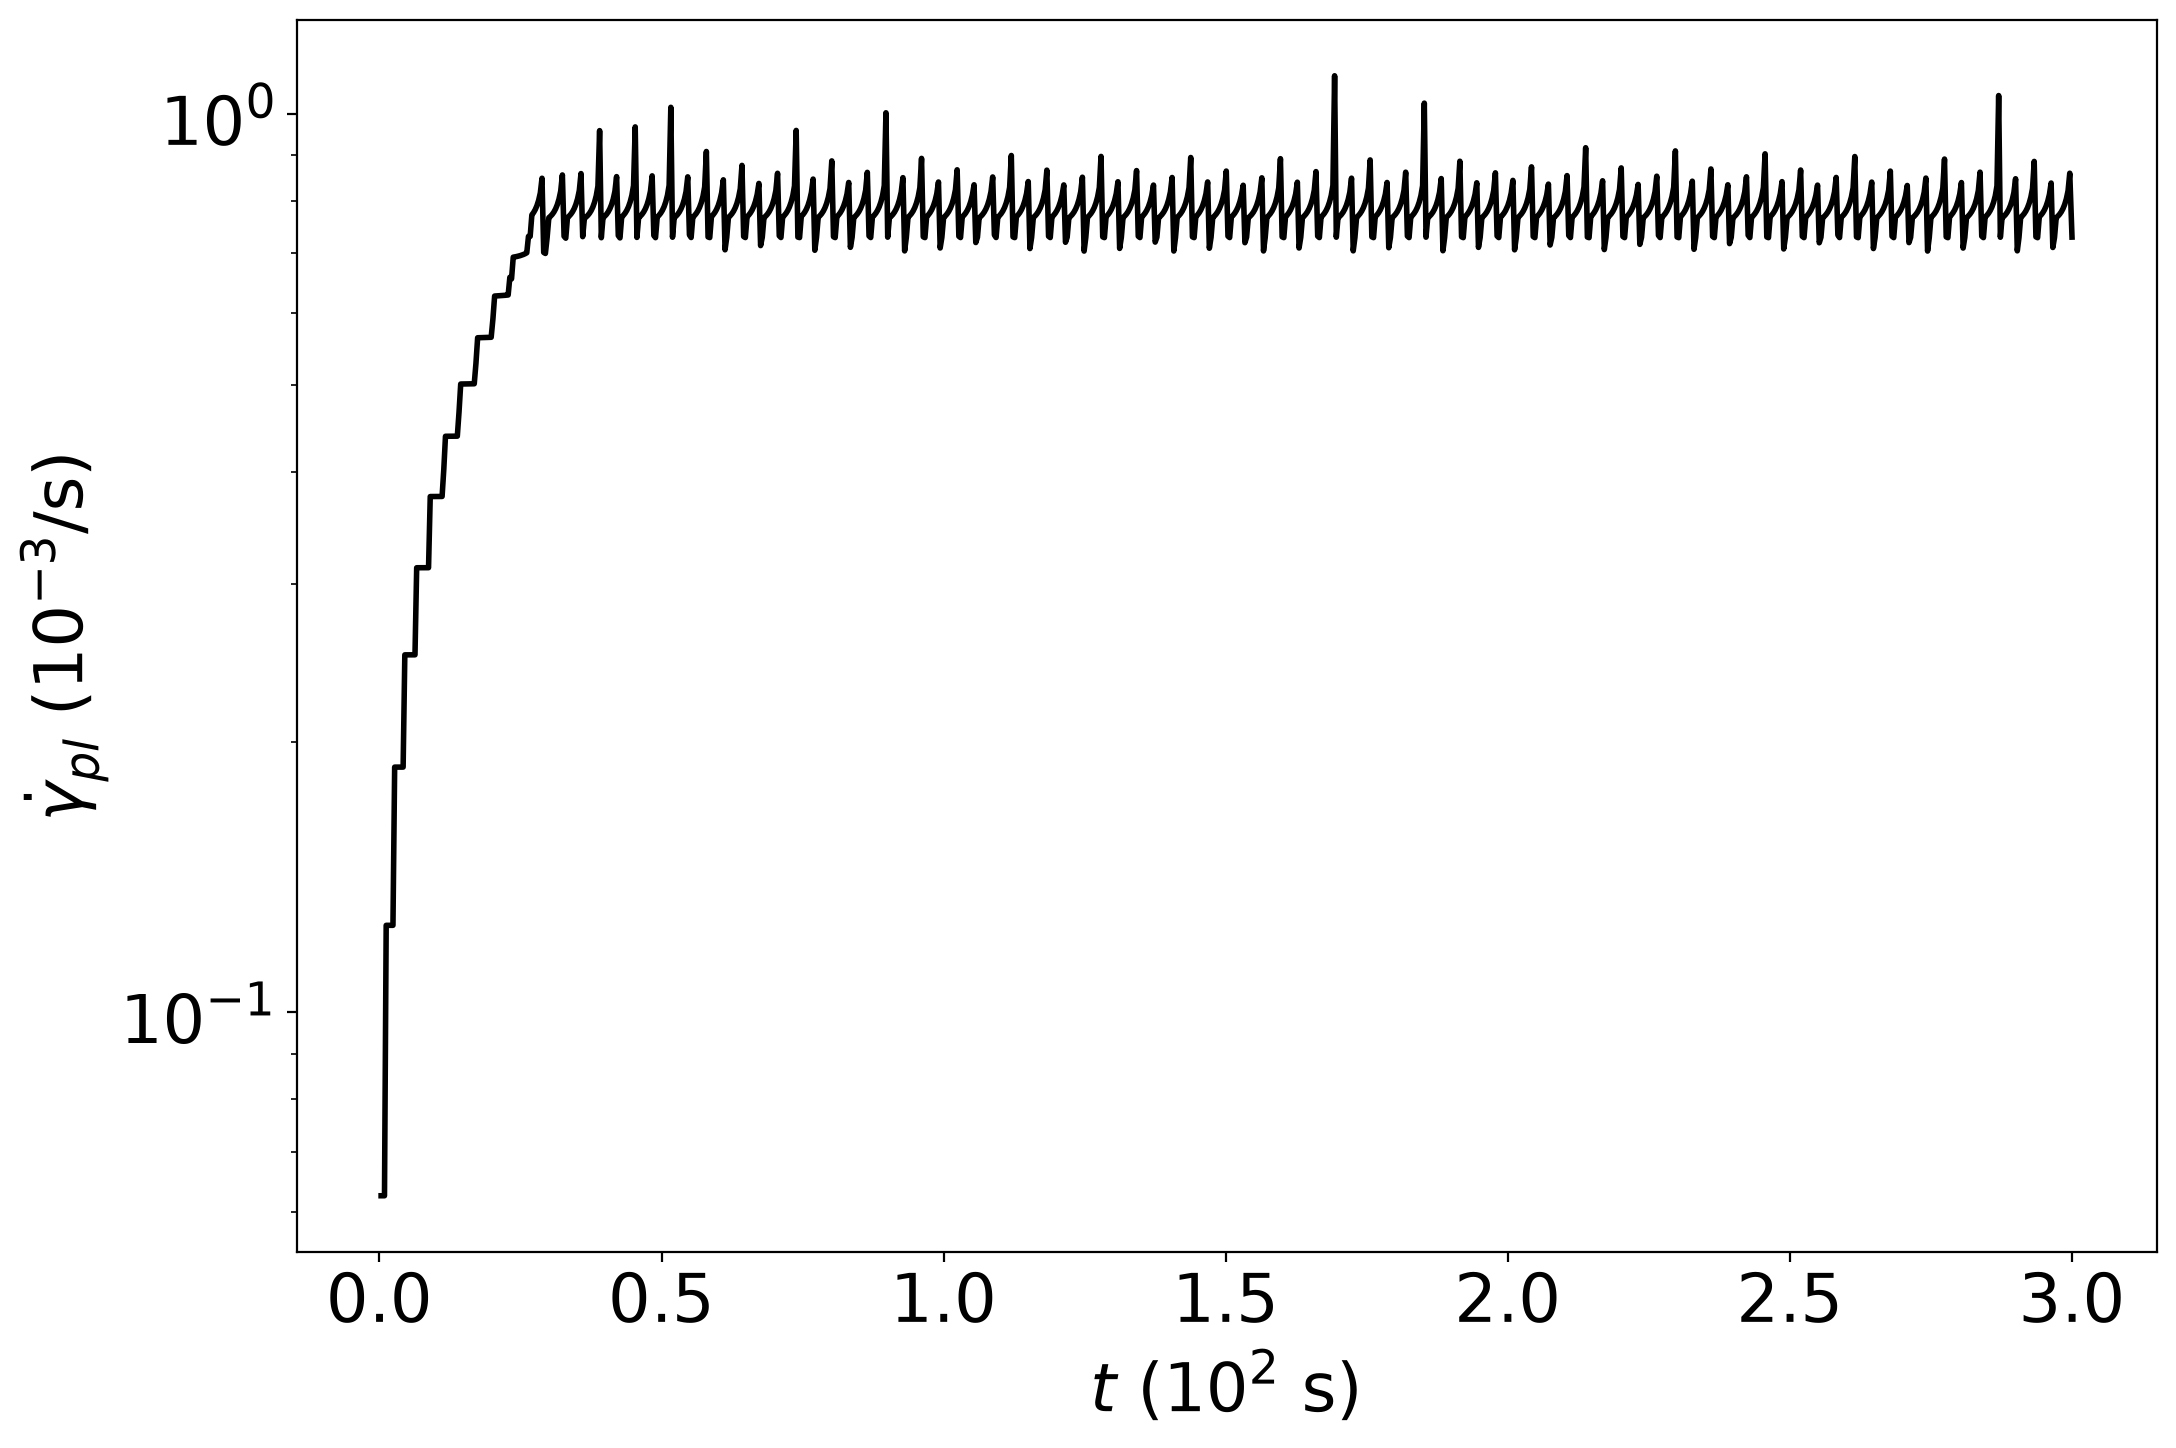

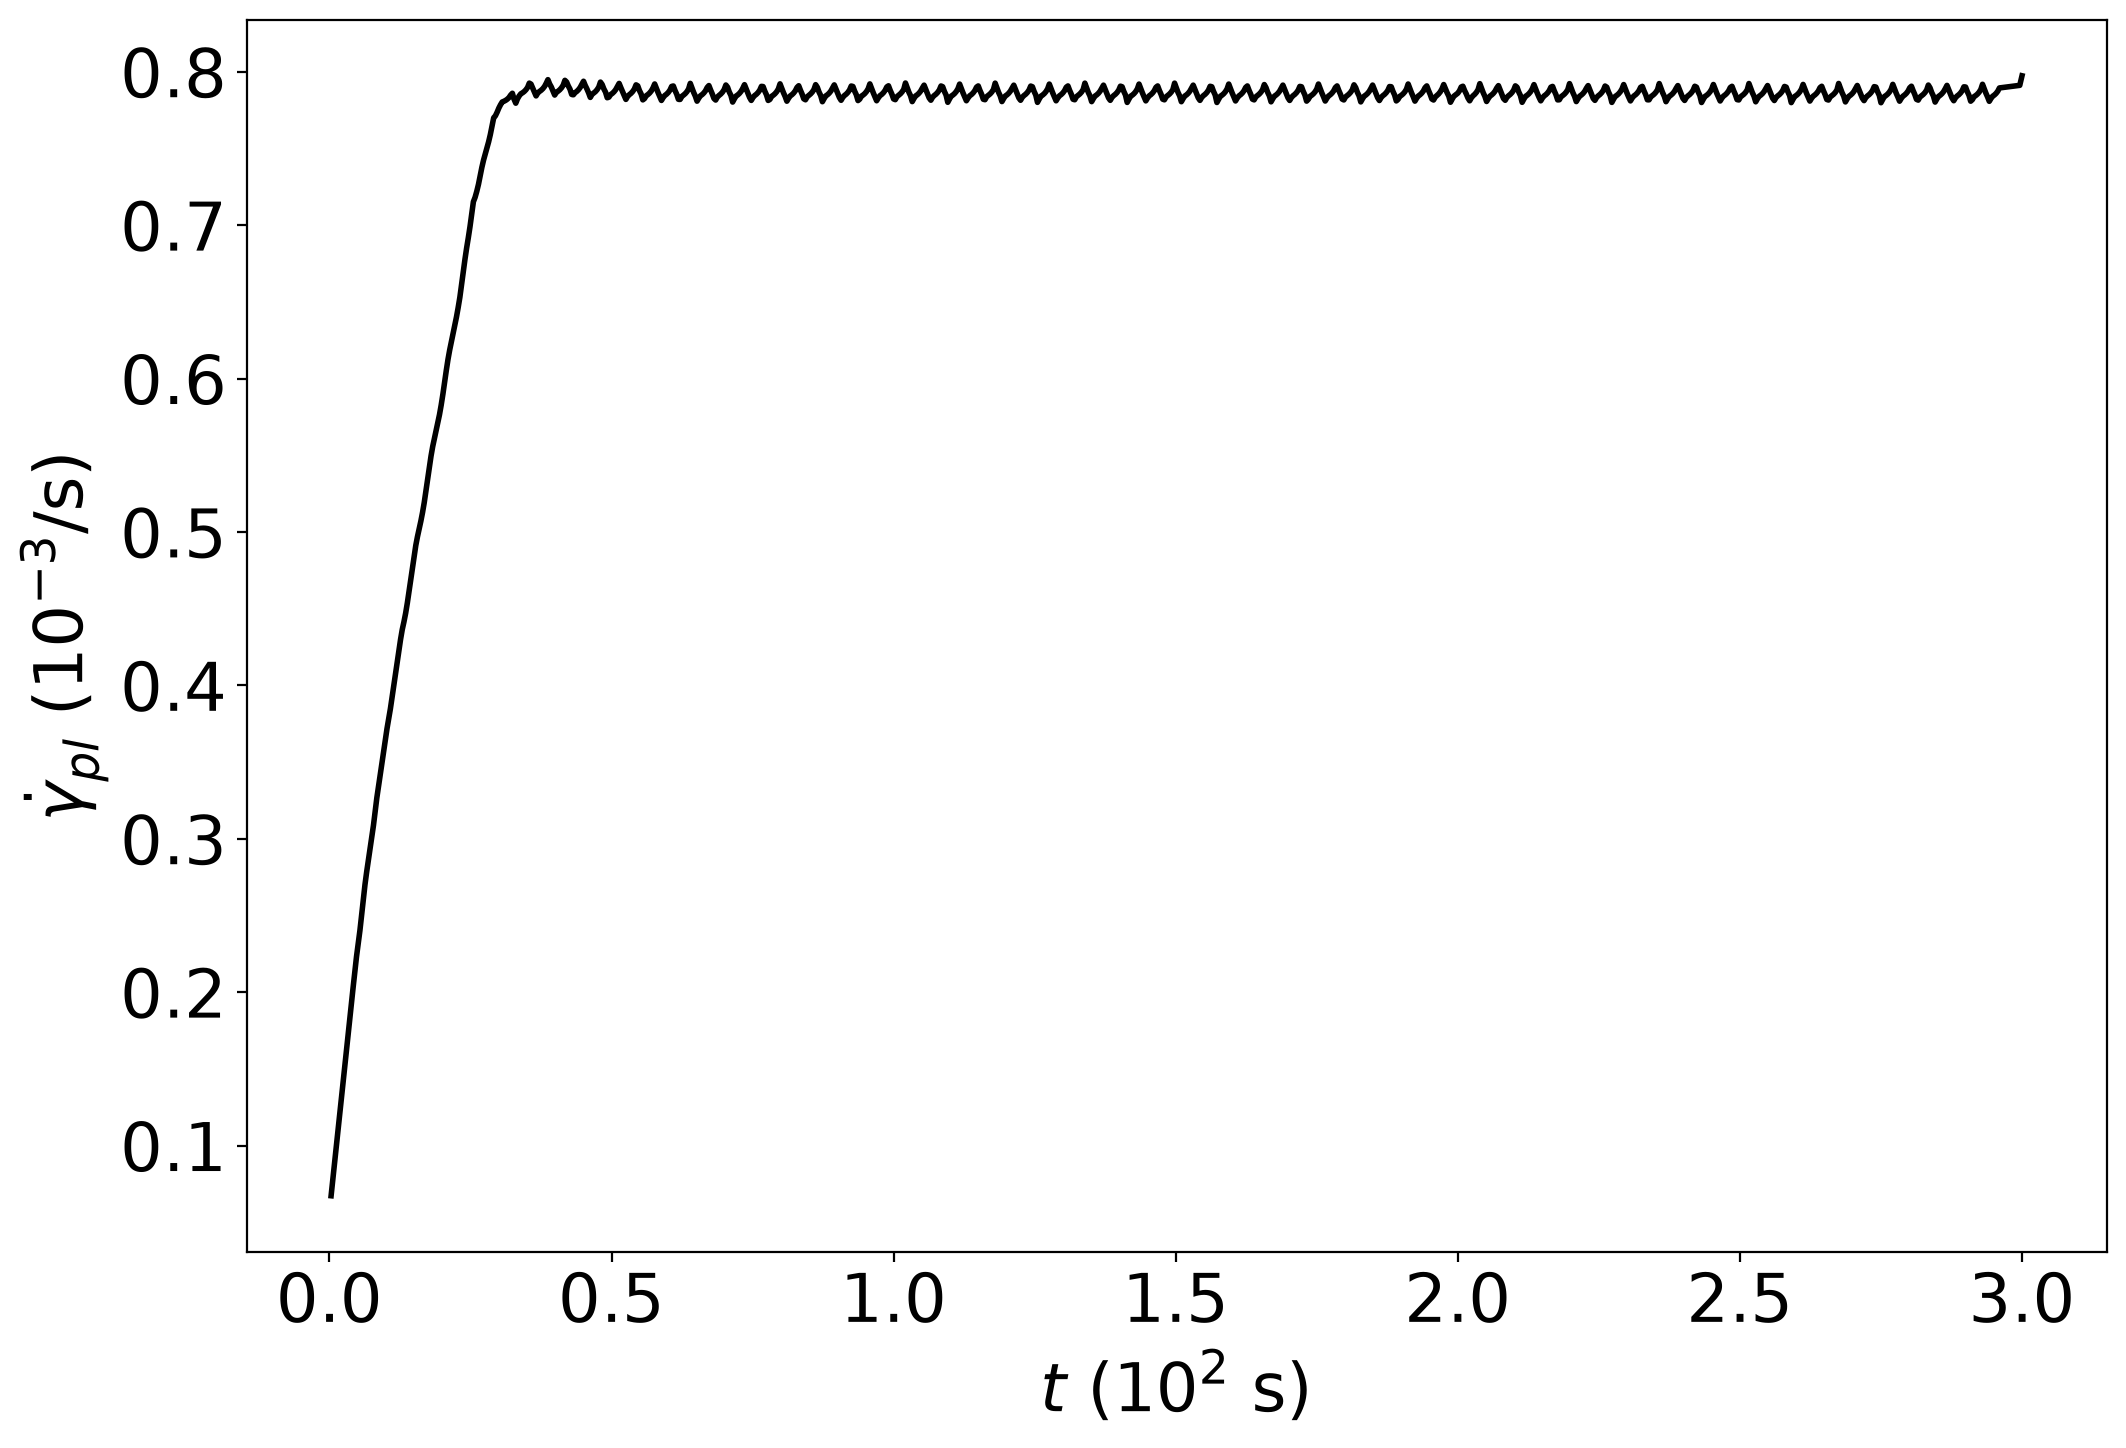

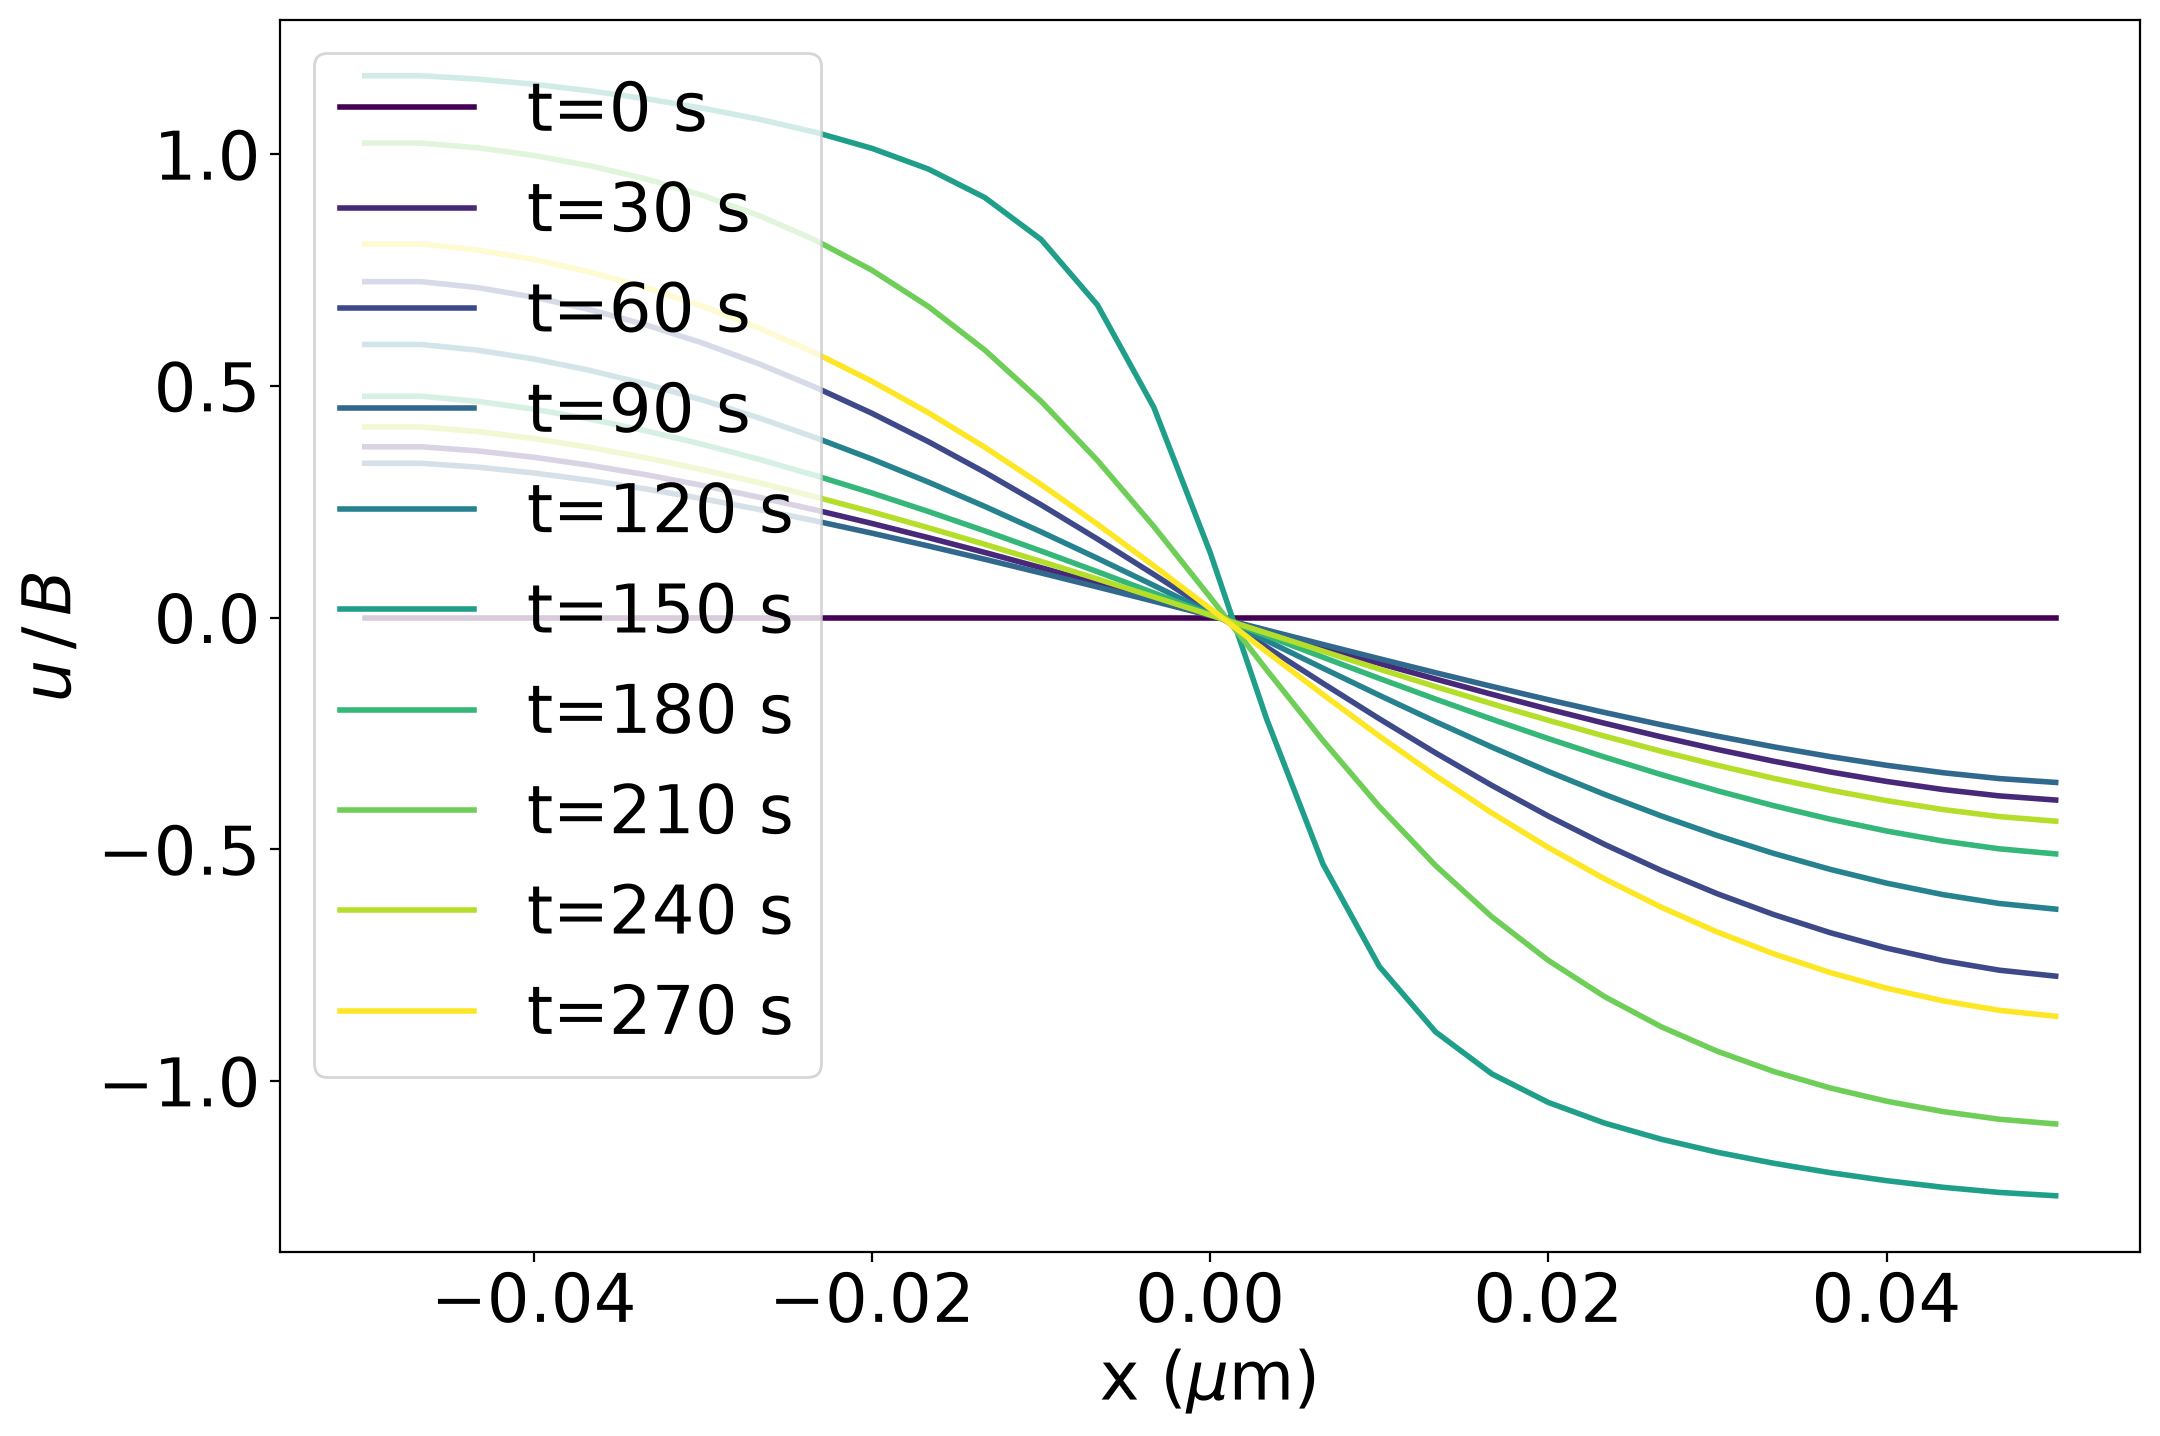

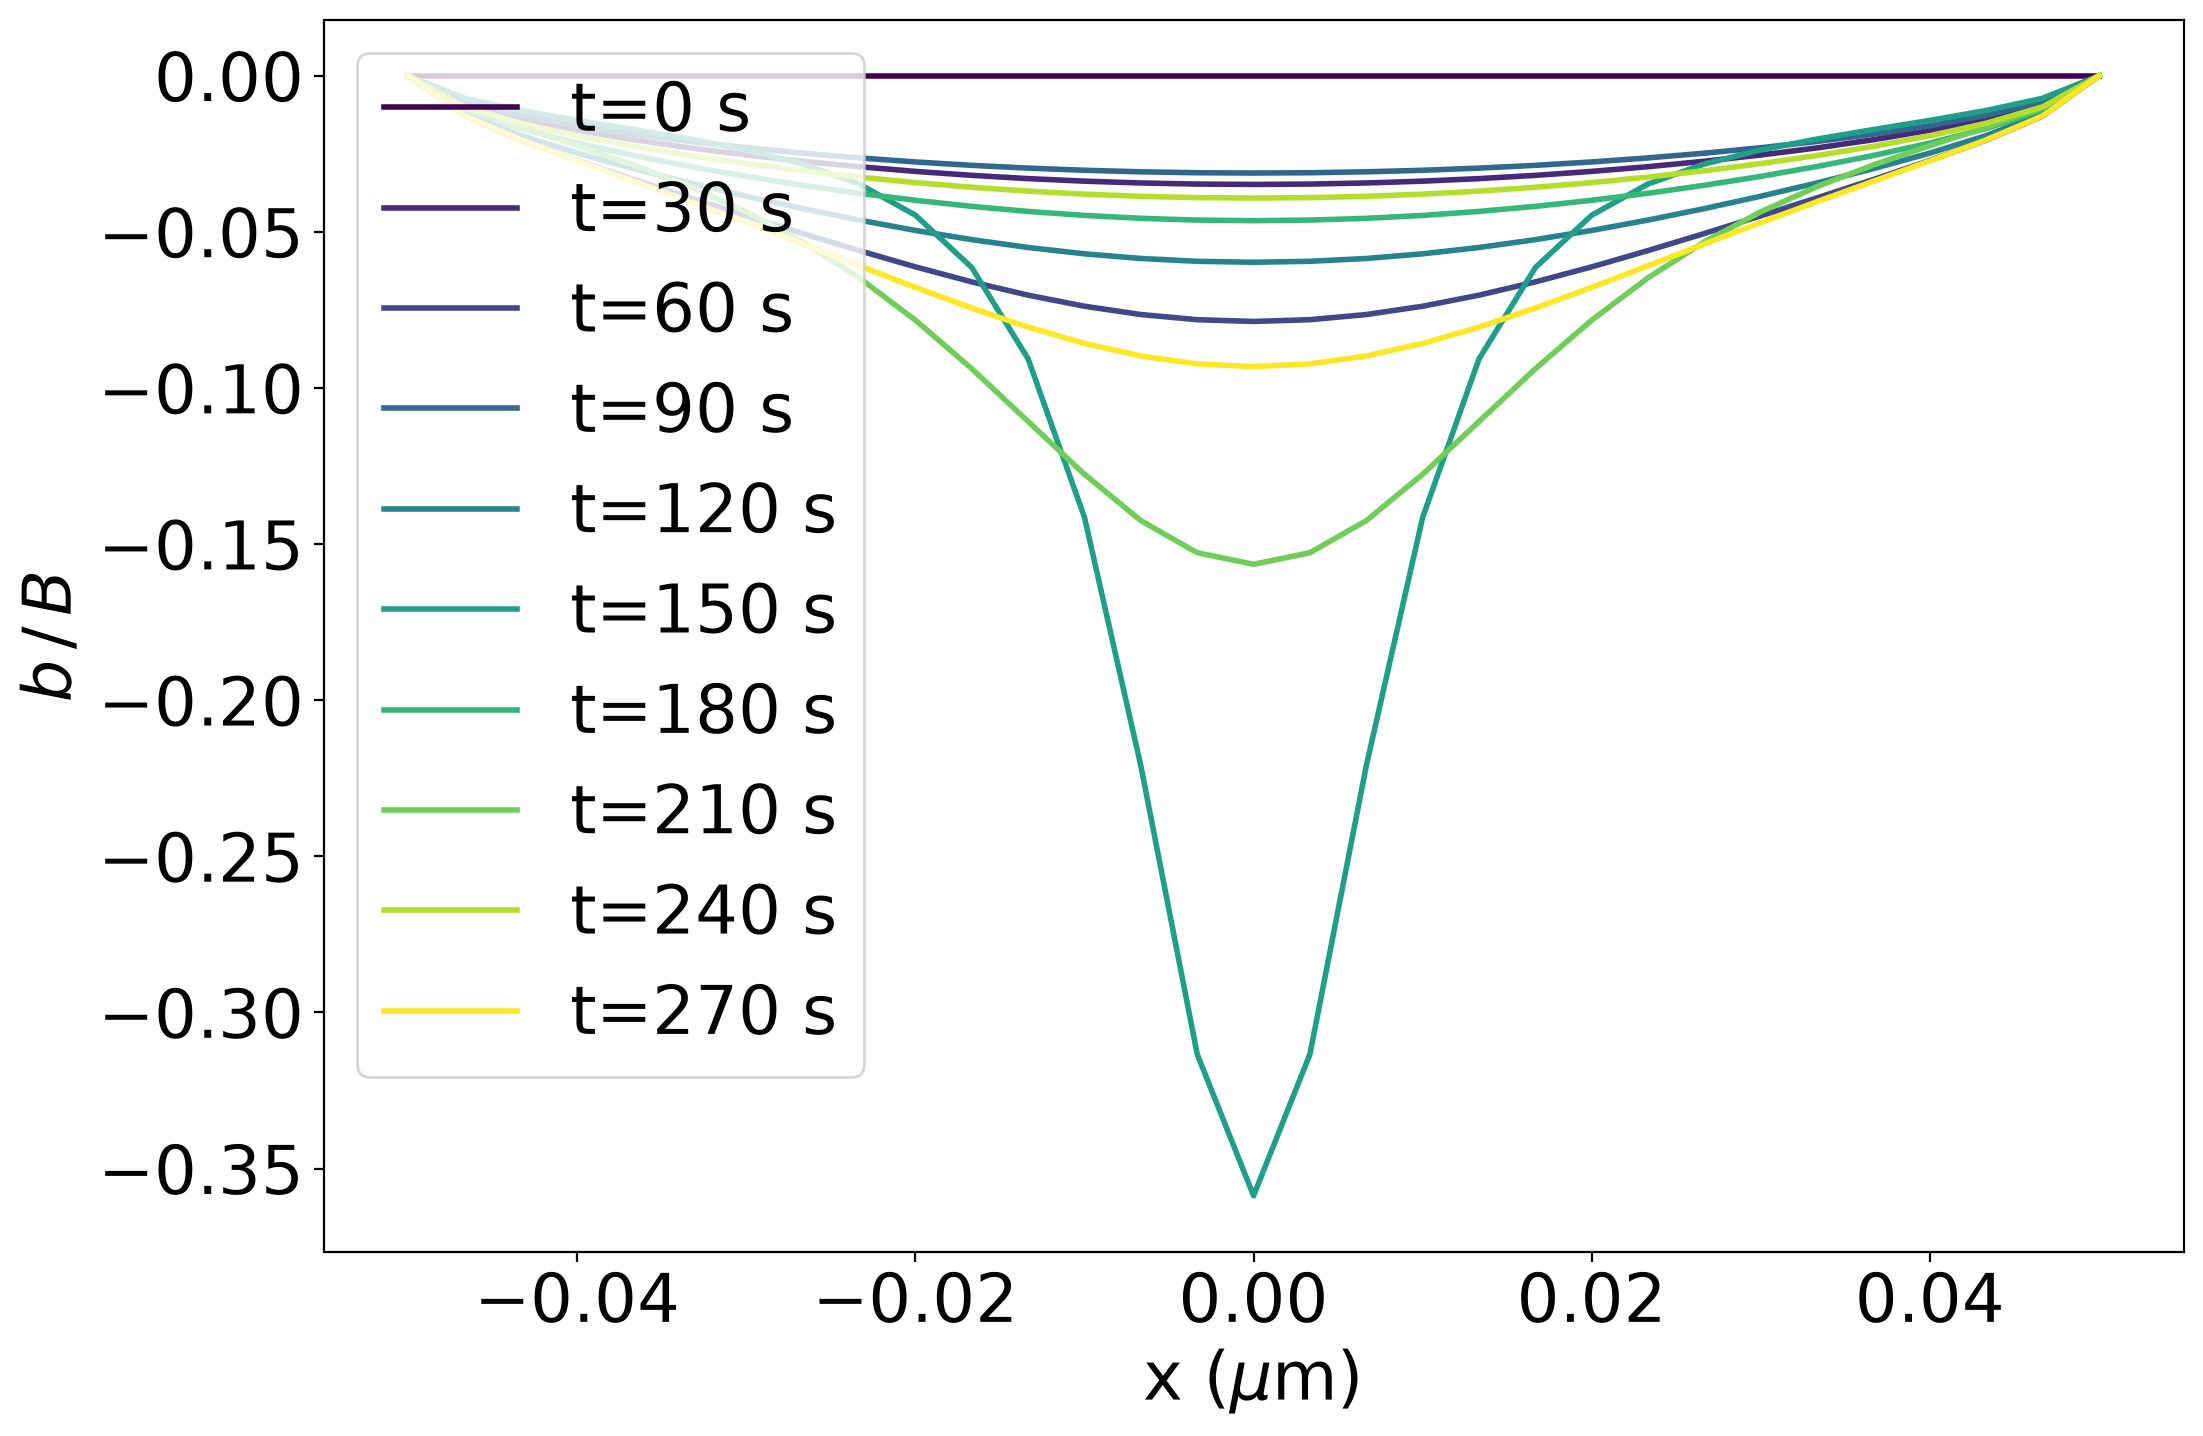

Data file with N_gbn=41, delta=0.1, dtmax=1.0


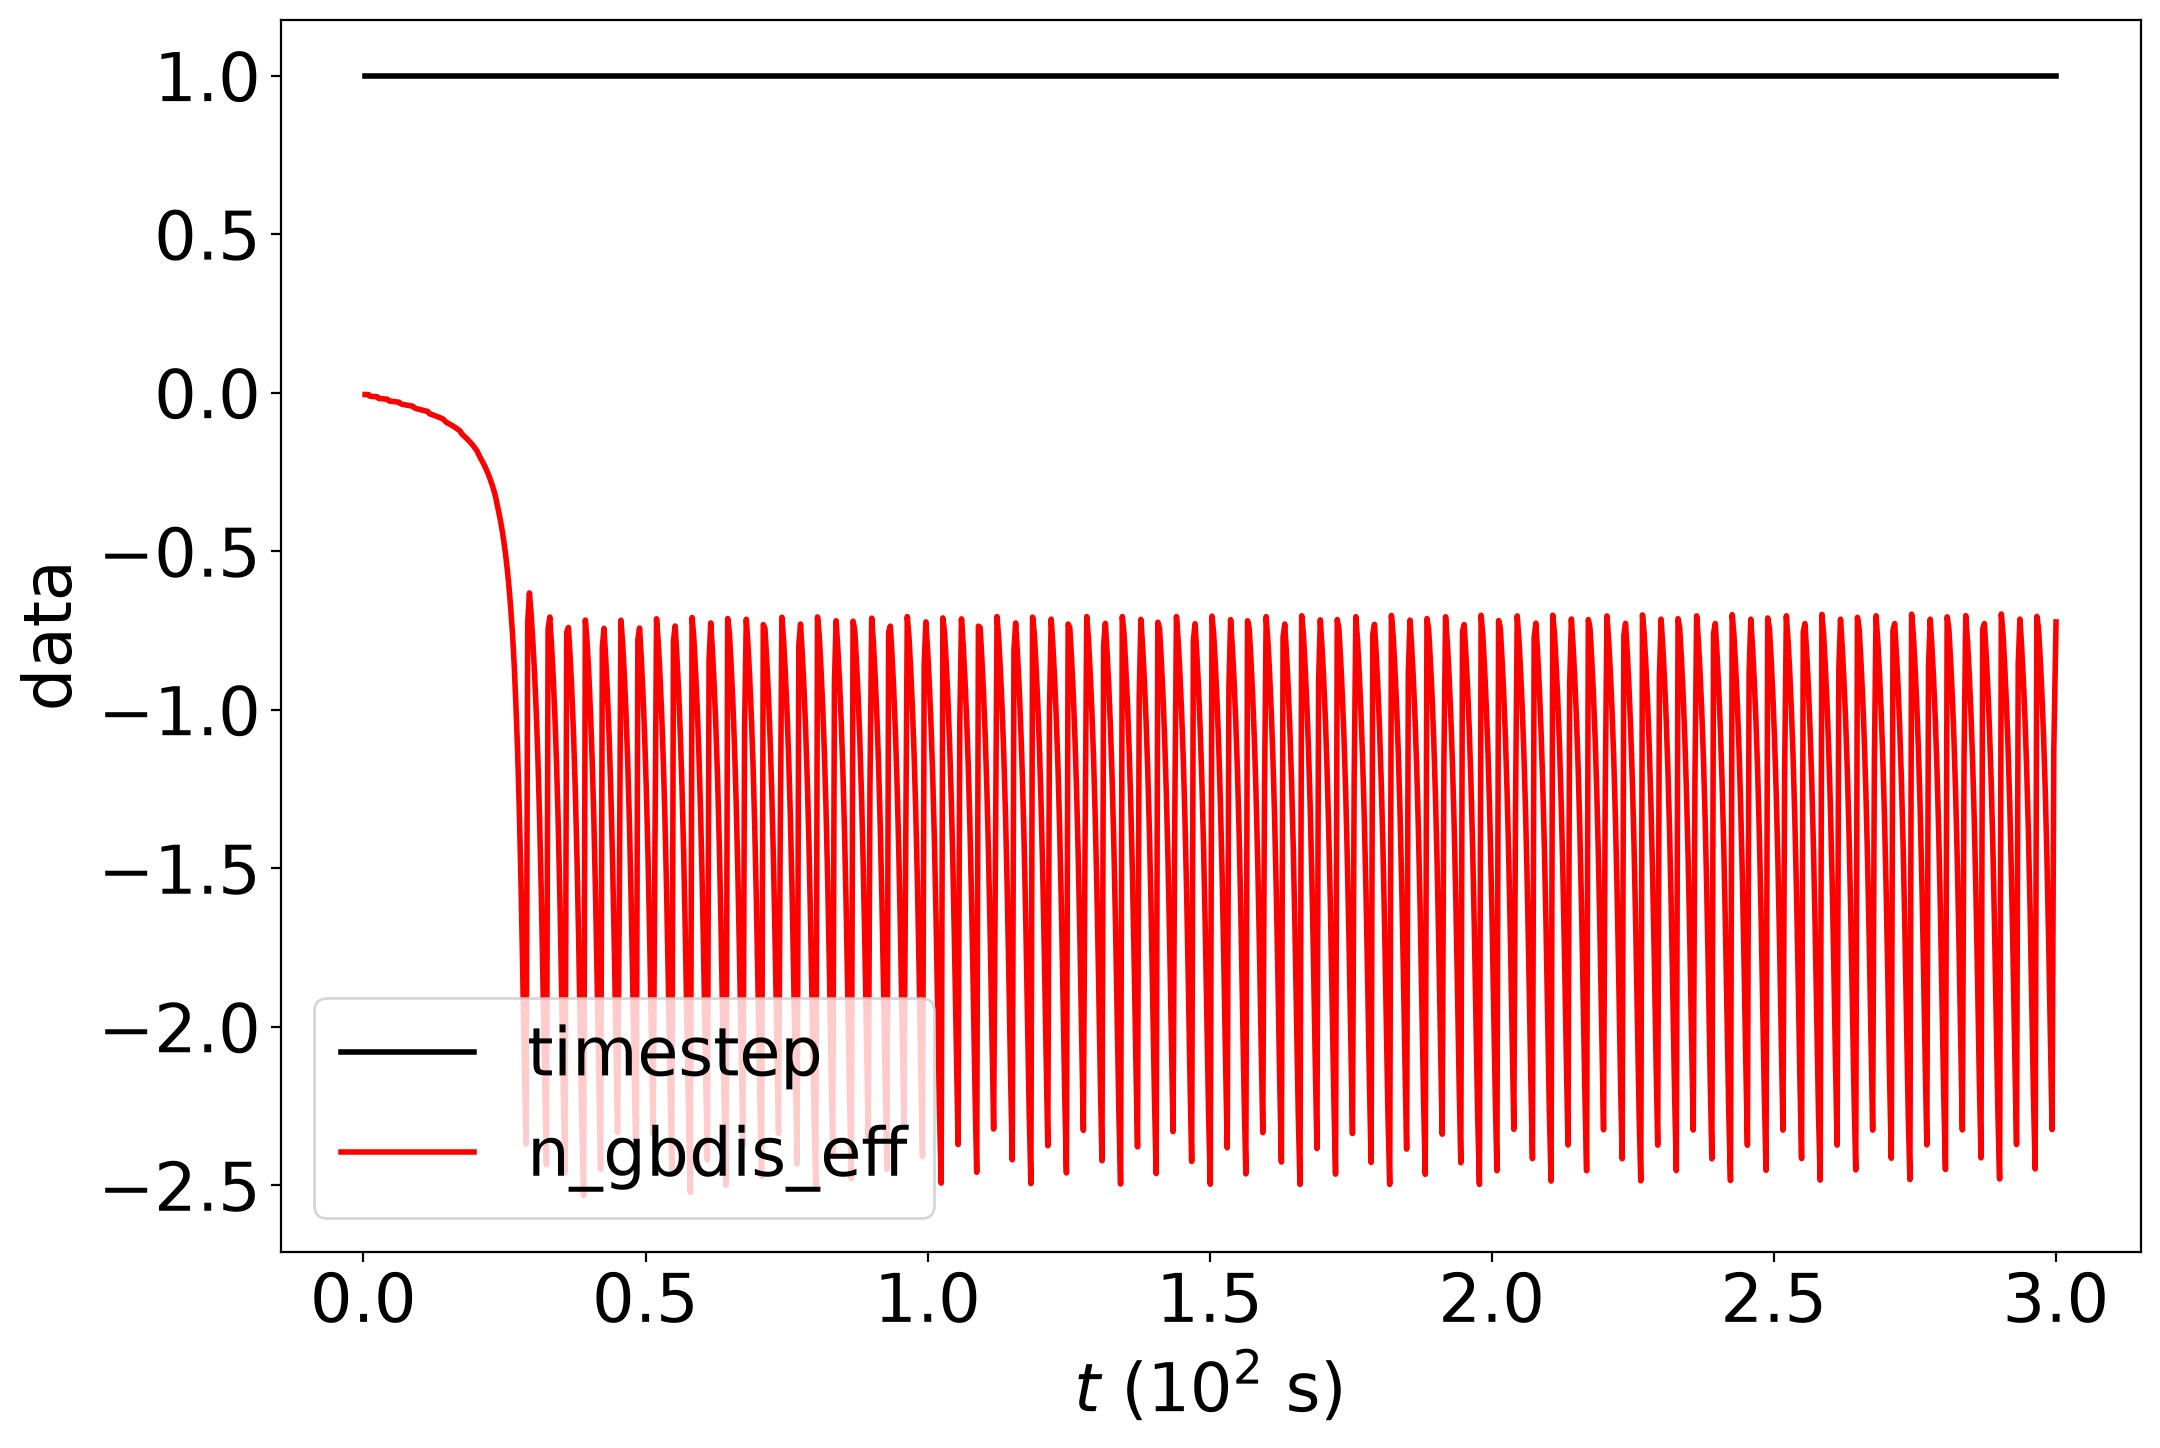

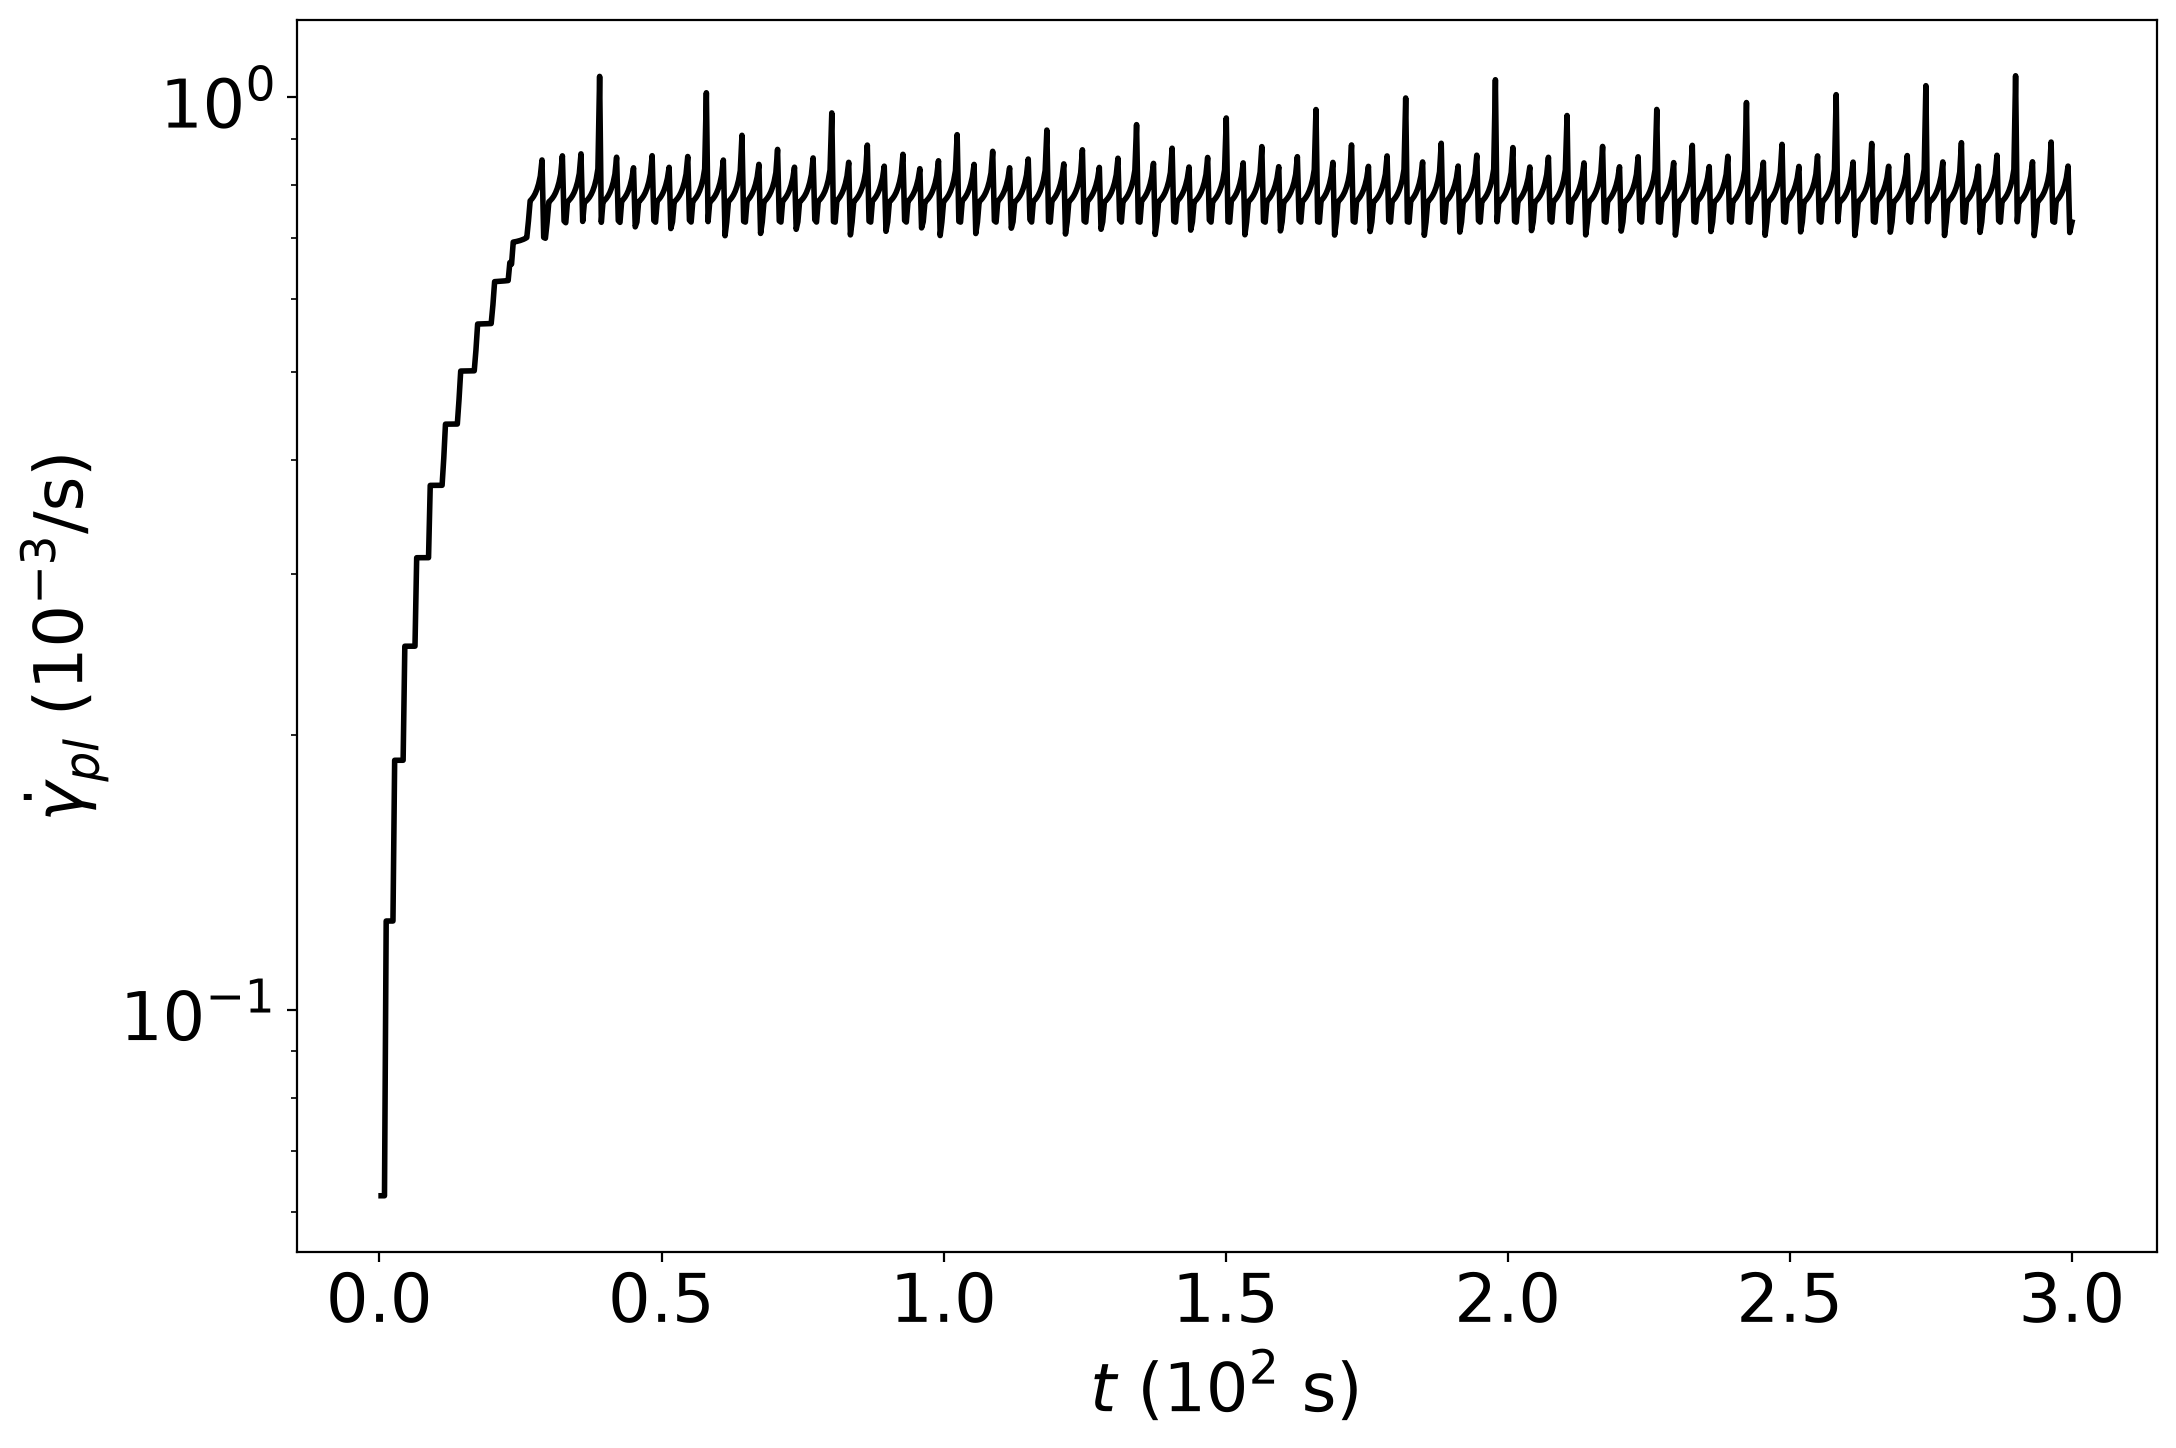

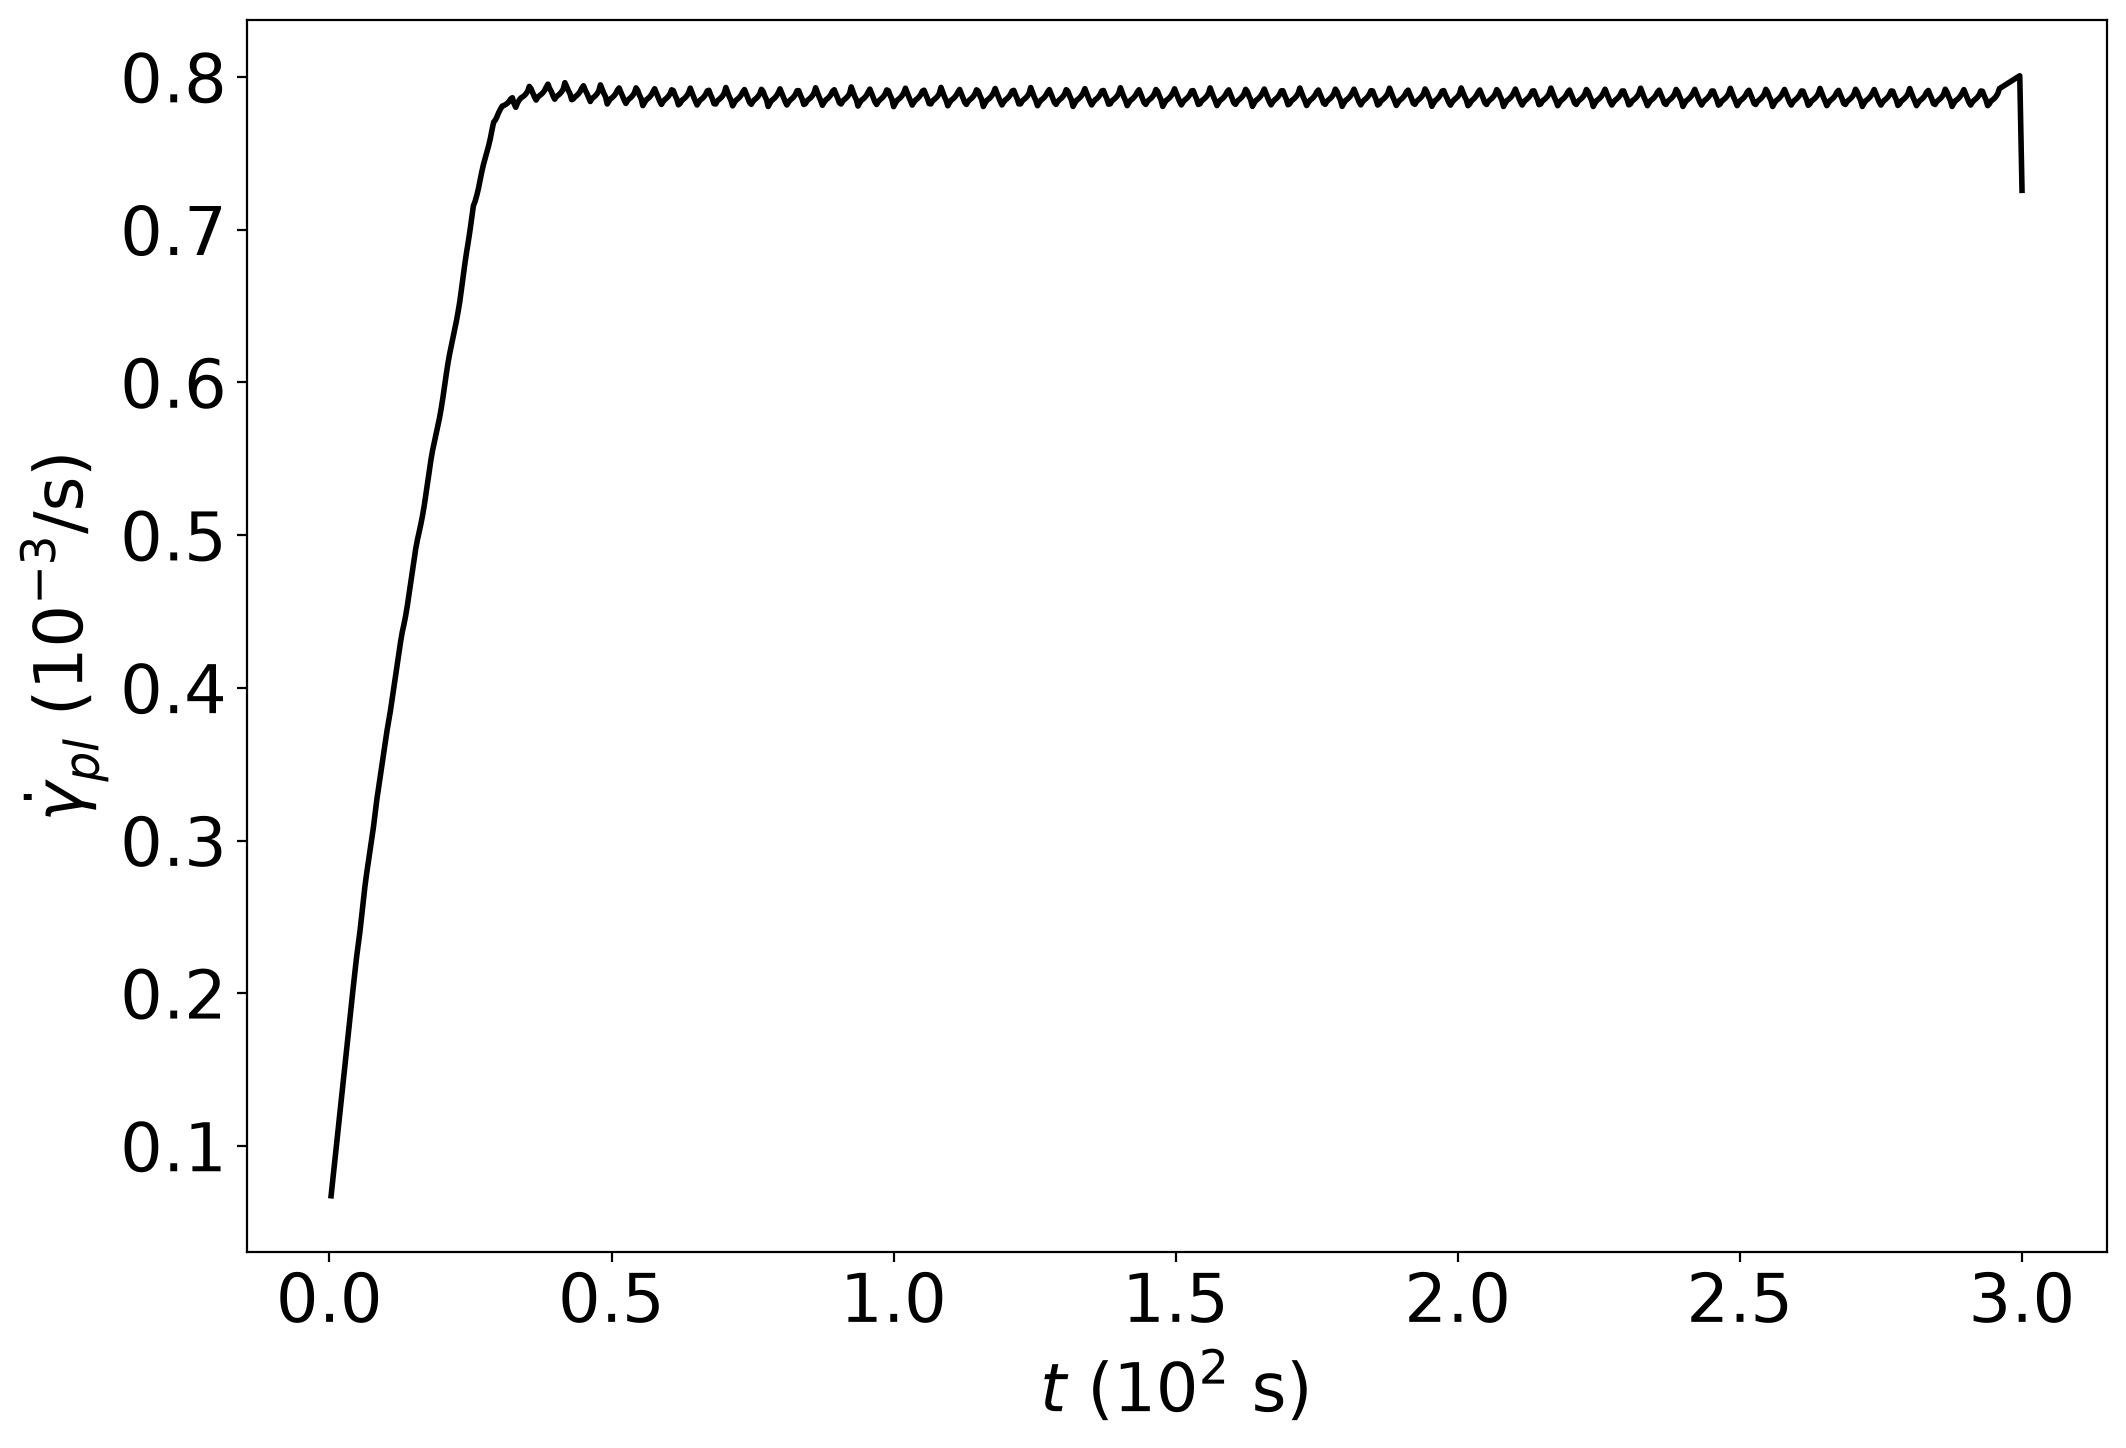

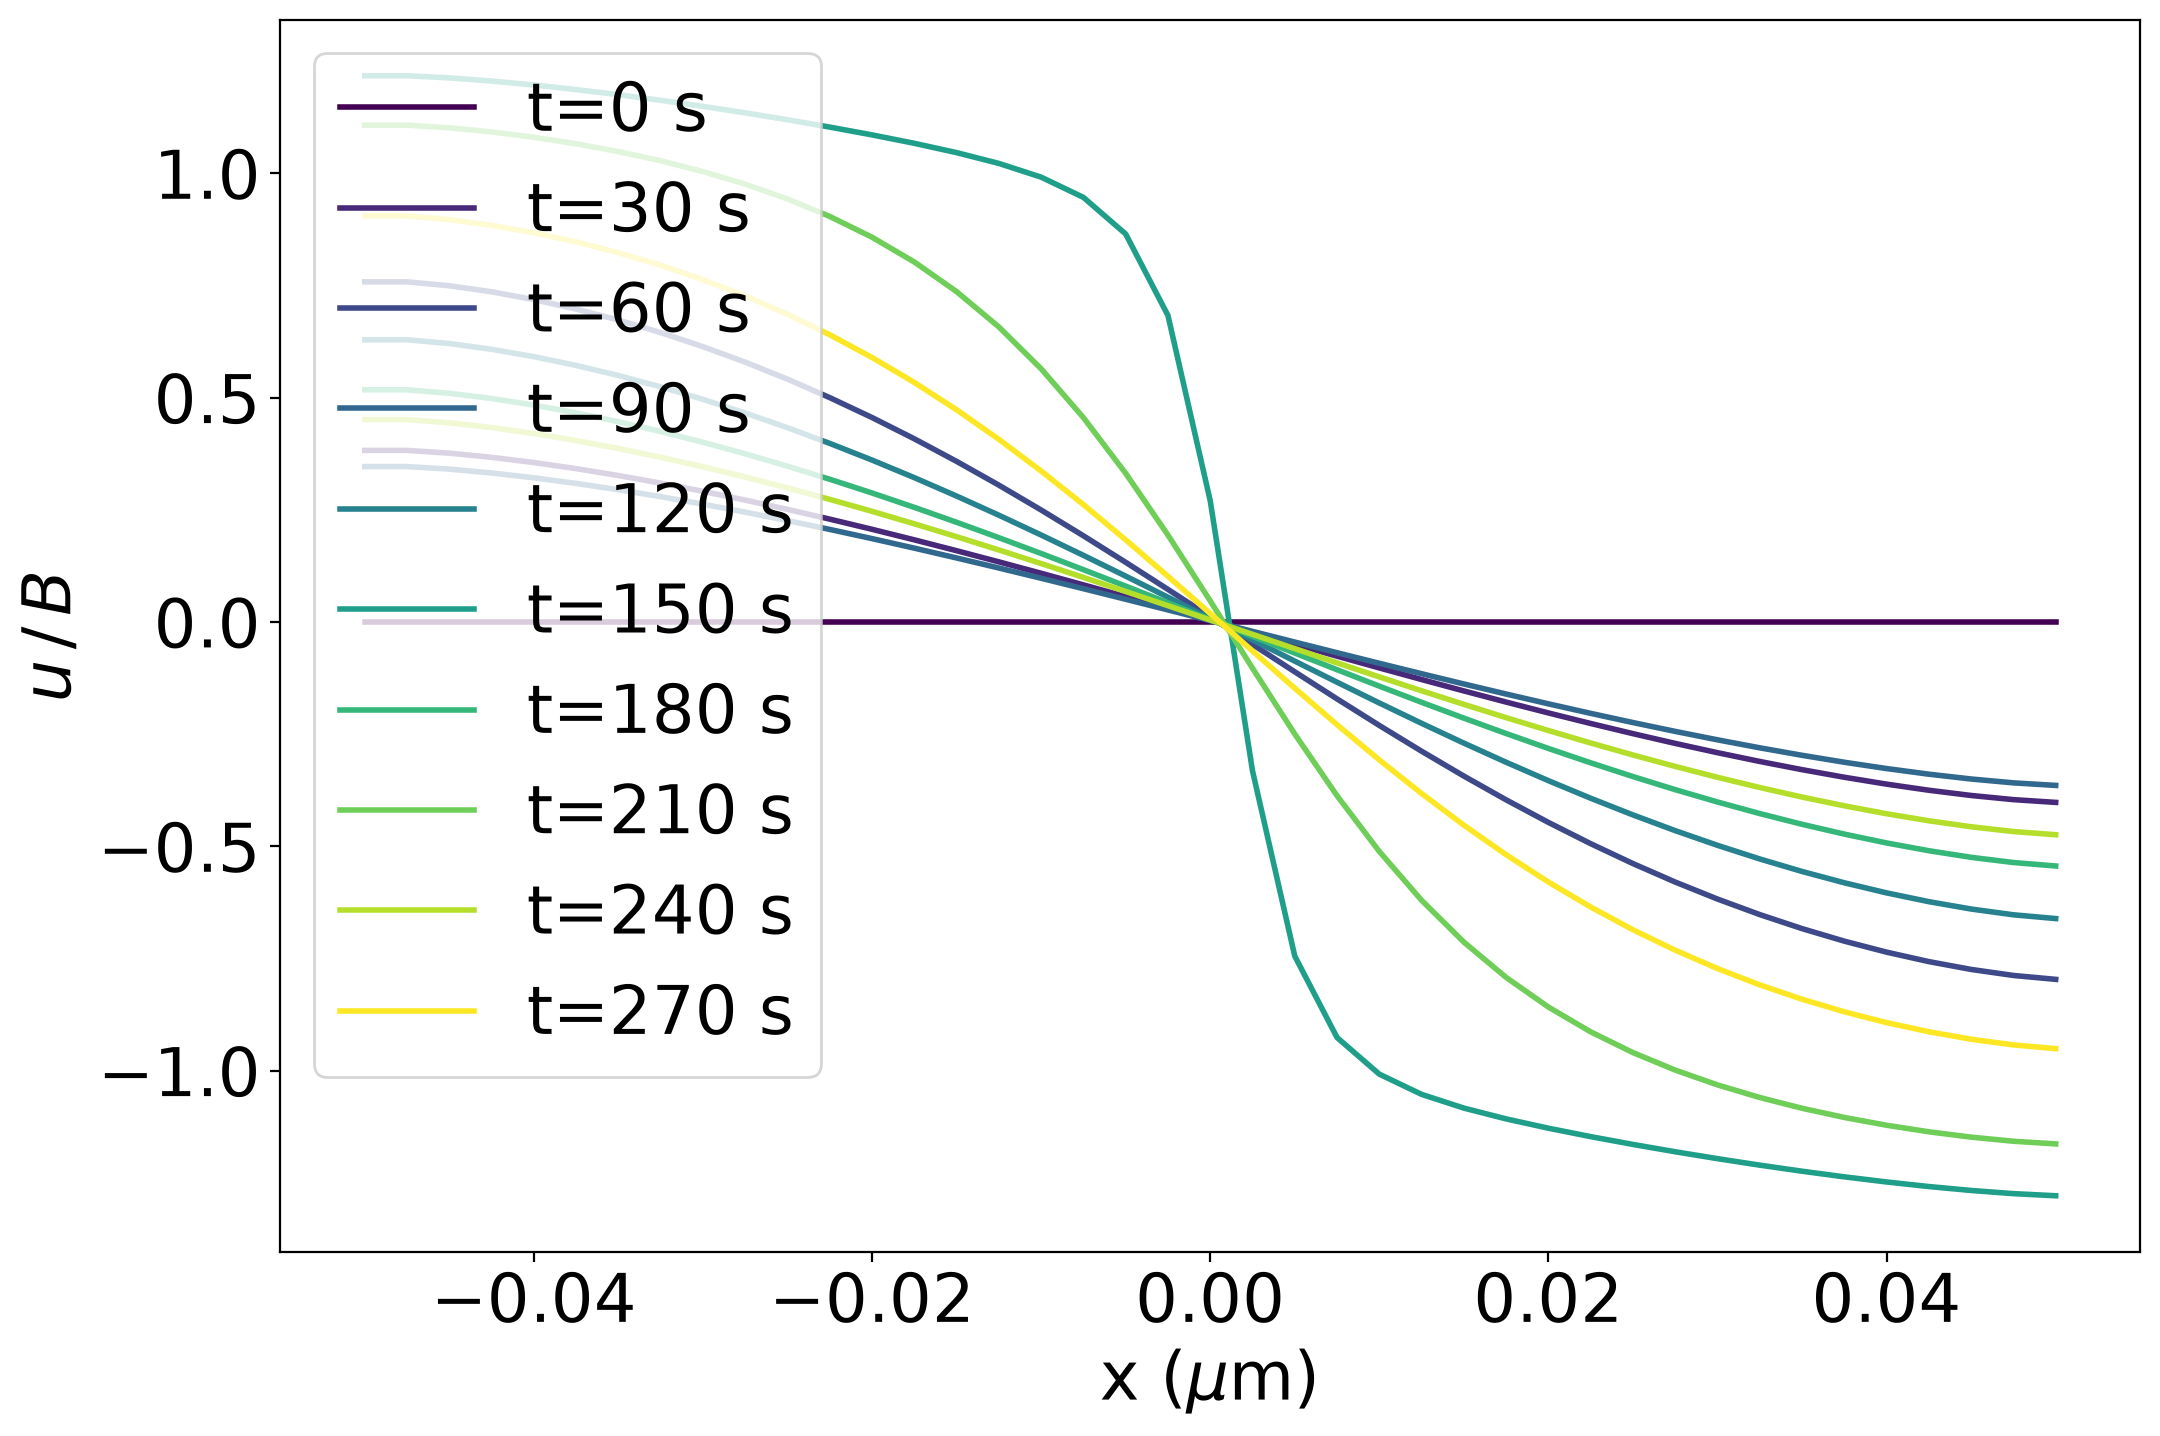

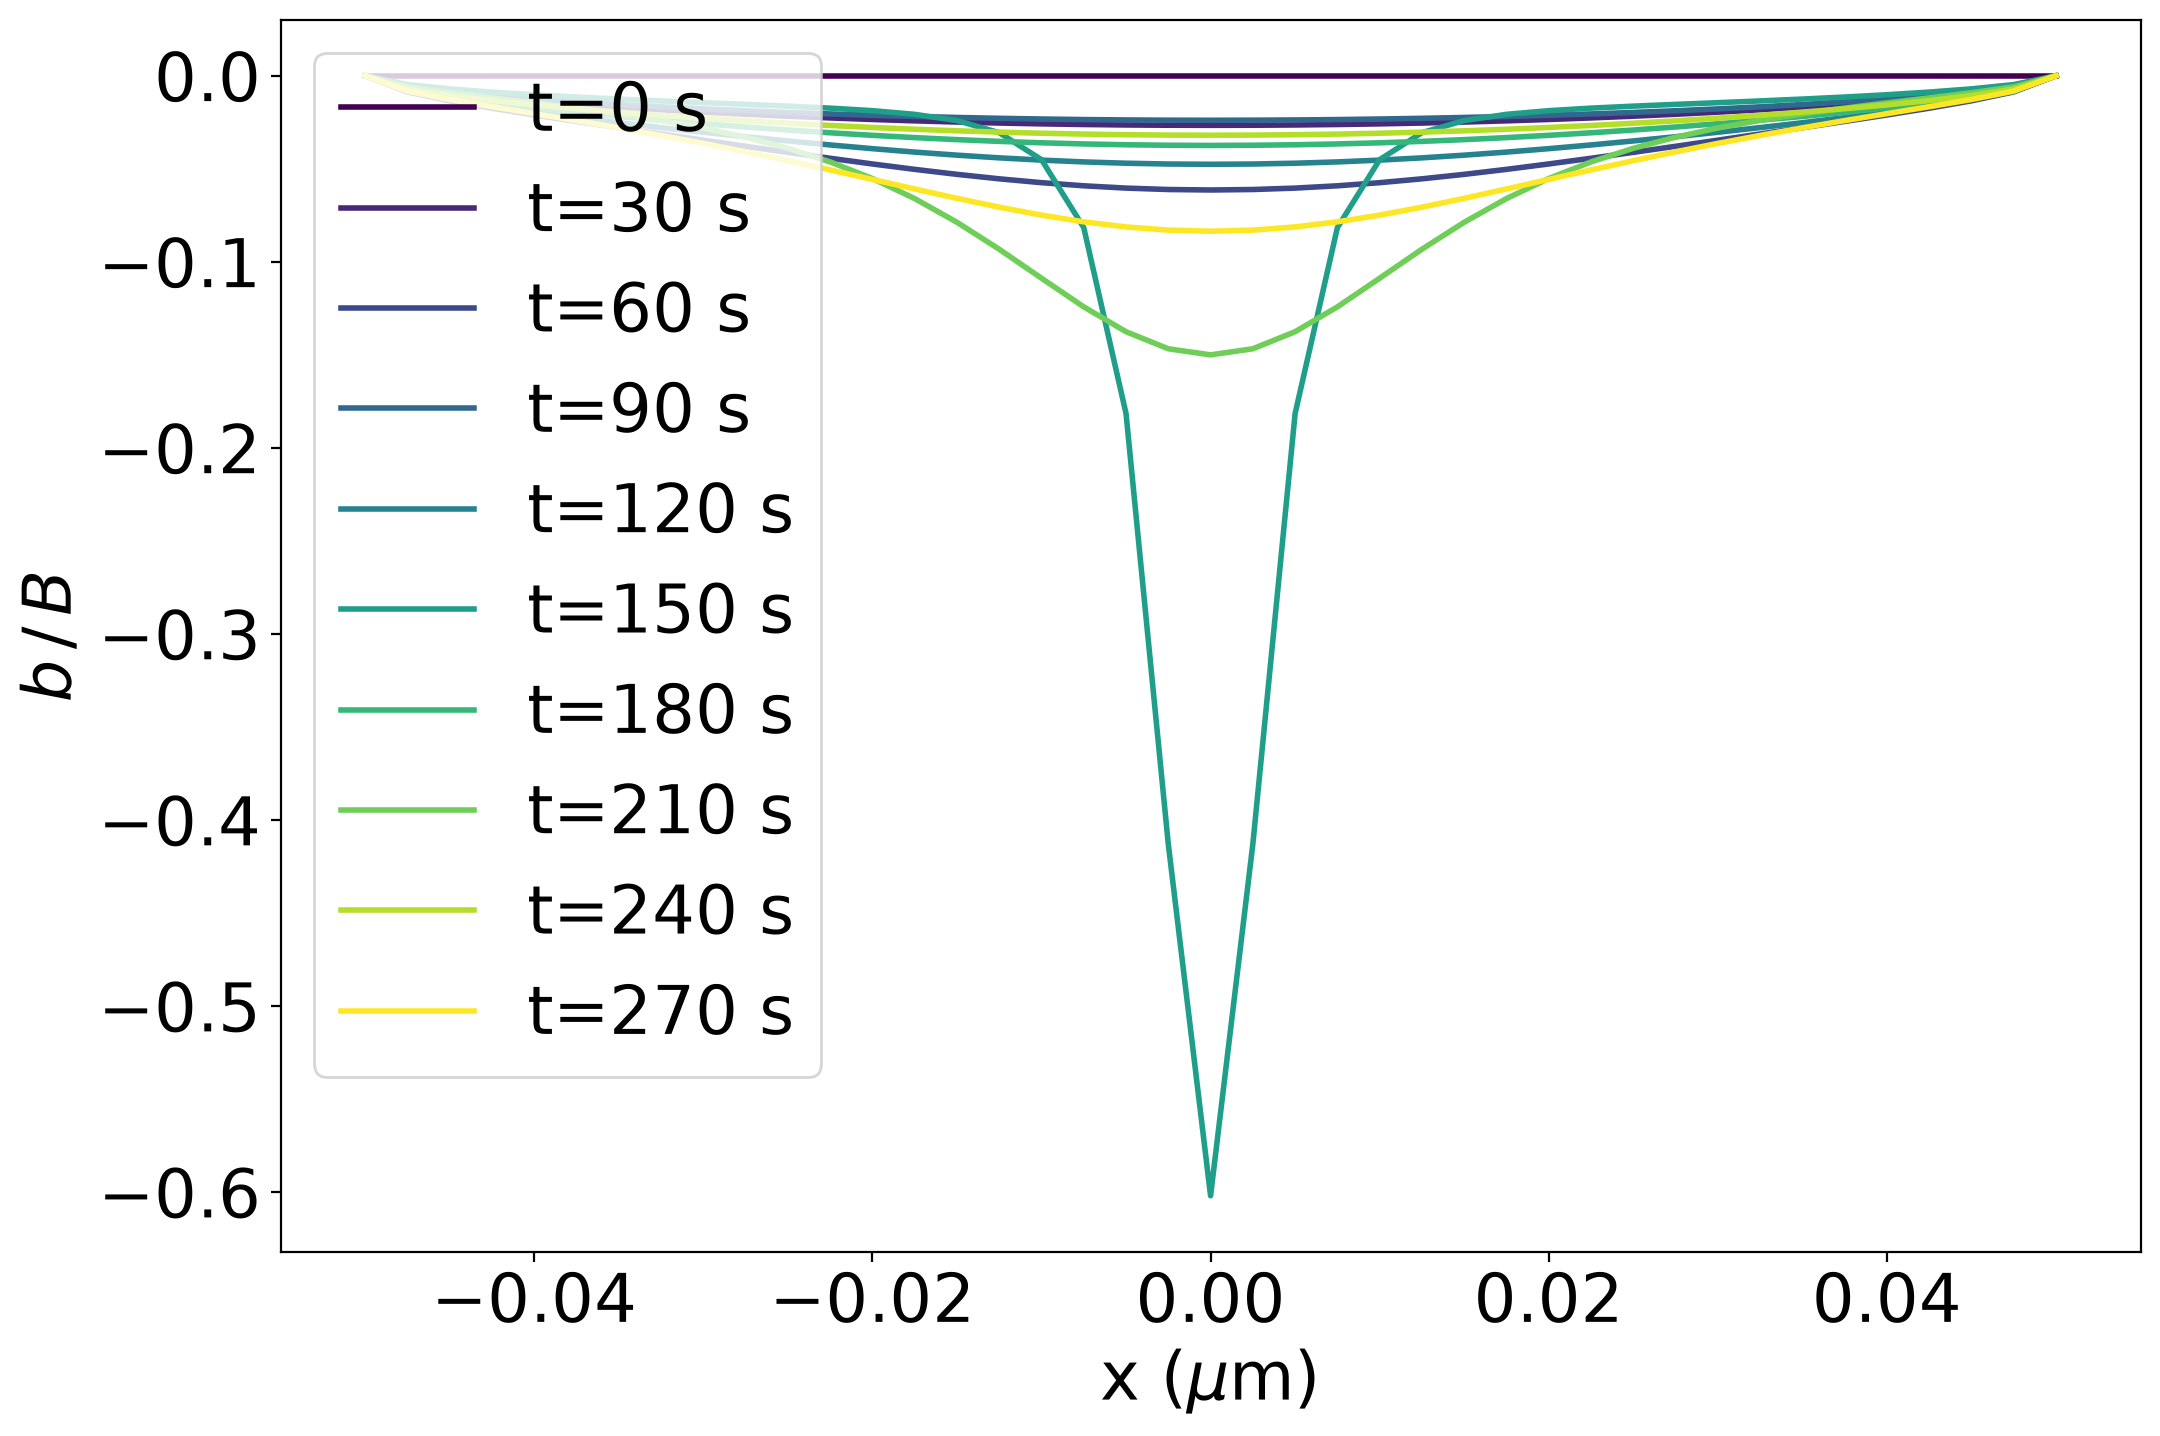

In [2]:
# if result files exits, read them
for i, fname in enumerate(flist):
    gbdd = dd.GB_dislocations(from_file="../data/"+fname+".h5")
    print(f"Data file with N_gbn={gbdd.Ngbn}, delta={gbdd.Dgp}, dtmax={gbdd.dtmax}")
    gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
    gbdd.plot_time_series('plast_slip_rate')
    gbdd.plot_time_series('psr_av')
    gbdd.plot_field('displacement')
    gbdd.plot_field('bfield')
    nit[i] = gbdd.nout
    Ngb_list[i] = gbdd.Ngbn
    sim_time[i, 0:gbdd.nout] = gbdd.sim_time
    psr_av[i, 0:gbdd.nout-1] = savgol_filter(gbdd.glob_data['psr_av'][:gbdd.nout-1], 
                                             window_length=25, 
                                             polyorder=1, 
                                             deriv=0)
    gplast[i, 0:gbdd.nout] = gbdd.glob_data['plastic_slip']
                          

In [ ]:
# run simulation chain
#nlist = [21]
Np = len(nlist)
for i, ngbn in enumerate(nlist):
    delta = lgb/(ngbn - 1)  # 0.005
    Ngb_list[i] = ngbn
    #dtmax = 6.25e-7/delta**4  # value 1.e4 for delta=0.005, 50. for PU
    print(f"Simulation with N_gbn={ngbn}, delta={delta}, dtmax={dtmax}")
    gbdd = dd.GB_dislocations(temp=temp, tau0=tau0,
                       Ngbn=ngbn, len_gb_seg=lgb, grain_size=grain_size,
                       tfin=tfin, niter=niter, maxout=maxout,
                       dtmax=dtmax, drag=drag,
                       Qact=95.0e3,
                       screenout=True)
    gbdd.run_sim()
    gbdd.save_hdf5(f"pu_tau{int(tau0)}_T{int(temp)}_N{ngbn}.h5")
    gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
    gbdd.plot_time_series('plast_slip_rate')
    gbdd.plot_field('displacement')
    gbdd.plot_field('bfield')
    nit[i] = gbdd.nout
    Ngb_list[i] = gbdd.Ngbn
    sim_time[i, 0:gbdd.nout] = gbdd.sim_time
    psr_av[i, 0:gbdd.nout-1] = savgol_filter(gbdd.glob_data['psr_av'][:gbdd.nout-1], 
                                             window_length=25, 
                                             polyorder=1, 
                                             deriv=0)
    gplast[i, 0:gbdd.nout] = gbdd.glob_data['plastic_slip']

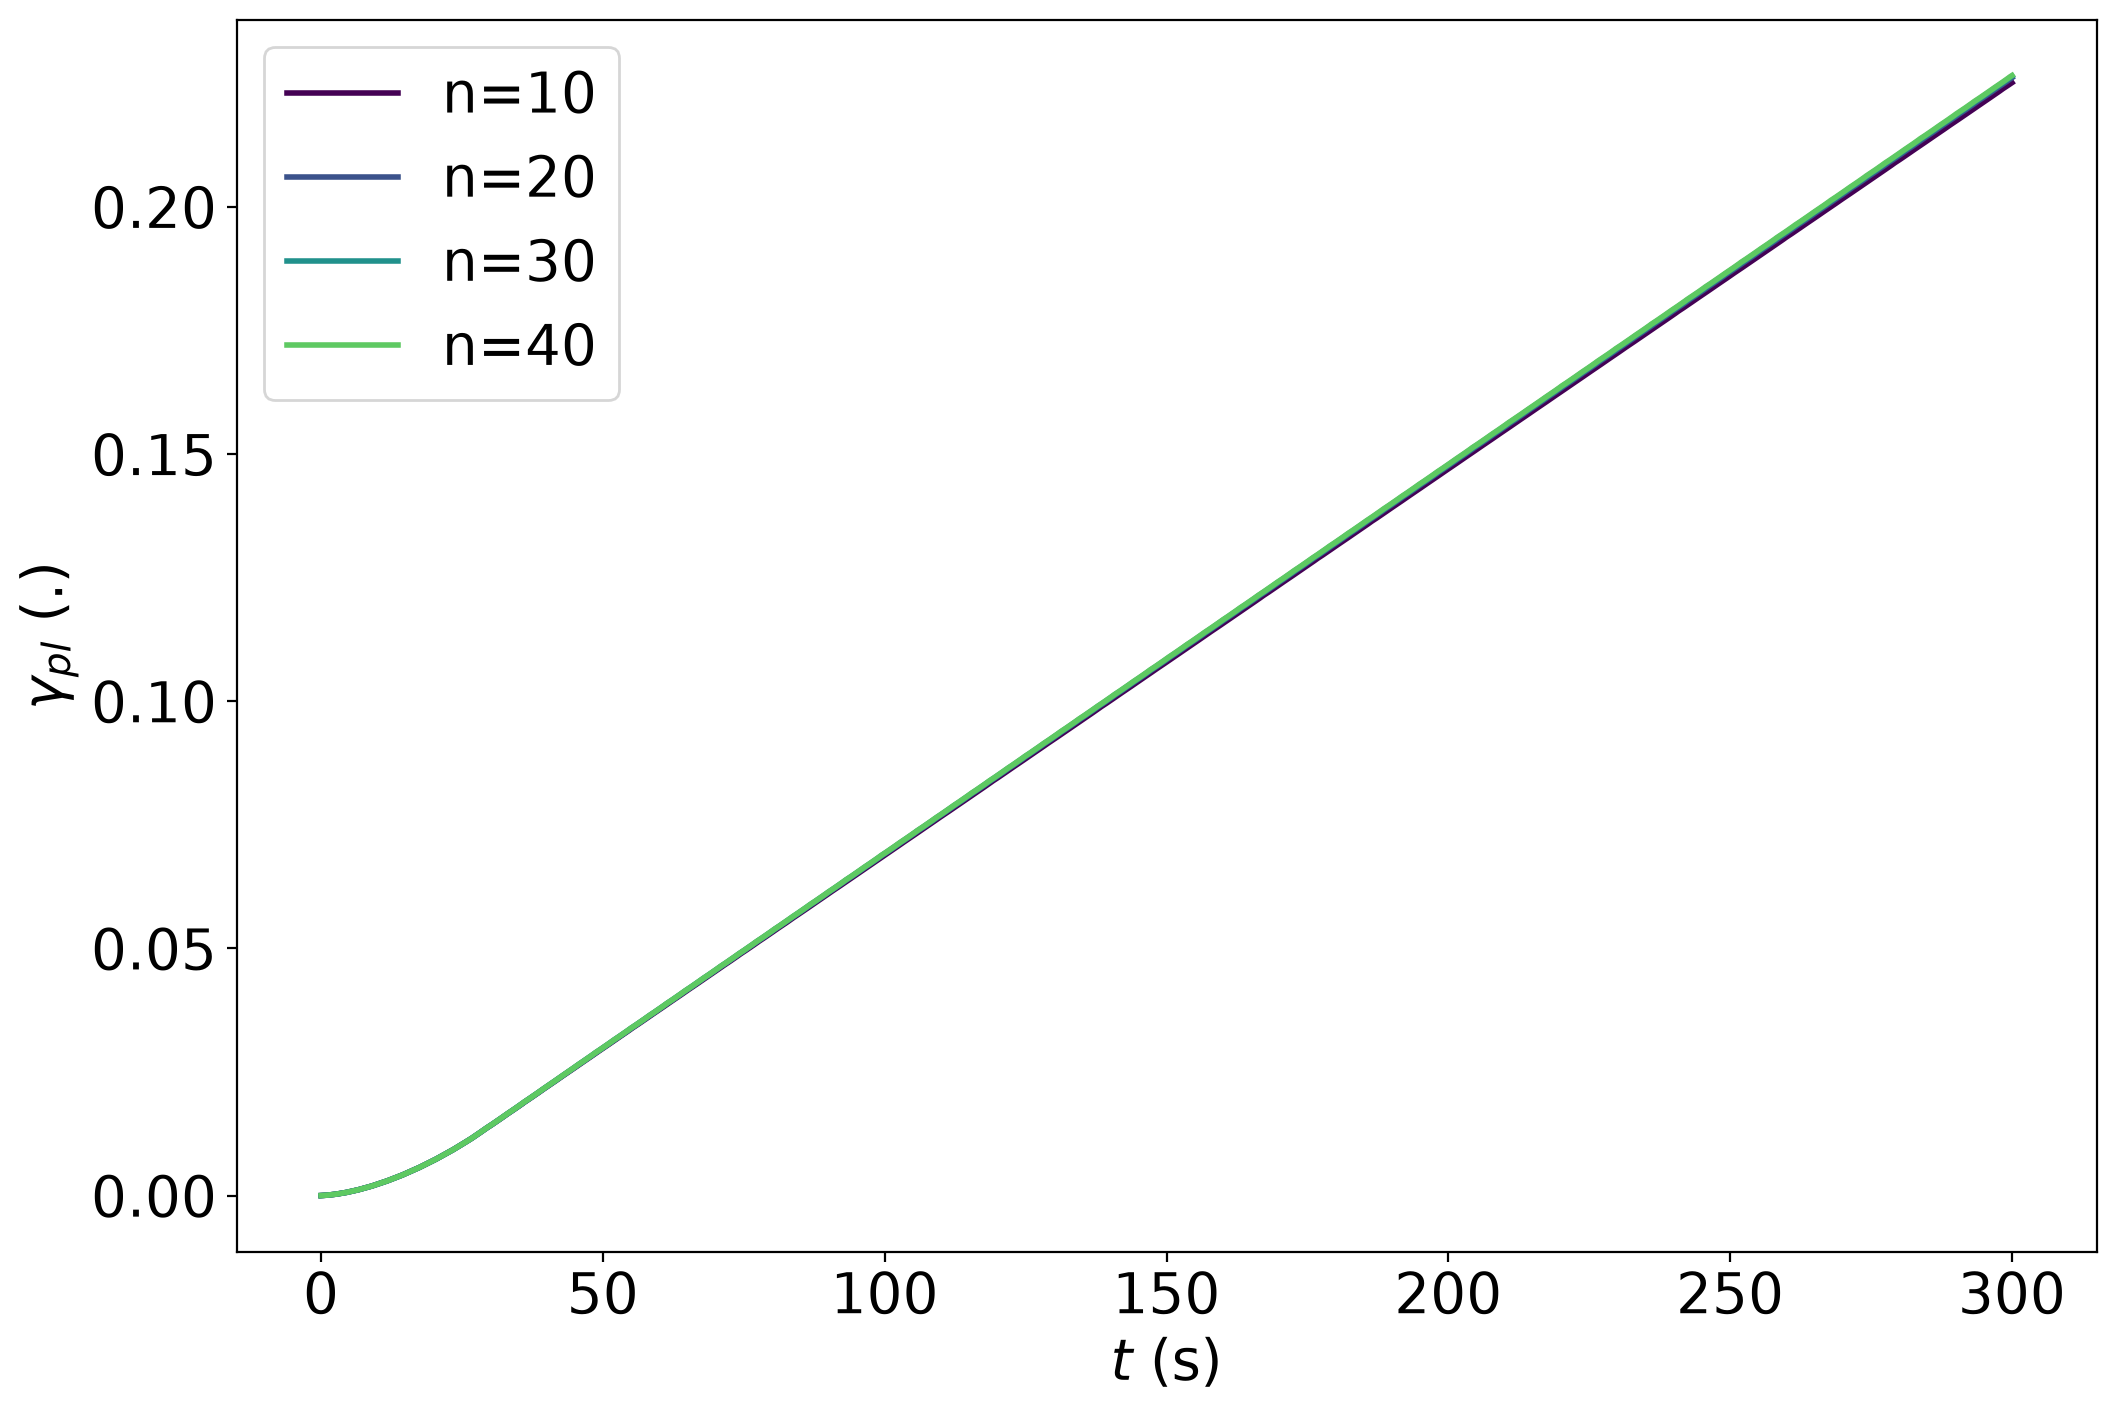

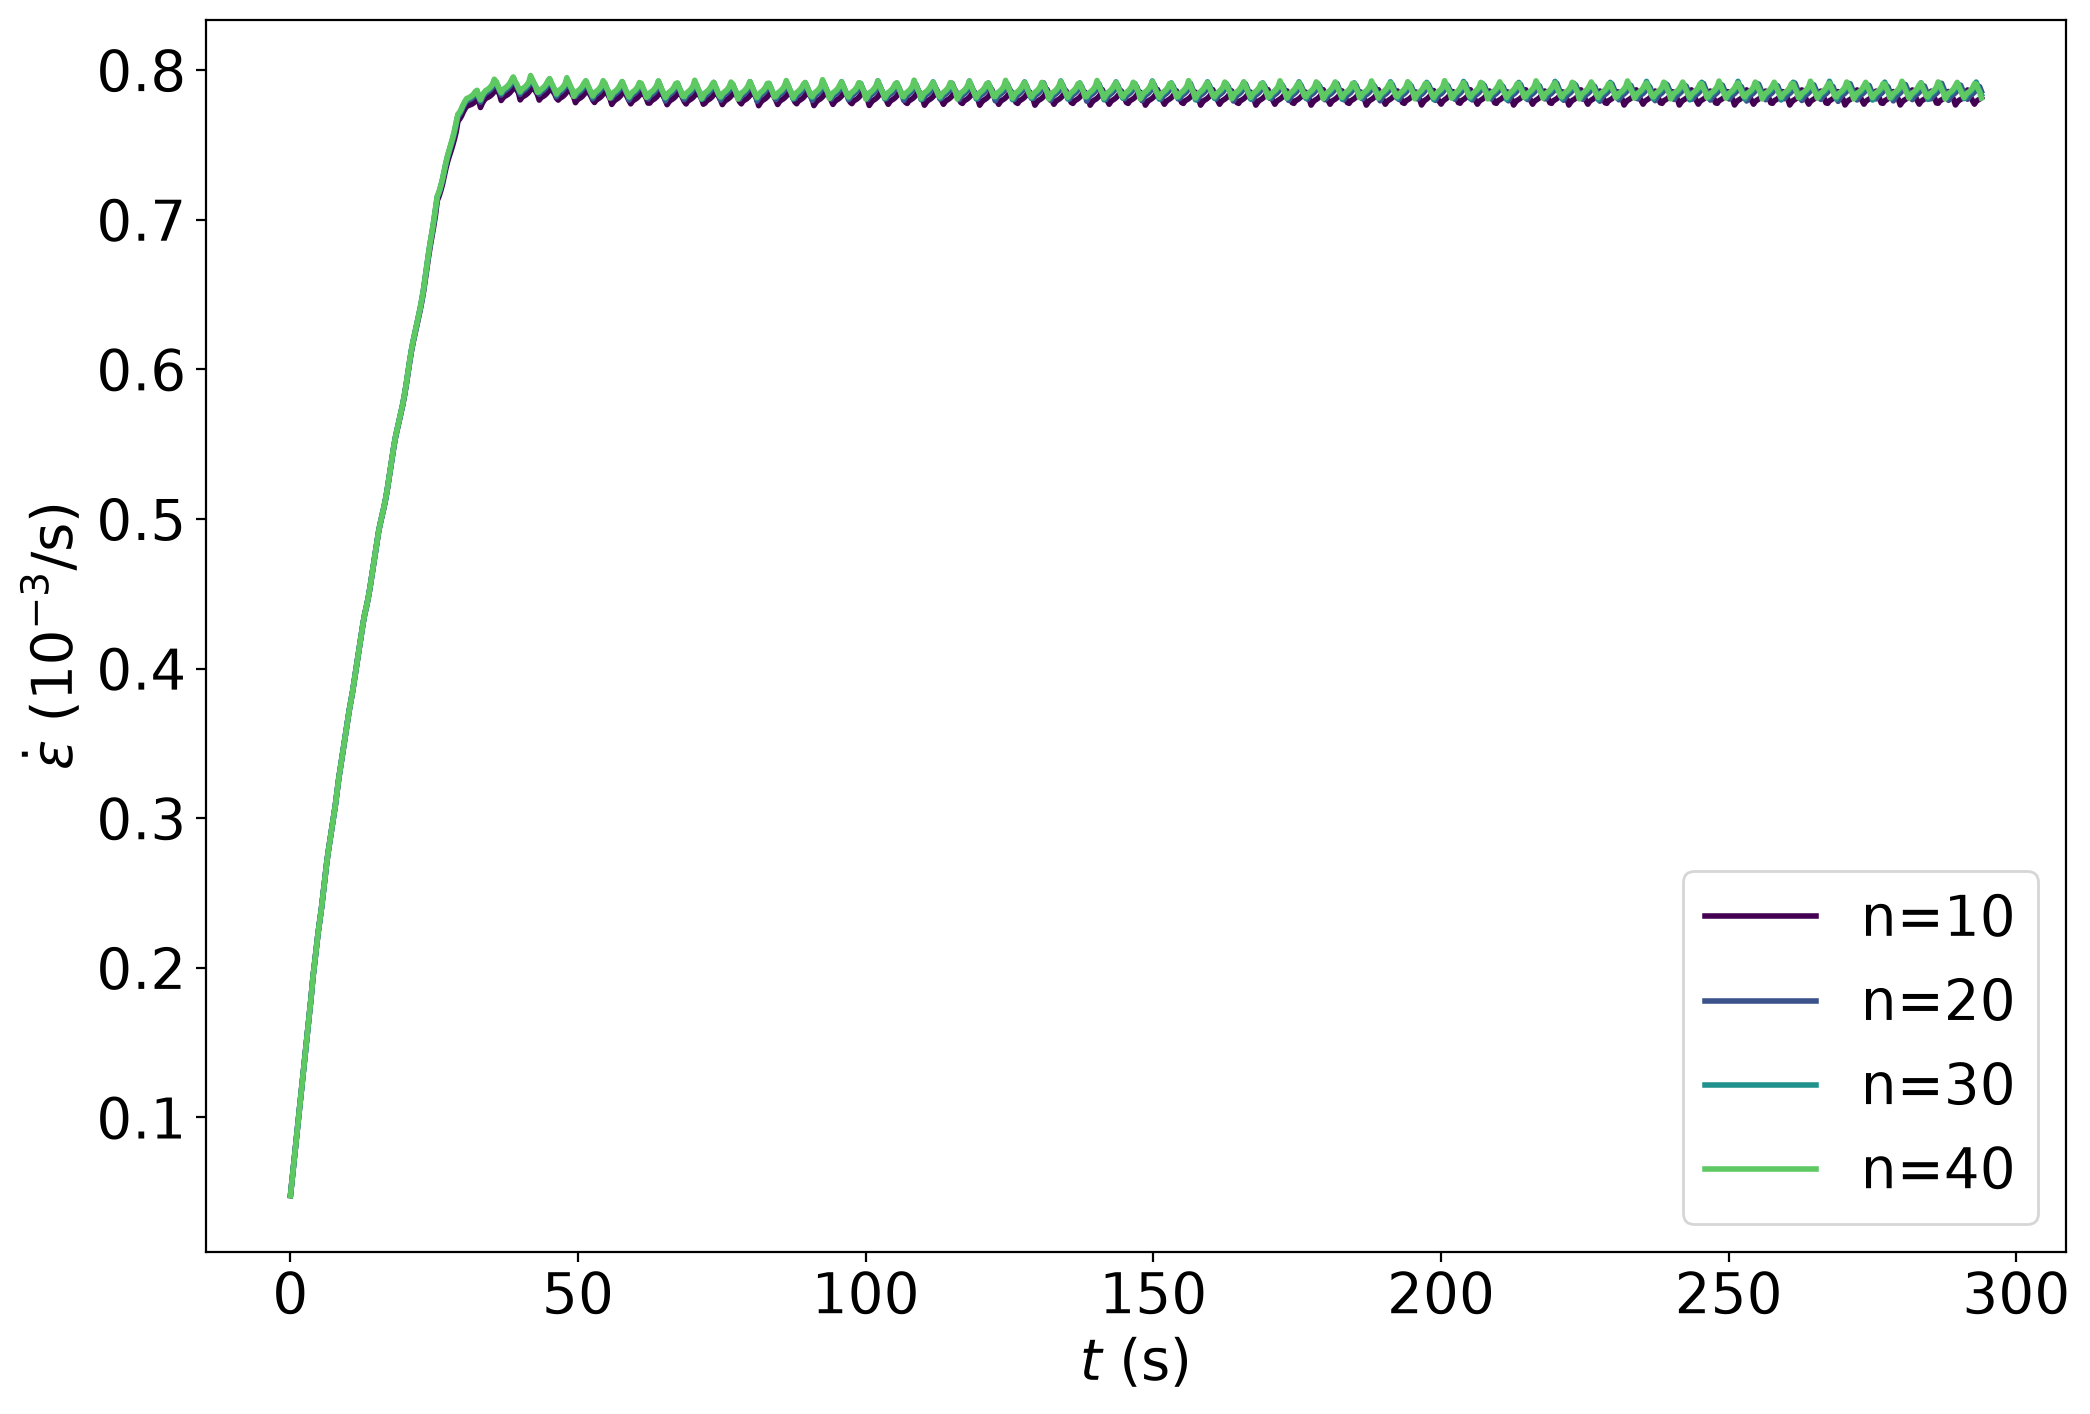

In [3]:
# analysze and plot results
plt.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize=(12, 8), dpi=200)
for i in range(Np):
    plt.plot(sim_time[i, :nit[i]]*1.e-6,
             gplast[i, :nit[i]],
             marker="none",
             linestyle="-",
             linewidth=2,
             color=plt.cm.viridis(i / max(1, Np)),
             label=f"n={Ngb_list[i]-1}"
             )
plt.legend()
plt.xlabel(r"$t$ (s)")
plt.ylabel(r"$\gamma_{pl}$ (.)")
#plt.savefig('pu_conv_gpl_ngbn.pdf', dpi=300, format='pdf')
plt.show()

fig, ax = plt.subplots(figsize=(12, 8), dpi=200)
for i in range(Np):
    plt.plot(sim_time[i, :nit[i]-20]*1.e-6,
             psr_av[i, :nit[i]-20]*1.e9,
             marker="none",
             linestyle="-",
             linewidth=2,
             color=plt.cm.viridis(i / max(1, Np)),
             label=f"n={Ngb_list[i]-1}"
             )
plt.legend()
plt.xlabel(r"$t$ (s)")
plt.ylabel(r"$\dot\varepsilon$ (10$^{-3}$/s)")
#plt.savefig('pu_conv_gd_ngbn.pdf', dpi=300, format='pdf')
plt.show()

Data file with N_gbn=21, delta=0.1, dtmax=1.0


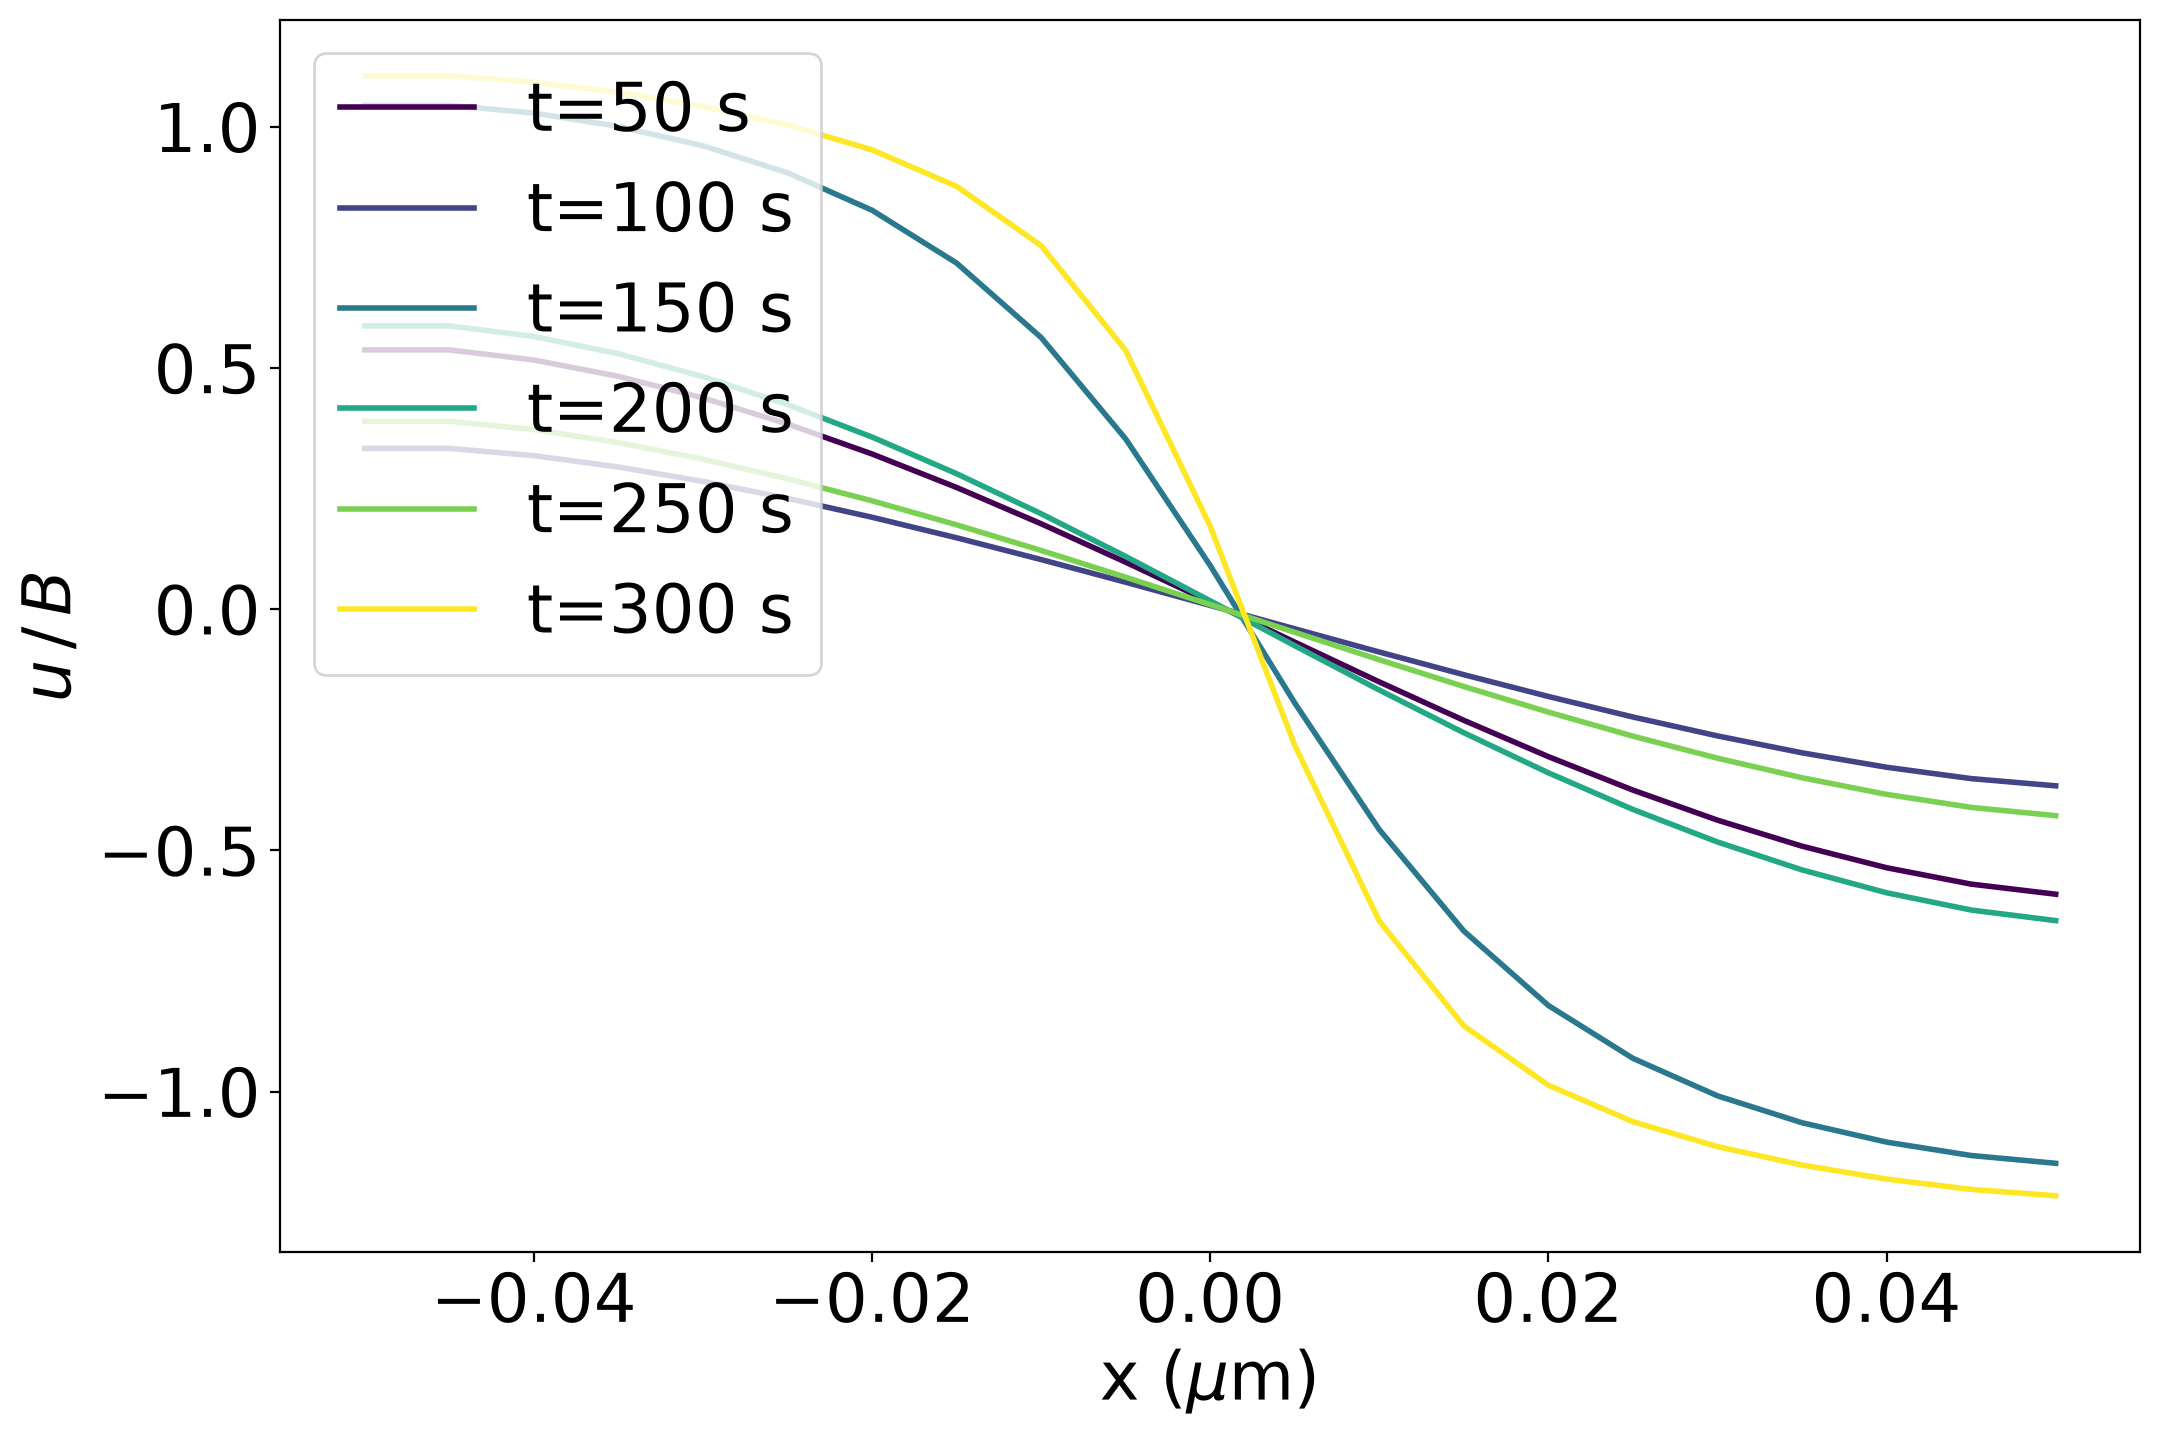

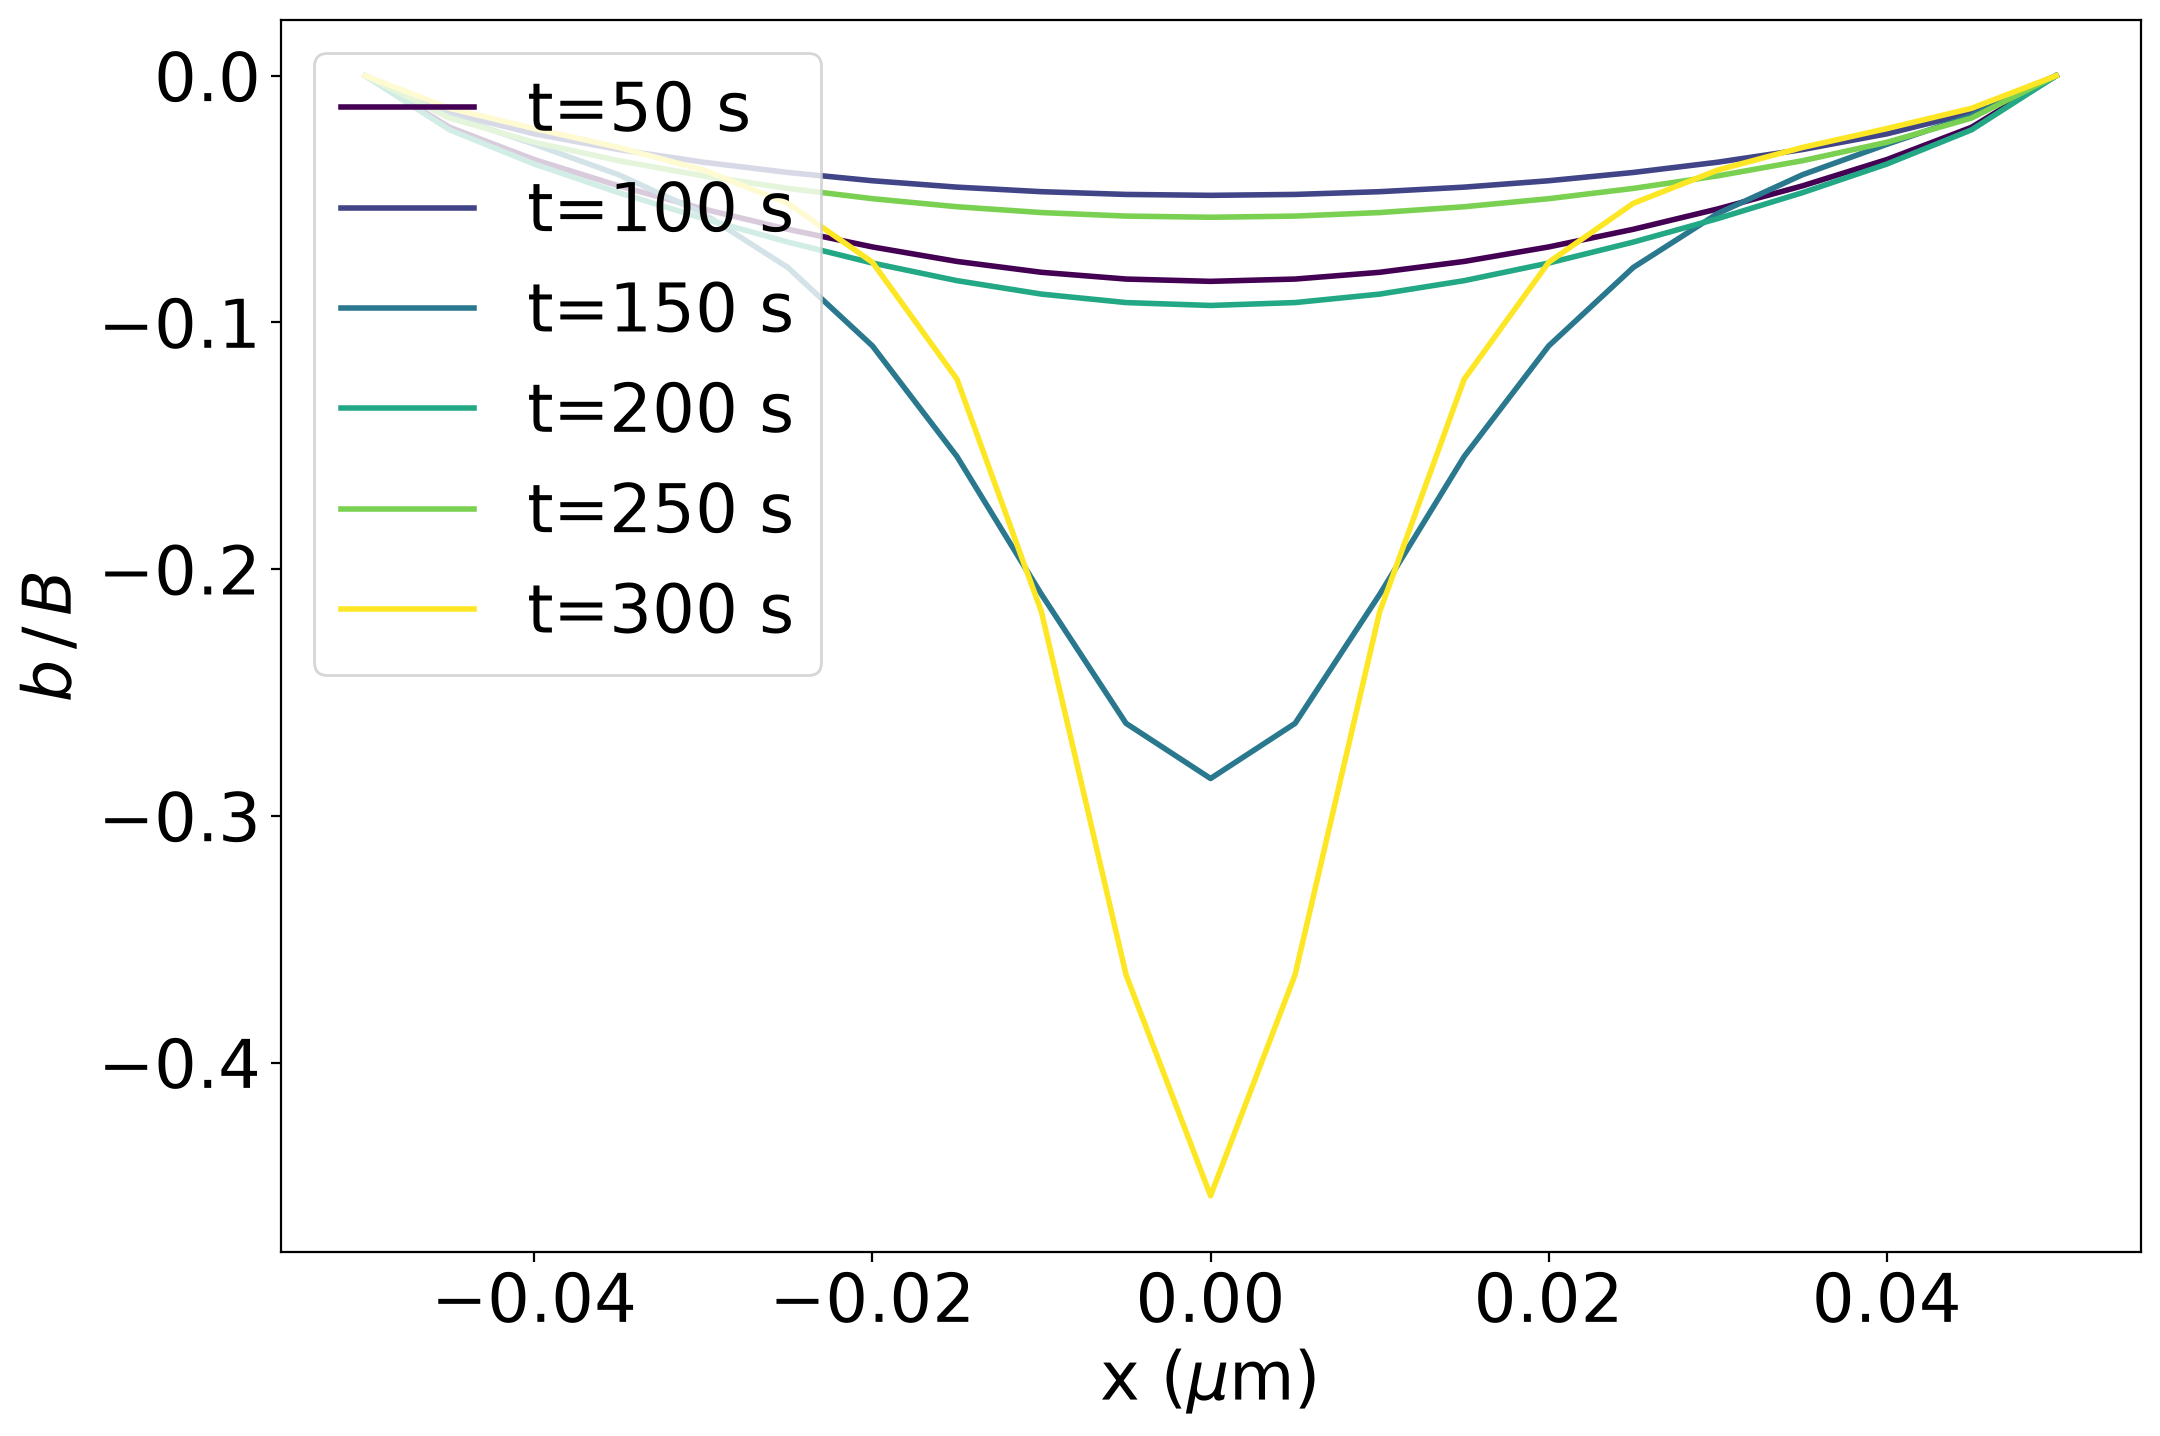

In [4]:
gbdd = dd.GB_dislocations(from_file="../data/pu_tau200_T600_N21.h5")
print(f"Data file with N_gbn={gbdd.Ngbn}, delta={gbdd.Dgp}, dtmax={gbdd.dtmax}")
t_=[50, 100, 150, 200, 250, 300]
gbdd.plot_field('displacement', times=t_, 
               file='F08a_displacement_tau150_T900_D10.pdf')
gbdd.plot_field('bfield', times=t_,
               file='F08b_bfield_tau150_T900_D10.pdf')

In [ ]:
gbdd.pu_dis['position'][-3:,:]